In [ ]:
import pandas as pd
import numpy as np
import pickle
import warnings

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import KFold

warnings.filterwarnings('ignore')
print('Environment Ready: Using Scikit-learn for Hybrid Filtering')

Environment Ready: Using Scikit-learn for Hybrid Filtering


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
movies_raw  = pd.read_csv("/content/drive/MyDrive/datasets/tmdb_5000_movies.csv")
credits_raw = pd.read_csv("/content/drive/MyDrive/datasets/tmdb_5000_credits.csv")
posters_raw = pd.read_csv("/content/drive/MyDrive/datasets/movies_tmdb_poster.csv")

In [ ]:
# 1. Merge datasets
movies = movies_raw.merge(credits_raw, on='title')
movies = movies.merge(posters_raw[['title', 'poster']], on='title', how='left')

movies.drop_duplicates(subset='title', inplace=True)

In [ ]:
movies = movies[[
        'movie_id', 'title', 'overview',
        'genres', 'keywords', 'cast', 'crew',
        'poster', 'vote_average', 'vote_count',
        'popularity', 'release_date'
]].copy()

In [ ]:
DEFAULT_POSTER = 'https://via.placeholder.com/500x750?text=No+Poster'
movies['poster']   = movies['poster'].fillna(DEFAULT_POSTER)
movies['overview'] = movies['overview'].fillna('')

movies.reset_index(drop=True, inplace=True)

In [ ]:
print(f'\n Merged dataset : {len(movies)} movies')
print(f'Columns        : {list(movies.columns)}')


 Merged dataset : 4800 movies
Columns        : ['movie_id', 'title', 'overview', 'genres', 'keywords', 'cast', 'crew', 'poster', 'vote_average', 'vote_count', 'popularity', 'release_date']


In [ ]:
display(movies.head(3))

,movie_id,title,overview,genres,keywords,cast,crew,poster,vote_average,vote_count,popularity,release_date
0,19995,Avatar,"In the 22nd century, a paraplegic Marine is di...","[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...","[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de...",https://image.tmdb.org/t/p/w500/jRXYjXNq0Cs2Tc...,7.2,11800,150.437577,2009-12-10
1,285,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...","[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...","[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de...",https://image.tmdb.org/t/p/w500/jGWpG4YhpQwVmj...,6.9,4500,139.082615,2007-05-19
2,206647,Spectre,A cryptic message from Bond’s past sends him o...,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...","[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de...",https://image.tmdb.org/t/p/w500/672kUEMtTHcaVY...,6.3,4466,107.376788,2015-10-26


In [ ]:
import ast

def extract_names(obj):
    try:
        return [i['name'] for i in ast.literal_eval(obj)]
    except:
        return []

def extract_top_cast(obj, n=3):
    try:
        return [i['name'] for i in ast.literal_eval(obj)[:n]]
    except:
        return []

def extract_director(obj):
    try:
        for i in ast.literal_eval(obj):
            if i.get('job') == 'Director':
                return [i['name']]
        return []
    except:
        return []

In [ ]:
# 1. Apply extraction functions
movies['genres_list']   = movies['genres'].apply(extract_names)
movies['keywords_list'] = movies['keywords'].apply(extract_names)
movies['cast_list']     = movies['cast'].apply(extract_top_cast)
movies['director']      = movies['crew'].apply(extract_director)
print(movies['genres_list'])

0       [Action, Adventure, Fantasy, Science Fiction]
1                        [Adventure, Fantasy, Action]
2                          [Action, Adventure, Crime]
3                    [Action, Crime, Drama, Thriller]
4                [Action, Adventure, Science Fiction]
                            ...                      
4795                        [Action, Crime, Thriller]
4796                                [Comedy, Romance]
4797               [Comedy, Drama, Romance, TV Movie]
4798                                               []
4799                                    [Documentary]
Name: genres_list, Length: 4800, dtype: object


In [ ]:
# Clean names (Remove spaces)
# This is a key step: "Johnny Depp" -> "JohnnyDepp"
def clean_names(name_list):
    if isinstance(name_list, list):
        return [name.replace(" ", "") for name in name_list]
    return []

movies['genres_list']   = movies['genres_list'].apply(clean_names)
movies['keywords_list'] = movies['keywords_list'].apply(clean_names)
movies['cast_list']     = movies['cast_list'].apply(clean_names)
movies['director']      = movies['director'].apply(clean_names)

In [ ]:
movies['tags'] = (
    movies['overview'].apply(lambda x: x.split()) +
    movies['genres_list'] +
    movies['keywords_list'] +
    movies['cast_list'] +
    movies['director']
)

print(movies['tags'])

# Convert list of tags back into a single lowercase string
movies['tags'] = movies['tags'].apply(lambda x: " ".join(x).lower())
print("\nAfter modification\n")
print(movies['tags'])

0       [In, the, 22nd, century,, a, paraplegic, Marin...
1       [Captain, Barbossa,, long, believed, to, be, d...
2       [A, cryptic, message, from, Bond’s, past, send...
3       [Following, the, death, of, District, Attorney...
4       [John, Carter, is, a, war-weary,, former, mili...
                              ...                        
4795    [El, Mariachi, just, wants, to, play, his, gui...
4796    [A, newlywed, couple's, honeymoon, is, upended...
4797    ["Signed,, Sealed,, Delivered", introduces, a,...
4798    [When, ambitious, New, York, attorney, Sam, is...
4799    [Ever, since, the, second, grade, when, he, fi...
Name: tags, Length: 4800, dtype: object

After modification

0       in the 22nd century, a paraplegic marine is di...
1       captain barbossa, long believed to be dead, ha...
2       a cryptic message from bond’s past sends him o...
3       following the death of district attorney harve...
4       john carter is a war-weary, former military ca...
           

In [ ]:
print(f'Sample tags for "{movies["title"].iloc[0]}":')
print(movies['tags'].iloc[0][:200] + "...")

Sample tags for "Avatar":
in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. action adventure fantasy...


In [ ]:
# ── TFIDF Vectorisation ─

tfidf = TfidfVectorizer(stop_words='english', max_features=10000)
tfidf_matrix = tfidf.fit_transform(movies['tags'])

print(f'TF-IDF matrix shape : {tfidf_matrix.shape}')

TF-IDF matrix shape : (4800, 10000)


In [ ]:
# ── Cosine Similarity Matrix ──
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

print(f'Cosine sim matrix shape : {cosine_sim.shape}')

Cosine sim matrix shape : (4800, 4800)


In [ ]:

title_to_idx = pd.Series(
    movies.index, index=movies['title']
).drop_duplicates()

print(f'Title index built : {len(title_to_idx)} entries')

Title index built : 4800 entries


In [ ]:
def get_cbf_recommendations(movie_title, n=10):
    if movie_title not in title_to_idx:
        print(f'Movie not found: "{movie_title}"')
        suggestions = movies[
            movies['title'].str.contains(movie_title, case=False, na=False)
        ]['title'].head(5).tolist()
        print('Suggestions:', suggestions)
        return pd.DataFrame()

    idx = title_to_idx[movie_title]

    scores = list(enumerate(cosine_sim[idx]))

    scores = sorted(scores, key=lambda x: x[1], reverse=True)

    scores = scores[1:n+1]

    movie_indices = [i[0] for i in scores]
    cbf_scores    = [round(i[1], 4) for i in scores]

    result = movies[['title', 'poster', 'vote_average', 'movie_id']].iloc[movie_indices].copy()
    result['cbf_score'] = cbf_scores
    result.reset_index(drop=True, inplace=True)
    return result

In [ ]:
# Quick test
print('\n- Test Content Based Filtering -')
test_res = get_cbf_recommendations('The Dark Knight', n=5)
if not test_res.empty:
    print(test_res[['title', 'cbf_score']])


- Test Content Based Filtering -
                                     title  cbf_score
0                    The Dark Knight Rises     0.4080
1                           Batman Returns     0.3375
2                            Batman Begins     0.3123
3  Batman: The Dark Knight Returns, Part 2     0.3111
4                           Batman Forever     0.2797


In [ ]:
# colaborative filtering
ratings_df = pd.read_csv(
    '/content/drive/MyDrive/datasets/movie lense/ratings.csv',
    usecols=['userId', 'movieId', 'rating'],
    dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32'}
)

links_df = pd.read_csv(
    '/content/drive/MyDrive/datasets/movie lense/links.csv',
    usecols=['movieId', 'tmdbId'],
    dtype={'movieId': 'int32', 'tmdbId': 'float64'}
)
print(ratings_df)
print("links:")
print(links_df)

          userId  movieId  rating
0              1      296     5.0
1              1      306     3.5
2              1      307     5.0
3              1      665     5.0
4              1      899     3.5
...          ...      ...     ...
25000090  162541    50872     4.5
25000091  162541    55768     2.5
25000092  162541    56176     2.0
25000093  162541    58559     4.0
25000094  162541    63876     5.0

[25000095 rows x 3 columns]
links:
       movieId    tmdbId
0            1     862.0
1            2    8844.0
2            3   15602.0
3            4   31357.0
4            5   11862.0
...        ...       ...
62418   209157  499546.0
62419   209159   63407.0
62420   209163  553036.0
62421   209169  162892.0
62422   209171   79513.0

[62423 rows x 2 columns]


In [ ]:
links_df['tmdbId'] = links_df['tmdbId'].fillna(0).astype(int)

In [ ]:
ratings_linked = ratings_df.merge(links_df, on='movieId', how='inner')

valid_tmdb_ids = movies['movie_id'].unique()
ratings_linked = ratings_linked[ratings_linked['tmdbId'].isin(valid_tmdb_ids)]

ratings_linked = ratings_linked.rename(
    columns={'userId': 'user_id', 'tmdbId': 'item_id'}
)[['user_id', 'item_id', 'rating']].copy()

In [ ]:
# ── Sub-sampling for Performance ─
SAMPLE_SIZE = 500_000
if len(ratings_linked) > SAMPLE_SIZE:
    ratings_linked = ratings_linked.sample(SAMPLE_SIZE, random_state=42)
    print(f'Sampled to {SAMPLE_SIZE} ratings')

ratings_linked.reset_index(drop=True, inplace=True)

Sampled to 500000 ratings


In [ ]:
print(f'Unique users: {ratings_linked["user_id"].nunique()}')
print(f'Unique movies: {ratings_linked["item_id"].nunique()}')

Unique users: 120920
Unique movies: 4189


In [ ]:
# Final Distribution Check
display(ratings_linked['rating'].value_counts().sort_index().to_frame().T)

rating,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0
count,7733,14427,8207,30661,25814,93082,65661,132813,47097,74505


In [ ]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

In [ ]:
# 1. Create the User-Item Pivot Table
# Rows = Users, Columns = Movie IDs, Values = Ratings
# We use fillna(0) because SVD needs a complete matrix
user_item_pivot = ratings_linked.pivot(
    index='user_id',
    columns='item_id',
    values='rating'
).fillna(0)

print(f'Pivot Table Shape: {user_item_pivot.shape} (Users x Movies)')

Pivot Table Shape: (120920, 4189) (Users x Movies)


In [ ]:
X = user_item_pivot.values.T

svd = TruncatedSVD(n_components=100, random_state=42)
item_factors = svd.fit_transform(X)

# explained_var = svd.explained_variance_ratio_.sum()

print(f'SVD training complete.')
# print(f'Total Variance Explained: {explained_var:.2%} (Aim for > 30% with 100 factors)')

SVD training complete.


In [ ]:
collab_sim = cosine_similarity(item_factors)

# This is vital for the FastAPI backend to know which row corresponds to which movie
collab_item_ids = list(user_item_pivot.columns)
item_id_to_collab_idx = {item_id: i for i, item_id in enumerate(collab_item_ids)}
print(collab_item_ids)
print(item_id_to_collab_idx)

[5, 11, 12, 13, 14, 16, 18, 19, 20, 22, 24, 25, 28, 33, 35, 38, 55, 58, 59, 62, 65, 66, 68, 69, 70, 71, 73, 74, 75, 76, 77, 78, 79, 80, 83, 85, 87, 89, 90, 95, 96, 98, 100, 103, 104, 105, 106, 107, 111, 114, 115, 116, 117, 118, 120, 121, 122, 128, 129, 134, 137, 141, 142, 146, 149, 152, 153, 154, 155, 157, 161, 162, 163, 165, 167, 168, 169, 170, 172, 173, 174, 176, 177, 179, 180, 182, 184, 186, 187, 189, 193, 194, 196, 197, 199, 200, 201, 203, 205, 207, 214, 215, 217, 218, 219, 223, 226, 227, 231, 235, 238, 239, 240, 242, 243, 245, 248, 251, 252, 253, 254, 257, 261, 268, 272, 274, 277, 278, 279, 280, 284, 285, 288, 289, 291, 292, 296, 297, 298, 302, 306, 309, 310, 311, 314, 319, 320, 321, 322, 326, 327, 329, 330, 331, 332, 334, 335, 338, 342, 345, 346, 348, 350, 364, 377, 380, 387, 388, 389, 391, 392, 393, 395, 398, 400, 401, 403, 404, 408, 409, 411, 414, 415, 421, 423, 424, 425, 429, 431, 433, 435, 436, 440, 451, 453, 454, 455, 462, 464, 468, 470, 473, 479, 480, 489, 492, 496, 497, 50

In [ ]:
def get_cf_scores_all(user_id):
    if user_id in user_item_pivot.index:
        user_idx_in_X = user_item_pivot.index.get_loc(user_id)

        user_latent_profile = svd.components_[:, user_idx_in_X]

        all_predicted_ratings = np.dot(item_factors, user_latent_profile)

        return all_predicted_ratings
    else:
        return np.full(len(user_item_pivot.columns), ratings_linked['rating'].mean())

In [ ]:
def get_cf_recommendations(user_id, n=10):
    rated_items = set(
        ratings_linked[ratings_linked['user_id'] == user_id]['item_id'].values
    )

    all_scores = get_cf_scores_all(user_id)

    item_ids = user_item_pivot.columns

    result_rows = []
    for i, tmdb_id in enumerate(item_ids):
        if tmdb_id not in rated_items:
            try:
                movie_idx = movies[movies['movie_id'] == tmdb_id].index[0]
                result_rows.append({
                    'movie_idx': movie_idx,
                    'predicted_rating': round(all_scores[i], 4)
                })
            except IndexError:
                continue

    result_rows = sorted(result_rows, key=lambda x: x['predicted_rating'], reverse=True)[:n]

    movie_indices = [r['movie_idx'] for r in result_rows]
    pred_ratings  = [r['predicted_rating'] for r in result_rows]

    result = movies[['title', 'poster', 'vote_average', 'movie_id']].iloc[movie_indices].copy()
    result['predicted_rating'] = pred_ratings
    result.reset_index(drop=True, inplace=True)
    return result

In [ ]:
# Quick test
sample_user = int(ratings_linked['user_id'].iloc[0])
print(f'Test Collaborative Filtering — Top 5 for user {sample_user}:')
test_cf = get_cf_recommendations(sample_user, n=5)
if not test_cf.empty:
    print(test_cf[['title', 'predicted_rating']])

Test Collaborative Filtering — Top 5 for user 152232:
                        title  predicted_rating
0                 Toy Story 2            0.4744
1          Dead Poets Society            0.3341
2              Mrs. Doubtfire            0.2349
3  Ace Ventura: Pet Detective            0.2326
4  O Brother, Where Art Thou?            0.2260


In [ ]:
sample_user = int(ratings_linked['user_id'].iloc[4])
print(f'Test Collaborative Filtering — Top 5 for user {sample_user}:')
test_cf = get_cf_recommendations(sample_user, n=5)
if not test_cf.empty:
    print(test_cf[['title', 'predicted_rating']])

Test Collaborative Filtering — Top 5 for user 128864:
            title  predicted_rating
0    The Departed            0.7967
1  V for Vendetta            0.7450
2       Cast Away            0.4465
3          WALL·E            0.3941
4    Donnie Darko            0.3795


In [ ]:
def normalise(arr):
    mn, mx = arr.min(), arr.max()
    if mx - mn < 1e-9:
        return np.zeros_like(arr)
    return (arr - mn) / (mx - mn)

In [ ]:
def hybrid_recommend(seed_movie, user_id=None, alpha=0.5, beta=0.5, n=10):
    if abs(alpha + beta - 1.0) > 0.0:
        raise ValueError(f'alpha + beta must equal 1 Got: {alpha+beta}')

    if seed_movie not in title_to_idx:
        print(f'Movie not found: "{seed_movie}"')
        return pd.DataFrame()

    seed_idx = title_to_idx[seed_movie]
    S_c = normalise(cosine_sim[seed_idx].copy())

    if user_id is not None:
        raw_S_cf = get_cf_scores_all(user_id)

        full_S_cf = np.zeros(len(movies))
        collab_item_ids = user_item_pivot.columns

        for i, tmdb_id in enumerate(collab_item_ids):
            try:
                master_idx = movies[movies['movie_id'] == tmdb_id].index[0]
                full_S_cf[master_idx] = raw_S_cf[i]
            except IndexError:
                continue

        S_cf = normalise(full_S_cf)
    else:
        # Cold-start fallback
        print(f'Note: Cold-start mode active for new user.')
        S_cf = np.zeros(len(movies))
        alpha, beta = 1.0, 0.0

    # Weighted Fusion
    S_final = (alpha * S_c) + (beta * S_cf)

    # Exclude the seed movie and already rated movies
    S_final[seed_idx] = -1.0
    if user_id is not None:
        rated_items = set(ratings_linked[ratings_linked['user_id'] == user_id]['item_id'].values)
        for i, tmdb_id in enumerate(movies['movie_id'].values):
            if tmdb_id in rated_items:
                S_final[i] = -1.0

    # Final Ranking
    top_idx = np.argsort(S_final)[::-1][:n]

    result = movies[['title', 'poster', 'vote_average', 'movie_id']].iloc[top_idx].copy()
    result['S_content'] = np.round(S_c[top_idx], 4)
    result['S_cf']      = np.round(S_cf[top_idx], 4)
    result['S_final']   = np.round(S_final[top_idx], 4)

    return result.reset_index(drop=True)

print('Hybrid recommender system is working perfectly')

Hybrid recommender system is working perfectly


In [ ]:
# Test 1: Known user + seed movie ─
print('TEST 1 — Hybrid (content + CF) for known user')
print('='*55)
# Using a sample user from our linked ratings
sample_user = int(ratings_linked['user_id'].sample(1, random_state=7).values[0])
print(f'User ID: {sample_user}')

recs1 = hybrid_recommend(
    seed_movie = 'Inception',
    user_id    = sample_user,
    alpha      = 0.5,
    beta       = 0.5,
    n          = 8
)
if not recs1.empty:
    print(recs1[['title', 'vote_average', 'S_content', 'S_cf', 'S_final']])

print('\n')

TEST 1 — Hybrid (content + CF) for known user
User ID: 73063
                                               title  vote_average  S_content  \
0                                       Pretty Woman           7.0     0.0000   
1                         E.T. the Extra-Terrestrial           7.3     0.0103   
2  Dr. Strangelove or: How I Learned to Stop Worr...           8.0     0.0000   
3                                   A Beautiful Mind           7.7     0.0236   
4                                          True Lies           6.8     0.0318   
5                                     Mrs. Doubtfire           7.0     0.0000   
6                Willy Wonka & the Chocolate Factory           7.4     0.0000   
7                                Mission: Impossible           6.7     0.0668   

     S_cf  S_final  
0  1.0000   0.5000  
1  0.8141   0.4122  
2  0.7302   0.3651  
3  0.6605   0.3421  
4  0.6168   0.3243  
5  0.6234   0.3117  
6  0.6202   0.3101  
7  0.5332   0.3000  




In [ ]:
# Test 2: New user (cold-start) ─
print('TEST 2 — Cold-start (new user, no rating history)')
print('='*55)

recs2 = hybrid_recommend(
    seed_movie = 'Inception',
    user_id    = None,     # simulate new user
    alpha      = 1.0,      # weight shifts fully to content
    beta       = 0.0,
    n          = 8
)
if not recs2.empty:
    print(recs2[['title', 'vote_average', 'S_content', 'S_cf', 'S_final']])

print('\n')

TEST 2 — Cold-start (new user, no rating history)
Note: Cold-start mode active for new user.
                 title  vote_average  S_content  S_cf  S_final
0              Don Jon           5.9     0.1480   0.0   0.1480
1       Blood and Wine           5.5     0.1138   0.0   0.1138
2             The East           6.5     0.1124   0.0   0.1124
3               Cypher           6.7     0.1078   0.0   0.1078
4               Hesher           6.7     0.1058   0.0   0.1058
5               Duplex           5.9     0.1029   0.0   0.1029
6  The Helix... Loaded           4.8     0.0980   0.0   0.0980
7             The Walk           6.9     0.0978   0.0   0.0978




In [ ]:
# Test 3: Content-heavy weights (α=0.7, β=0.3) ─
print('TEST 3 — Content-heavy weights (α=0.7, β=0.3)')
print('='*55)

recs3 = hybrid_recommend(
    seed_movie = 'The Dark Knight',
    user_id    = sample_user,
    alpha      = 0.7,
    beta       = 0.3,
    n          = 8
)
if not recs3.empty:
    print(recs3[['title', 'vote_average', 'S_content', 'S_cf', 'S_final']])

print('\n')

TEST 3 — Content-heavy weights (α=0.7, β=0.3)
                                     title  vote_average  S_content    S_cf  \
0                    The Dark Knight Rises           7.6     0.4080  0.2512   
1                           Batman Returns           6.6     0.3375  0.3344   
2                           Batman Forever           5.2     0.2797  0.4054   
3                             Pretty Woman           7.0     0.0000  1.0000   
4  Batman: The Dark Knight Returns, Part 2           7.9     0.3111  0.2729   
5                            Batman Begins           7.5     0.3123  0.2315   
6                                   Batman           7.0     0.2452  0.2611   
7               E.T. the Extra-Terrestrial           7.3     0.0063  0.8141   

   S_final  
0   0.3610  
1   0.3366  
2   0.3174  
3   0.3000  
4   0.2997  
5   0.2880  
6   0.2500  
7   0.2486  




In [ ]:
# Test 4: CF-heavy weights (α=0.3, β=0.7) ─
print('TEST 4 — CF-heavy weights (α=0.3, β=0.7)')
print('='*55)

recs4 = hybrid_recommend(
    seed_movie = 'The Dark Knight',
    user_id    = sample_user,
    alpha      = 0.3,
    beta       = 0.7,
    n          = 8
)
if not recs4.empty:
    print(recs4[['title', 'vote_average', 'S_content', 'S_cf', 'S_final']])

TEST 4 — CF-heavy weights (α=0.3, β=0.7)
                                               title  vote_average  S_content  \
0                                       Pretty Woman           7.0     0.0000   
1                         E.T. the Extra-Terrestrial           7.3     0.0063   
2  Dr. Strangelove or: How I Learned to Stop Worr...           8.0     0.0175   
3                                   A Beautiful Mind           7.7     0.0164   
4                                     Mrs. Doubtfire           7.0     0.0086   
5                Willy Wonka & the Chocolate Factory           7.4     0.0000   
6                                          True Lies           6.8     0.0060   
7                        Four Weddings and a Funeral           6.6     0.0015   

     S_cf  S_final  
0  1.0000   0.7000  
1  0.8141   0.5718  
2  0.7302   0.5164  
3  0.6605   0.4673  
4  0.6234   0.4389  
5  0.6202   0.4341  
6  0.6168   0.4336  
7  0.5965   0.4180  


In [ ]:
import re
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

In [ ]:
movies['genres_clean_lookup'] = [list(item) for item in movies['genres_list']]

movies['genres_list']   = movies['genres_list'].apply(clean_names)
movies['keywords_list'] = movies['keywords_list'].apply(clean_names)
movies['cast_list']     = movies['cast_list'].apply(clean_names)
movies['director']      = movies['director'].apply(clean_names)

In [ ]:
def clean_emotion_text(text):
    text = str(text).lower()
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [ ]:
emotion_train_raw = pd.read_csv("/content/drive/MyDrive/datasets/Movies_Reviews_modified_version1.csv/Movies_Reviews_modified_version1.csv")
emotion_train_raw['cleaned_text'] = emotion_train_raw['Reviews'].apply(clean_emotion_text)

print(emotion_train_raw.head())

   Unnamed: 0  Ratings                                            Reviews  \
0           0      3.0  It had some laughs, but overall the motivation...   
1           1      4.0  WAITING TO EXHALE Waiting, and waiting, and wa...   
2           2      4.0  Angela Basset was good as expected, but Whitne...   
3           3      5.0  The movie is okay, mediocre might even be the ...   
4           4      5.0  I got an opportunity to see Waiting To Exhale ...   

          movie_name                                           Resenhas  \
0  Waiting to Exhale  Riu algumas risadas, mas no geral a motivação ...   
1  Waiting to Exhale  ESPERANDO PARA EXALAR Esperando, e esperando, ...   
2  Waiting to Exhale  Angela Basset foi boa como o esperado, mas Whi...   
3  Waiting to Exhale  O filme é bom, medíocre pode até ser a palavra...   
4  Waiting to Exhale  Tive a oportunidade de ver Waiting To Exhale p...   

                           genres  \
0  ['Comedy', 'Drama', 'Romance']   
1  ['Comedy'

In [ ]:
EMOTION_GENRE_MAP = {
    "joy": ["Comedy", "Animation", "Family", "Fantasy"],
    "sadness": ["Drama", "Romance"],
    "anger": ["Action", "Thriller", "Crime"],
    "fear": ["Horror", "Mystery", "Thriller"],
    "anticipation": ["Adventure", "Sci-Fi", "Mystery"],
    "surprise": ["Mystery", "Sci-Fi", "Fantasy"]
}

In [ ]:
emotion_vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_emotion_tfidf = emotion_vectorizer.fit_transform(emotion_train_raw['cleaned_text'])
y_emotion = emotion_train_raw['emotion']

In [ ]:
base_svc = LinearSVC()
calibrated_classifier = CalibratedClassifierCV(estimator=base_svc, method='sigmoid', cv='prefit')

In [ ]:
base_svc.fit(X_emotion_tfidf, y_emotion)
calibrated_classifier.fit(X_emotion_tfidf, y_emotion)
emotion_classes = calibrated_classifier.classes_
print("Calibrated Emotion Tracking Pipeline Active!")

Calibrated Emotion Tracking Pipeline Active!


In [ ]:
movie_emotion_vectors = []
for idx, row in movies.iterrows():
    movie_text = str(row['overview'])
    cleaned_movie_text = clean_emotion_text(movie_text)
    movie_vectorized = emotion_vectorizer.transform([cleaned_movie_text])
    probabilities = calibrated_classifier.predict_proba(movie_vectorized)[0]
    movie_emotion_vectors.append(probabilities)

In [ ]:
movie_emotion_matrix = np.array(movie_emotion_vectors)
for i, emotion_name in enumerate(emotion_classes):
    movies[f'em_score_{emotion_name}'] = movie_emotion_matrix[:, i]
print("Offline database profiling complete! Emotion metrics written to movies DataFrame.")

Offline database profiling complete! Emotion metrics written to movies DataFrame.


In [ ]:
def generate_cascade_emotion_recommendations(user_mood_input, seed_movie, user_id, movies, candidate_pool_size=150, alpha=0.50, beta=0.50):
    cleaned_input = clean_emotion_text(user_mood_input)
    user_vectorized = emotion_vectorizer.transform([cleaned_input])
    user_probabilities = calibrated_classifier.predict_proba(user_vectorized)[0]

    movie_em_signals = movies[[f'em_score_{em}' for em in emotion_classes]].values
    mood_similarity_scores = np.dot(movie_em_signals, user_probabilities)

    temp_movies = movies.copy()
    temp_movies['mood_match_score'] = mood_similarity_scores

    candidates_df = temp_movies.sort_values(by='mood_match_score', ascending=False).head(candidate_pool_size).copy()

    if seed_movie not in title_to_idx:
        print(f'Movie not found: "{seed_movie}". Returning raw emotion match pool.')
        return candidates_df[['title', 'vote_average', 'mood_match_score']].head(10)

    seed_idx = title_to_idx[seed_movie]
    candidate_indices = candidates_df.index.tolist()

    S_c_full = cosine_sim[seed_idx]
    S_c_candidates = np.array([S_c_full[idx] for idx in candidate_indices])
    S_c_norm = normalise(S_c_candidates) if len(S_c_candidates) > 0 else S_c_candidates

    if user_id is not None:
        raw_S_cf = get_cf_scores_all(user_id)
        full_S_cf = np.zeros(len(movies))
        collab_item_ids = user_item_pivot.columns

        for i, tmdb_id in enumerate(collab_item_ids):
            try:
                master_idx = movies[movies['movie_id'] == tmdb_id].index[0]
                full_S_cf[master_idx] = raw_S_cf[i]
            except IndexError:
                continue

        S_cf_candidates = np.array([full_S_cf[idx] for idx in candidate_indices])
        S_cf_norm = normalise(S_cf_candidates) if len(S_cf_candidates) > 0 else S_cf_candidates
    else:
        print(f'Note: Cold-start mode active for new user profile.')
        S_cf_norm = np.zeros(len(candidates_df))
        alpha, beta = 1.00, 0.00

    S_final = (alpha * S_c_norm) + (beta * S_cf_norm)

    candidates_df['S_content'] = S_c_norm
    candidates_df['S_cf'] = S_cf_norm
    candidates_df['S_final'] = S_final

    output_columns = ['title', 'vote_average', 'mood_match_score', 'S_content', 'S_cf', 'S_final']
    return candidates_df.sort_values(by='S_final', ascending=False)[output_columns].head(10)

In [ ]:
print("Running Verification Test 1: Low/Exhausted Mood")
test_1 = generate_cascade_emotion_recommendations(
    user_mood_input="I have been working for hours and need a fun laugh",
    seed_movie="The Dark Knight",
    user_id=1,
    movies=movies
)
print(test_1)
print("\n" + "="*80 + "\n")

Running Verification Test 1: Low/Exhausted Mood
                                title  vote_average  mood_match_score  \
3817                         Defendor           6.5          0.705107   
3061                      Deuces Wild           5.5          0.716161   
51                        Pacific Rim           6.7          0.671988   
2393               Madea Goes to Jail           6.4          0.708044   
1428                  Superhero Movie           4.9          0.691075   
588   Wall Street: Money Never Sleeps           5.8          0.678857   
1503                           Takers           6.0          0.706864   
3252                   Drive Me Crazy           5.8          0.672263   
1254                       Get Carter           4.8          0.666045   
3358                      In Too Deep           6.2          0.666081   

      S_content  S_cf   S_final  
3817   1.000000   1.0  1.000000  
3061   0.556455   1.0  0.778228  
51     0.362092   1.0  0.681046  
2393   0.349

In [ ]:
print("Running Verification Test 2: High/Adventurous Mood")
test_2 = generate_cascade_emotion_recommendations(
    user_mood_input="I want an epic, mind-blowing adventure journey",
    seed_movie="Avatar",
    user_id=1,
    movies=movies
)
print(test_2)
print("\n" + "="*80 + "\n")

Running Verification Test 2: High/Adventurous Mood
                        title  vote_average  mood_match_score  S_content  \
3533                 Galaxina           3.3          0.405696   1.000000   
1610                    Hanna           6.5          0.395540   0.537749   
4223                 Repo Man           6.7          0.385980   0.494419   
1016           Kate & Leopold           6.0          0.444448   0.432921   
2654                 Automata           5.6          0.392579   0.429073   
4089    Gentleman's Agreement           6.8          0.396132   0.394636   
2755            Earth to Echo           5.7          0.402180   0.381930   
812                Pocahontas           6.7          0.432935   0.379857   
2789       The Emperor's Club           6.9          0.449500   0.346663   
139   Mission: Impossible III           6.5          0.409952   0.273885   

      S_cf   S_final  
3533   1.0  1.000000  
1610   1.0  0.768875  
4223   1.0  0.747210  
1016   1.0  0.716461

In [ ]:
print("Running Verification Test 3: Cold Start Mode Verification")
test_3 = generate_cascade_emotion_recommendations(
    user_mood_input="I want a dark, intense mystery or thriller",
    seed_movie="The Dark Knight",
    user_id=None,
    movies=movies
)
print(test_3)

Running Verification Test 3: Cold Start Mode Verification
Note: Cold-start mode active for new user profile.
                  title  vote_average  mood_match_score  S_content  S_cf  \
744      The Lego Movie           7.5          0.319410   1.000000   0.0   
4777        Dutch Kills           0.0          0.317340   0.822555   0.0   
3964        Point Blank           7.1          0.312713   0.663311   0.0   
1196       The Prestige           8.0          0.320700   0.623814   0.0   
817    American Wedding           6.0          0.332367   0.551325   0.0   
1735     Ghosts of Mars           4.8          0.344311   0.499922   0.0   
79           Iron Man 2           6.6          0.332926   0.455753   0.0   
408   Collateral Damage           5.5          0.318581   0.444448   0.0   
2492              Steel           4.3          0.342835   0.437922   0.0   
4396            Special           6.6          0.326458   0.434068   0.0   

       S_final  
744   1.000000  
4777  0.822555  
396

In [ ]:
# Real-Time Facial Emotion Recognition

!pip install deepface opencv-python-headless -q

In [ ]:
import cv2
import numpy as np
from deepface import DeepFace

26-11-06 07:27:08 - Directory /root/.deepface has been created
26-11-06 07:27:08 - Directory /root/.deepface/weights has been created


In [ ]:
result = DeepFace.analyze(
    img_path="/content/smile image.avif",
    actions=["emotion"],
    enforce_detection=False
)

print(result)

26-11-06 07:27:09 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 75.2MB/s]


[{'emotion': {'angry': np.float32(3.4866357), 'disgust': np.float32(0.00022017886), 'fear': np.float32(1.8582888), 'happy': np.float32(94.58197), 'sad': np.float32(0.05351064), 'surprise': np.float32(0.0003584656), 'neutral': np.float32(0.019011494)}, 'dominant_emotion': 'happy', 'region': {'x': 0, 'y': 0, 'w': 740, 'h': 592, 'left_eye': None, 'right_eye': None}, 'face_confidence': 0.0}]


In [ ]:
if isinstance(result, list):
    result = result[0]

emotion_scores = result["emotion"]

print(emotion_scores)
print("Dominant emotion:", result["dominant_emotion"])

{'angry': np.float32(3.4866357), 'disgust': np.float32(0.00022017886), 'fear': np.float32(1.8582888), 'happy': np.float32(94.58197), 'sad': np.float32(0.05351064), 'surprise': np.float32(0.0003584656), 'neutral': np.float32(0.019011494)}
Dominant emotion: happy


In [ ]:
FER_EMOTIONS = [
    "angry",
    "disgust",
    "fear",
    "happy",
    "sad",
    "surprise",
    "neutral"
]


def get_emotion_probabilities(frame):
    """
    Detect facial emotion from one image/frame.

    Returns:
        dict: emotion probabilities normalized to sum to 1.
    """

    result = DeepFace.analyze(
        img_path=frame,
        actions=["emotion"],
        enforce_detection=False
    )

    # DeepFace may return a list for multiple detected faces
    if isinstance(result, list):
        result = result[0]

    raw_scores = result["emotion"]

    # Ensure all expected emotions exist
    scores = np.array(
        [float(raw_scores.get(emotion, 0.0)) for emotion in FER_EMOTIONS],
        dtype=float
    )

    # Normalize scores into probabilities
    total = scores.sum()

    if total > 0:
        probabilities = scores / total
    else:
        probabilities = np.ones(len(FER_EMOTIONS)) / len(FER_EMOTIONS)

    return dict(zip(FER_EMOTIONS, probabilities))

In [ ]:
emotion_probs = get_emotion_probabilities("/content/smile image.avif")

print(emotion_probs)
print("Sum:", sum(emotion_probs.values()))

{'angry': np.float64(0.03486635843859807), 'disgust': np.float64(2.2017886934234066e-06), 'fear': np.float64(0.01858288849639445), 'happy': np.float64(0.94581974525128), 'sad': np.float64(0.0005351064225510648), 'surprise': np.float64(3.584656096441843e-06), 'neutral': np.float64(0.00019011494638659023)}
Sum: 0.9999999999999999


In [ ]:
## Common Emotion Representation

# To enable comparison between facial emotion predictions and movie emotion
# representations, both emotion sources are transformed into a shared
# five-dimensional emotion space:

# joy, sadness, anger, fear, and surprise.

COMMON_EMOTIONS = [
    "joy",
    "sadness",
    "anger",
    "fear",
    "surprise"
]

In [ ]:
def map_fer_to_common_emotions(fer_probs):
    """
    Maps facial emotion probabilities to the common
    five-dimensional emotion space.

    FER emotions:
        angry, disgust, fear, happy, sad, surprise, neutral

    Common emotions:
        joy, sadness, anger, fear, surprise
    """

    common_probs = {
        "joy": fer_probs.get("happy", 0.0),
        "sadness": fer_probs.get("sad", 0.0),
        "anger": fer_probs.get("angry", 0.0),
        "fear": fer_probs.get("fear", 0.0),
        "surprise": fer_probs.get("surprise", 0.0)
    }

    total = sum(common_probs.values())

    # Normalize within the common emotion space
    if total > 0:
        common_probs = {
            emotion: value / total
            for emotion, value in common_probs.items()
        }
    else:
        common_probs = {
            emotion: 1 / len(COMMON_EMOTIONS)
            for emotion in COMMON_EMOTIONS
        }

    return common_probs

In [ ]:
common_emotion_probs = map_fer_to_common_emotions(emotion_probs)

print(common_emotion_probs)
print("Sum:", sum(common_emotion_probs.values()))

{'joy': np.float64(0.9460016772052203), 'sadness': np.float64(0.0005352093522662769), 'anger': np.float64(0.03487306511262276), 'fear': np.float64(0.01858646298427227), 'surprise': np.float64(3.585345618405308e-06)}
Sum: 1.0


In [ ]:
print("Emotion classes:")
print(emotion_classes)

print("\nMovies dataframe columns:")
print(movies.columns.tolist())

Emotion classes:
['anger' 'anticipation' 'disgust' 'fear' 'joy' 'optimism' 'sadness'
 'surprise']

Movies dataframe columns:
['movie_id', 'title', 'overview', 'genres', 'keywords', 'cast', 'crew', 'poster', 'vote_average', 'vote_count', 'popularity', 'release_date', 'genres_list', 'keywords_list', 'cast_list', 'director', 'tags', 'genres_clean_lookup', 'em_score_anger', 'em_score_anticipation', 'em_score_disgust', 'em_score_fear', 'em_score_joy', 'em_score_optimism', 'em_score_sadness', 'em_score_surprise']


In [ ]:
print("\nPossible emotion-related variables:")

for name in [
    "movie_emotion_vectors",
    "movie_emotions",
    "movie_emotion_probs",
    "movie_emotion_matrix"
]:
    if name in globals():
        value = globals()[name]
        print(f"\n{name}:")
        print("Type:", type(value))

        try:
            print("Shape:", value.shape)
        except:
            pass


Possible emotion-related variables:

movie_emotion_vectors:
Type: <class 'list'>

movie_emotion_matrix:
Type: <class 'numpy.ndarray'>
Shape: (4800, 8)


In [ ]:
print("movie_emotion_matrix shape:", movie_emotion_matrix.shape)

print("\nFirst movie emotion vector:")
print(movie_emotion_vectors[0])

print("\nFirst 5 movie emotion vectors:")
for i, vec in enumerate(movie_emotion_vectors[:5]):
    print(i, vec)

movie_emotion_matrix shape: (4800, 8)

First movie emotion vector:
[1.75227335e-01 5.40077677e-01 1.57473422e-05 8.75488549e-04
 1.24233319e-03 6.02405369e-02 2.22289363e-01 3.15194207e-05]

First 5 movie emotion vectors:
0 [1.75227335e-01 5.40077677e-01 1.57473422e-05 8.75488549e-04
 1.24233319e-03 6.02405369e-02 2.22289363e-01 3.15194207e-05]
1 [2.22940901e-05 6.00654580e-02 3.21071276e-04 2.85565375e-04
 1.58427460e-01 2.00103948e-01 5.80771579e-01 2.62456150e-06]
2 [2.54176881e-02 4.85482535e-02 3.49196010e-05 1.63241435e-01
 2.12967691e-03 4.78045260e-01 2.82581770e-01 9.97735621e-07]
3 [1.75286928e-01 3.16490373e-02 4.00788409e-05 3.80788872e-01
 2.11909397e-01 1.83667019e-01 1.66363382e-02 2.23284765e-05]
4 [2.86136618e-06 7.35658739e-03 1.39119712e-02 6.55161715e-04
 6.44159775e-02 1.31562849e-02 9.00482687e-01 1.84685274e-05]


In [ ]:
print("\nEmotion classes:")
print(emotion_classes)


Emotion classes:
['anger' 'anticipation' 'disgust' 'fear' 'joy' 'optimism' 'sadness'
 'surprise']


In [ ]:
# Common emotion space shared by the webcam FER system and movie emotions

COMMON_EMOTIONS = [
    "joy",
    "sadness",
    "anger",
    "fear",
    "surprise"
]

# Map emotion name -> column index in the existing movie_emotion_matrix
movie_emotion_indices = {
    emotion: np.where(emotion_classes == emotion)[0][0]
    for emotion in COMMON_EMOTIONS
}

print("Movie emotion indices:")
print(movie_emotion_indices)

Movie emotion indices:
{'joy': np.int64(4), 'sadness': np.int64(6), 'anger': np.int64(0), 'fear': np.int64(3), 'surprise': np.int64(7)}


In [ ]:
# Extract only the emotions shared with the webcam FER representation

common_movie_emotion_matrix = np.column_stack([
    movie_emotion_matrix[:, movie_emotion_indices[emotion]]
    for emotion in COMMON_EMOTIONS
])

print("Original movie emotion matrix shape:")
print(movie_emotion_matrix.shape)

print("\nCommon movie emotion matrix shape:")
print(common_movie_emotion_matrix.shape)

print("\nFirst movie vector:")
print(common_movie_emotion_matrix[0])

print("\nSum of first movie vector:")
print(common_movie_emotion_matrix[0].sum())

Original movie emotion matrix shape:
(4800, 8)

Common movie emotion matrix shape:
(4800, 5)

First movie vector:
[1.24233319e-03 2.22289363e-01 1.75227335e-01 8.75488549e-04
 3.15194207e-05]

Sum of first movie vector:
0.3996660389990821


In [ ]:
# Normalize each movie's emotion vector within the common 5-emotion space

row_sums = common_movie_emotion_matrix.sum(axis=1, keepdims=True)

# Avoid division by zero
common_movie_emotion_matrix = np.divide(
    common_movie_emotion_matrix,
    row_sums,
    out=np.zeros_like(common_movie_emotion_matrix),
    where=row_sums != 0
)

print("First normalized movie vector:")
print(common_movie_emotion_matrix[0])

print("\nFirst vector sum:")
print(common_movie_emotion_matrix[0].sum())

print("\nMatrix shape:")
print(common_movie_emotion_matrix.shape)

First normalized movie vector:
[3.10842821e-03 5.56187771e-01 4.38434386e-01 2.19055027e-03
 7.88643959e-05]

First vector sum:
1.0

Matrix shape:
(4800, 5)


In [ ]:
print("Emotion order:")
print(COMMON_EMOTIONS)

print("\nFirst 5 normalized movie emotion vectors:")

for i in range(5):
    print(i, common_movie_emotion_matrix[i])

Emotion order:
['joy', 'sadness', 'anger', 'fear', 'surprise']

First 5 normalized movie emotion vectors:
0 [3.10842821e-03 5.56187771e-01 4.38434386e-01 2.19055027e-03
 7.88643959e-05]
1 [2.14233157e-01 7.85346992e-01 3.01471305e-05 3.86155102e-04
 3.54905708e-06]
2 [4.49895401e-03 5.96955520e-01 5.36950038e-02 3.44848415e-01
 2.10772190e-06]
3 [2.70070801e-01 2.12024065e-02 2.23396799e-01 4.85301536e-01
 2.84568293e-05]
4 [6.67125465e-02 9.32586844e-01 2.96338007e-06 6.78519648e-04
 1.91269703e-05]


In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import cv2
import numpy as np

In [ ]:
def take_photo(quality=0.8):
    js = Javascript('''
    async function takePhoto(quality) {
        const div = document.createElement('div');

        const video = document.createElement('video');
        video.style.display = 'block';

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        document.body.appendChild(div);
        div.appendChild(video);

        video.srcObject = stream;
        await video.play();

        // Give the camera a moment to initialize
        await new Promise((resolve) => setTimeout(resolve, 1000));

        const canvas = document.createElement('canvas');

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(
            video,
            0,
            0,
            canvas.width,
            canvas.height
        );

        stream.getVideoTracks()[0].stop();
        div.remove();

        return canvas.toDataURL('image/jpeg', quality);
    }
    ''')

    display(js)

    data = eval_js(
        f'takePhoto({quality})'
    )

    binary = b64decode(data.split(',')[1])

    image = np.frombuffer(
        binary,
        dtype=np.uint8
    )

    return cv2.imdecode(
        image,
        cv2.IMREAD_COLOR
    )

In [ ]:
frame = take_photo()

<IPython.core.display.Javascript object>

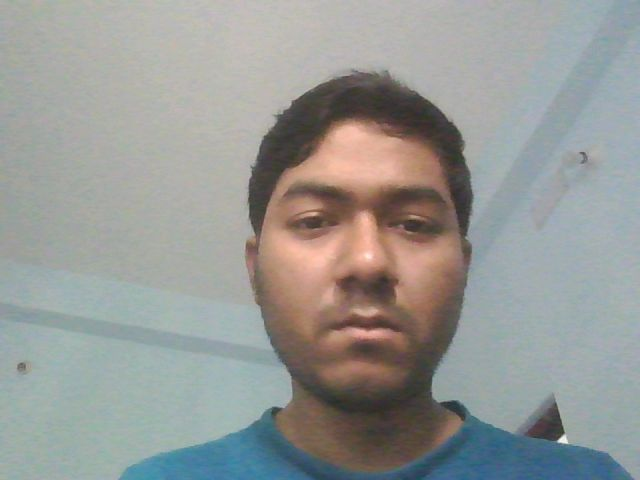

In [ ]:
from google.colab.patches import cv2_imshow

cv2_imshow(frame)

In [ ]:
fer_probs = get_emotion_probabilities(frame)

print(fer_probs)

{'angry': np.float64(0.006642271856035577), 'disgust': np.float64(1.5516849706573573e-06), 'fear': np.float64(0.29659519859071776), 'happy': np.float64(0.00022763831651448002), 'sad': np.float64(0.6280104227826157), 'surprise': np.float64(0.00014321304236445062), 'neutral': np.float64(0.06837970372678136)}


In [ ]:
user_emotion = map_fer_to_common_emotions(fer_probs)

print(user_emotion)
print("Sum:", sum(user_emotion.values()))

{'joy': np.float64(0.0002443470763515932), 'sadness': np.float64(0.6741066841245025), 'anger': np.float64(0.007129817744243965), 'fear': np.float64(0.31836542610765667), 'surprise': np.float64(0.00015372494724518148)}
Sum: 0.9999999999999998


In [ ]:
import time

def collect_emotion_sequence(num_frames=10, interval=0.7):
    """
    Capture multiple webcam frames and obtain a common
    5-dimensional emotion vector for each frame.

    Returns:
        list of dictionaries containing frame-level emotions.
    """

    emotion_sequence = []

    for i in range(num_frames):

        print(f"Capturing frame {i + 1}/{num_frames}...")

        try:
            frame = take_photo()

            fer_probs = get_emotion_probabilities(frame)

            common_probs = map_fer_to_common_emotions(fer_probs)

            emotion_sequence.append(common_probs)

            print(common_probs)

        except Exception as e:
            print(f"Frame {i + 1} failed: {e}")

        if i < num_frames - 1:
            time.sleep(interval)

    return emotion_sequence

In [ ]:
emotion_sequence = collect_emotion_sequence(
    num_frames=10,
    interval=0.7
)

Capturing frame 1/10...


<IPython.core.display.Javascript object>

{'joy': np.float64(0.014943655848012879), 'sadness': np.float64(0.24981976299718447), 'anger': np.float64(0.017804013160389764), 'fear': np.float64(0.7145334387309511), 'surprise': np.float64(0.0028991292634617145)}
Capturing frame 2/10...


<IPython.core.display.Javascript object>

{'joy': np.float64(0.012535606118835937), 'sadness': np.float64(0.43664110927649086), 'anger': np.float64(0.04029345193044346), 'fear': np.float64(0.5091134839236768), 'surprise': np.float64(0.0014163487505527625)}
Capturing frame 3/10...


<IPython.core.display.Javascript object>

... (11 outputs left out)

<IPython.core.display.Javascript object>

{'joy': np.float64(0.004588498502139815), 'sadness': np.float64(0.557982892518843), 'anger': np.float64(0.02876744391857283), 'fear': np.float64(0.40842571996794236), 'surprise': np.float64(0.0002354450925019897)}
Capturing frame 10/10...


<IPython.core.display.Javascript object>

{'joy': np.float64(0.0019229713440465186), 'sadness': np.float64(0.31682410305847025), 'anger': np.float64(0.014164148036257717), 'fear': np.float64(0.6668909760270775), 'surprise': np.float64(0.00019780153414817187)}


In [ ]:
emotion_sequence_matrix = np.array([
    [
        emotion[emotion_name]
        for emotion_name in COMMON_EMOTIONS
    ]
    for emotion in emotion_sequence
])

print("Shape:", emotion_sequence_matrix.shape)

print("\nEmotion order:")
print(COMMON_EMOTIONS)

print("\nEmotion sequence:")
print(emotion_sequence_matrix)

Shape: (10, 5)

Emotion order:
['joy', 'sadness', 'anger', 'fear', 'surprise']

Emotion sequence:
[[1.49436558e-02 2.49819763e-01 1.78040132e-02 7.14533439e-01
  2.89912926e-03]
 [1.25356061e-02 4.36641109e-01 4.02934519e-02 5.09113484e-01
  1.41634875e-03]
 [2.00727062e-03 6.82376796e-01 3.95929451e-02 2.75832208e-01
  1.90780470e-04]
 [1.57588562e-02 1.05029483e-01 5.43248206e-03 8.73216658e-01
  5.62520938e-04]
 [1.82796790e-03 2.55279477e-01 1.11928350e-02 7.31219042e-01
  4.80678359e-04]
 [1.79226815e-03 3.91046412e-01 1.35517677e-02 5.93444442e-01
  1.65110763e-04]
 [1.56317760e-03 2.65657604e-01 1.56463860e-02 7.16831594e-01
  3.01238250e-04]
 [9.99518531e-03 5.90381975e-01 2.61995145e-02 3.73145681e-01
  2.77644301e-04]
 [4.58849850e-03 5.57982893e-01 2.87674439e-02 4.08425720e-01
  2.35445093e-04]
 [1.92297134e-03 3.16824103e-01 1.41641480e-02 6.66890976e-01
  1.97801534e-04]]


In [ ]:
mean_emotion = emotion_sequence_matrix.mean(axis=0)

print("Mean emotion vector:")

for emotion, value in zip(COMMON_EMOTIONS, mean_emotion):
    print(f"{emotion}: {value:.4f}")

print("\nSum:", mean_emotion.sum())

Mean emotion vector:
joy: 0.0067
sadness: 0.3851
anger: 0.0213
fear: 0.5863
surprise: 0.0007

Sum: 1.0


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np


def calculate_temporal_stability(emotion_sequence_matrix):
    """
    Calculate temporal stability of facial emotion predictions.

    Each row represents the emotion probability vector
    for one frame.

    Returns:
        float: temporal stability score in [0, 1]
    """

    # Need at least two frames to measure temporal change
    if len(emotion_sequence_matrix) < 2:
        return 1.0

    similarities = []

    for t in range(1, len(emotion_sequence_matrix)):

        previous_vector = emotion_sequence_matrix[t - 1].reshape(1, -1)
        current_vector = emotion_sequence_matrix[t].reshape(1, -1)

        similarity = cosine_similarity(
            previous_vector,
            current_vector
        )[0][0]

        similarities.append(similarity)

    return float(np.mean(similarities))

In [ ]:
temporal_stability = calculate_temporal_stability(
    emotion_sequence_matrix
)

print("Temporal stability:", temporal_stability)

Temporal stability: 0.8771136851378059


In [ ]:
def calculate_pairwise_stability(emotion_sequence_matrix):
    """
    Return cosine similarity between every pair of consecutive frames.
    """

    similarities = []

    for t in range(1, len(emotion_sequence_matrix)):

        previous_vector = emotion_sequence_matrix[t - 1].reshape(1, -1)
        current_vector = emotion_sequence_matrix[t].reshape(1, -1)

        similarity = cosine_similarity(
            previous_vector,
            current_vector
        )[0][0]

        similarities.append(float(similarity))

    return similarities

In [ ]:
pairwise_stability = calculate_pairwise_stability(
    emotion_sequence_matrix
)

for i, value in enumerate(pairwise_stability, start=2):
    print(
        f"Frame {i-1} → Frame {i}: "
        f"{value:.4f}"
    )

print(
    "\nMean temporal stability:",
    np.mean(pairwise_stability)
)

Frame 1 → Frame 2: 0.9309
Frame 2 → Frame 3: 0.8883
Frame 3 → Frame 4: 0.4824
Frame 4 → Frame 5: 0.9766
Frame 5 → Frame 6: 0.9697
Frame 6 → Frame 7: 0.9742
Frame 7 → Frame 8: 0.7947
Frame 8 → Frame 9: 0.9976
Frame 9 → Frame 10: 0.8796

Mean temporal stability: 0.8771136851378059


In [ ]:
def calculate_emotion_reliability(
    confidence,
    temporal_stability
):
    """
    Combine FER confidence and temporal stability
    into a single reliability score.
    """

    reliability = confidence * temporal_stability

    return float(np.clip(reliability, 0.0, 1.0))

In [ ]:
# Step 7.5 — Calculate confidence, temporal stability, and reliability

# 1. Confidence for each frame
max_emotion_per_frame = np.max(
    emotion_sequence_matrix,
    axis=1
)

# 2. Average confidence across all frames
mean_confidence = np.mean(
    max_emotion_per_frame
)

# 3. Calculate temporal stability
temporal_stability = calculate_temporal_stability(
    emotion_sequence_matrix
)

# 4. Calculate combined reliability
emotion_reliability = calculate_emotion_reliability(
    mean_confidence,
    temporal_stability
)

# 5. Display results
print("Mean confidence:", mean_confidence)
print("Temporal stability:", temporal_stability)
print("Emotion reliability:", emotion_reliability)

Mean confidence: 0.6635991298809517
Temporal stability: 0.8771136851378059
Emotion reliability: 0.582051878264123


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np


def calculate_emotion_scores(
    user_emotion_vector,
    movie_emotion_matrix
):
    """
    Calculate emotional similarity between the user's
    current emotion and every movie.

    Parameters
    ----------
    user_emotion_vector : array-like, shape (5,)
        User's aggregated emotion vector.

    movie_emotion_matrix : np.ndarray, shape (n_movies, 5)
        Normalized emotion vectors for all movies.

    Returns
    -------
    np.ndarray
        Emotion similarity score for every movie.
    """

    user_vector = np.asarray(
        user_emotion_vector,
        dtype=float
    ).reshape(1, -1)

    scores = cosine_similarity(
        movie_emotion_matrix,
        user_vector
    ).flatten()

    return scores

In [ ]:
emotion_scores = calculate_emotion_scores(
    mean_emotion,
    common_movie_emotion_matrix
)

print("Emotion scores shape:", emotion_scores.shape)

print("\nFirst 10 emotion scores:")
print(emotion_scores[:10])

print("\nMinimum:", emotion_scores.min())
print("Maximum:", emotion_scores.max())

Emotion scores shape: (4800,)

First 10 emotion scores:
[0.45232699 0.53230872 0.89273006 0.71183176 0.54863322 0.91530521
 0.70737529 0.5371436  0.18471016 0.92193378]

Minimum: 0.011516298344554789
Maximum: 0.9999663774099793


In [ ]:
def min_max_normalize(scores):
    """
    Normalize scores to [0, 1].
    """

    scores = np.asarray(
        scores,
        dtype=float
    )

    min_score = scores.min()
    max_score = scores.max()

    if max_score == min_score:
        return np.zeros_like(scores)

    return (
        (scores - min_score)
        / (max_score - min_score)
    )

In [ ]:
emotion_scores_normalized = min_max_normalize(
    emotion_scores
)

print("Minimum:", emotion_scores_normalized.min())
print("Maximum:", emotion_scores_normalized.max())

print("\nFirst 10 normalized emotion scores:")
print(emotion_scores_normalized[:10])

Minimum: 0.0
Maximum: 1.0

First 10 normalized emotion scores:
[0.44596152 0.52687782 0.89151064 0.70849857 0.54339307 0.91434958
 0.70399003 0.53176919 0.17521761 0.9210556 ]


In [ ]:
top_emotion_indices = np.argsort(
    emotion_scores_normalized
)[::-1][:10]

print("Top 10 emotionally matching movies:\n")

for rank, idx in enumerate(top_emotion_indices, start=1):

    print(
        rank,
        "Index:",
        idx,
        "Emotion score:",
        round(emotion_scores_normalized[idx], 4)
    )

Top 10 emotionally matching movies:

1 Index: 3523 Emotion score: 1.0
2 Index: 2251 Emotion score: 0.9998
3 Index: 4021 Emotion score: 0.9998
4 Index: 2499 Emotion score: 0.9997
5 Index: 396 Emotion score: 0.9997
6 Index: 1533 Emotion score: 0.9996
7 Index: 339 Emotion score: 0.9995
8 Index: 2450 Emotion score: 0.9995
9 Index: 4274 Emotion score: 0.9994
10 Index: 3697 Emotion score: 0.9994


In [ ]:
print("Available recommendation-related variables:")

possible_variables = [
    "cf_scores",
    "cbf_scores",
    "cf_recommendations",
    "cbf_recommendations",
    "hybrid_scores",
    "movie_ids",
    "movie_id",
    "movies"
]

for name in possible_variables:
    if name in globals():
        value = globals()[name]

        print(f"\n{name}")
        print("Type:", type(value))

        try:
            print("Shape:", value.shape)
        except:
            pass

        try:
            print("Length:", len(value))
        except:
            pass

Available recommendation-related variables:

movies
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (4800, 26)
Length: 4800


In [ ]:
print("\nExisting recommendation functions:")

for name in [
    "get_cf_scores_all",
    "get_cbf_recommendations",
    "get_hybrid_recommendations"
]:
    if name in globals():
        print(name, "→ available")
    else:
        print(name, "→ not found")


Existing recommendation functions:
get_cf_scores_all → available
get_cbf_recommendations → available
get_hybrid_recommendations → not found


In [ ]:
print("Variables that may contain a user ID:\n")

for name in globals():
    if "user" in name.lower():
        value = globals()[name]

        print(
            name,
            "→",
            type(value),
            "=",
            value if isinstance(value, (int, str, float)) else ""
        )

Variables that may contain a user ID:

user_item_pivot → <class 'pandas.core.frame.DataFrame'> = 
sample_user → <class 'int'> = 73063
user_emotion → <class 'dict'> = 


In [ ]:
print("\nMovieLens/user-related variables:")

for name in globals():
    if any(word in name.lower() for word in ["rating", "user", "interaction"]):
        value = globals()[name]

        print(
            name,
            "→",
            type(value)
        )

        try:
            print("   Shape:", value.shape)
        except:
            try:
                print("   Length:", len(value))
            except:
                pass


MovieLens/user-related variables:
ratings_df → <class 'pandas.core.frame.DataFrame'>
   Shape: (25000095, 3)
ratings_linked → <class 'pandas.core.frame.DataFrame'>
   Shape: (500000, 3)
user_item_pivot → <class 'pandas.core.frame.DataFrame'>
   Shape: (120920, 4189)
sample_user → <class 'int'>
user_emotion → <class 'dict'>
   Length: 5


In [ ]:
print("Sample user ID:", sample_user)
print("Is user in pivot:", sample_user in user_item_pivot.index)

Sample user ID: 73063
Is user in pivot: True


In [ ]:
cf_result = get_cf_scores_all(sample_user)

print("CF result type:", type(cf_result))

try:
    print("Shape:", cf_result.shape)
except:
    try:
        print("Length:", len(cf_result))
    except:
        pass

print("\nFirst values:")

try:
    print(cf_result.head())
except:
    print(cf_result[:10])

CF result type: <class 'numpy.ndarray'>
Shape: (4189,)

First values:
[ 0.00181377 -0.00457605 -0.0070354  -0.00014319  0.01320772  0.00090762
 -0.00847893  0.00194211  0.00027426  0.00113109]


In [ ]:
import inspect

print(
    "CBF signature:",
    inspect.signature(get_cbf_recommendations)
)

print(
    "CF signature:",
    inspect.signature(get_cf_scores_all)
)

CBF signature: (movie_title, n=10)
CF signature: (user_id)


In [ ]:
print(movies["title"].head(20).tolist())

['Avatar', "Pirates of the Caribbean: At World's End", 'Spectre', 'The Dark Knight Rises', 'John Carter', 'Spider-Man 3', 'Tangled', 'Avengers: Age of Ultron', 'Harry Potter and the Half-Blood Prince', 'Batman v Superman: Dawn of Justice', 'Superman Returns', 'Quantum of Solace', "Pirates of the Caribbean: Dead Man's Chest", 'The Lone Ranger', 'Man of Steel', 'The Chronicles of Narnia: Prince Caspian', 'The Avengers', 'Pirates of the Caribbean: On Stranger Tides', 'Men in Black 3', 'The Hobbit: The Battle of the Five Armies']


In [ ]:
seed_movie = "Toy Story"
user_id = sample_user

In [ ]:
def prepare_adaptive_scores(
    seed_movie,
    user_id,
    movies,
    emotion_scores_normalized
):
    """
    Prepare aligned and normalized Content, CF, and Emotion
    score vectors for all movies.
    """

    # -----------------------------
    # 1. CONTENT-BASED SCORES
    # -----------------------------

    if seed_movie not in title_to_idx:
        raise ValueError(f'Movie not found: {seed_movie}')

    seed_idx = title_to_idx[seed_movie]

    raw_content_scores = cosine_sim[seed_idx].copy()

    S_content = normalise(
        raw_content_scores
    )

    # -----------------------------
    # 2. COLLABORATIVE SCORES
    # -----------------------------

    raw_cf_scores = get_cf_scores_all(
        user_id
    )

    full_cf_scores = np.zeros(
        len(movies)
    )

    collab_item_ids = user_item_pivot.columns

    for i, tmdb_id in enumerate(collab_item_ids):

        matched_indices = movies.index[
            movies["movie_id"] == tmdb_id
        ]

        if len(matched_indices) > 0:

            master_idx = matched_indices[0]

            full_cf_scores[master_idx] = (
                raw_cf_scores[i]
            )

    S_cf = normalise(
        full_cf_scores
    )

    # -----------------------------
    # 3. EMOTION SCORES
    # -----------------------------

    S_emotion = np.asarray(
        emotion_scores_normalized,
        dtype=float
    )

    # -----------------------------
    # Checks
    # -----------------------------

    assert len(S_content) == len(movies)
    assert len(S_cf) == len(movies)
    assert len(S_emotion) == len(movies)

    return (
        S_content,
        S_cf,
        S_emotion,
        seed_idx
    )

In [ ]:
S_content, S_cf, S_emotion, seed_idx = prepare_adaptive_scores(
    seed_movie=seed_movie,
    user_id=sample_user,
    movies=movies,
    emotion_scores_normalized=emotion_scores_normalized
)

In [ ]:
print("Content shape:", S_content.shape)
print("CF shape:", S_cf.shape)
print("Emotion shape:", S_emotion.shape)

print("\nContent range:",
      S_content.min(),
      S_content.max())

print("CF range:",
      S_cf.min(),
      S_cf.max())

print("Emotion range:",
      S_emotion.min(),
      S_emotion.max())

Content shape: (4800,)
CF shape: (4800,)
Emotion shape: (4800,)

Content range: 0.0 1.0
CF range: 0.0 1.0
Emotion range: 0.0 1.0


In [ ]:
def calculate_adaptive_weights(
    emotion_reliability,
    gamma_max=0.40,
    content_cf_ratio=0.50
):
    """
    Calculate adaptive fusion weights.

    gamma:
        emotion contribution

    alpha:
        content contribution

    beta:
        collaborative filtering contribution
    """

    gamma = (
        gamma_max
        * emotion_reliability
    )

    remaining_weight = 1.0 - gamma

    alpha = (
        remaining_weight
        * content_cf_ratio
    )

    beta = (
        remaining_weight
        * (1.0 - content_cf_ratio)
    )

    return alpha, beta, gamma

In [ ]:
alpha, beta, gamma = calculate_adaptive_weights(
    emotion_reliability
)

print("Content weight (alpha):", alpha)
print("CF weight (beta):", beta)
print("Emotion weight (gamma):", gamma)

print(
    "Total:",
    alpha + beta + gamma
)

Content weight (alpha): 0.3835896243471754
CF weight (beta): 0.3835896243471754
Emotion weight (gamma): 0.2328207513056492
Total: 1.0


In [ ]:
S_adaptive_final = (
    alpha * S_content
    +
    beta * S_cf
    +
    gamma * S_emotion
)

In [ ]:
S_adaptive_final[seed_idx] = -1.0

In [ ]:
rated_items = set(
    ratings_linked[
        ratings_linked["user_id"] == sample_user
    ]["item_id"].values
)

for i, tmdb_id in enumerate(
    movies["movie_id"].values
):

    if tmdb_id in rated_items:

        S_adaptive_final[i] = -1.0

In [ ]:
top_idx = np.argsort(
    S_adaptive_final
)[::-1][:10]

In [ ]:
adaptive_result = movies[
    [
        "title",
        "poster",
        "vote_average",
        "movie_id"
    ]
].iloc[top_idx].copy()

adaptive_result["S_content"] = np.round(
    S_content[top_idx],
    4
)

adaptive_result["S_cf"] = np.round(
    S_cf[top_idx],
    4
)

adaptive_result["S_emotion"] = np.round(
    S_emotion[top_idx],
    4
)

adaptive_result["S_final"] = np.round(
    S_adaptive_final[top_idx],
    4
)

adaptive_result.reset_index(
    drop=True,
    inplace=True
)

adaptive_result

,title,poster,vote_average,movie_id,S_content,S_cf,S_emotion,S_final
0,Pretty Woman,https://image.tmdb.org/t/p/w500/hVHUfT801LQATG...,7.0,114,0.0531,1.0000,0.5523,0.5325
1,E.T. the Extra-Terrestrial,https://image.tmdb.org/t/p/w500/an0nD6uq6byfxX...,7.3,601,0.0107,0.8141,0.5117,0.4356
2,Dr. Strangelove or: How I Learned to Stop Worr...,https://image.tmdb.org/t/p/w500/7SixLzxcqezkZE...,8.0,935,0.0324,0.7302,0.5626,0.4235
3,Toy Story 3,https://image.tmdb.org/t/p/w500/AbbXspMOwdvwWZ...,7.6,10193,0.4940,0.2654,0.5576,0.4211
4,Stand by Me,https://image.tmdb.org/t/p/w500/7QbJa6syM4ZYxt...,7.8,235,0.0319,0.4916,0.8997,0.4103
5,A Bug's Life,https://image.tmdb.org/t/p/w500/Ah3J9OJVc2CNCu...,6.8,9487,0.0249,0.4697,0.9265,0.4054
6,Groundhog Day,https://image.tmdb.org/t/p/w500/gCgt1WARPZaXnq...,7.4,137,0.0025,0.4555,0.9789,0.4036
7,Jerry Maguire,https://image.tmdb.org/t/p/w500/lABvGN7fDk5ifn...,6.7,9390,0.0175,0.4365,0.9756,0.4013
8,Jaws,https://image.tmdb.org/t/p/w500/lxM6kqilAdpdhq...,7.5,578,0.0000,0.4657,0.9249,0.3940
9,Office Space,https://image.tmdb.org/t/p/w500/fiB7DY9mATGFOC...,7.4,1542,0.0035,0.4360,0.9652,0.3933


In [ ]:
print("===== STEP 8 SANITY CHECK =====")

print("Number of movies:", len(movies))

print("\nScore vector lengths:")
print("Content:", len(S_content))
print("CF:", len(S_cf))
print("Emotion:", len(S_emotion))
print("Final:", len(S_adaptive_final))

print("\nScore ranges:")
print("Content:", S_content.min(), "to", S_content.max())
print("CF:", S_cf.min(), "to", S_cf.max())
print("Emotion:", S_emotion.min(), "to", S_emotion.max())

print("\nAdaptive weights:")
print("Alpha (Content):", alpha)
print("Beta (CF):", beta)
print("Gamma (Emotion):", gamma)
print("Weight sum:", alpha + beta + gamma)

print("\nNaN check:")
print("Content NaN:", np.isnan(S_content).any())
print("CF NaN:", np.isnan(S_cf).any())
print("Emotion NaN:", np.isnan(S_emotion).any())
print("Final NaN:", np.isnan(S_adaptive_final).any())

===== STEP 8 SANITY CHECK =====
Number of movies: 4800

Score vector lengths:
Content: 4800
CF: 4800
Emotion: 4800
Final: 4800

Score ranges:
Content: 0.0 to 1.0
CF: 0.0 to 1.0
Emotion: 0.0 to 1.0

Adaptive weights:
Alpha (Content): 0.3835896243471754
Beta (CF): 0.3835896243471754
Gamma (Emotion): 0.2328207513056492
Weight sum: 1.0

NaN check:
Content NaN: False
CF NaN: False
Emotion NaN: False
Final NaN: False


In [ ]:
# Step 9A — Static emotion-aware baseline

static_alpha = 0.4
static_beta = 0.4
static_gamma = 0.2

S_static_emotion = (
    static_alpha * S_content
    + static_beta * S_cf
    + static_gamma * S_emotion
)

# Exclude seed movie
S_static_emotion[seed_idx] = -1.0

# Exclude already-rated movies
for i, tmdb_id in enumerate(movies["movie_id"].values):
    if tmdb_id in rated_items:
        S_static_emotion[i] = -1.0

In [ ]:
static_top_idx = np.argsort(
    S_static_emotion
)[::-1][:10]

static_result = movies[
    [
        "title",
        "vote_average",
        "movie_id"
    ]
].iloc[static_top_idx].copy()

static_result["S_content"] = np.round(
    S_content[static_top_idx],
    4
)

static_result["S_cf"] = np.round(
    S_cf[static_top_idx],
    4
)

static_result["S_emotion"] = np.round(
    S_emotion[static_top_idx],
    4
)

static_result["S_final"] = np.round(
    S_static_emotion[static_top_idx],
    4
)

static_result.reset_index(
    drop=True,
    inplace=True
)

static_result

,title,vote_average,movie_id,S_content,S_cf,S_emotion,S_final
0,Pretty Woman,7.0,114,0.0531,1.0000,0.5523,0.5317
1,E.T. the Extra-Terrestrial,7.3,601,0.0107,0.8141,0.5117,0.4323
2,Dr. Strangelove or: How I Learned to Stop Worr...,8.0,935,0.0324,0.7302,0.5626,0.4175
3,Toy Story 3,7.6,10193,0.4940,0.2654,0.5576,0.4153
4,Stand by Me,7.8,235,0.0319,0.4916,0.8997,0.3893
5,A Bug's Life,6.8,9487,0.0249,0.4697,0.9265,0.3831
6,Toy Story 2,7.3,863,0.4678,0.2482,0.4746,0.3813
7,Groundhog Day,7.4,137,0.0025,0.4555,0.9789,0.3790
8,Jerry Maguire,6.7,9390,0.0175,0.4365,0.9756,0.3767
9,Jaws,7.5,578,0.0000,0.4657,0.9249,0.3713


In [ ]:
print("STATIC TOP 10")
print(static_result["title"].tolist())

print("\nADAPTIVE TOP 10")
print(adaptive_result["title"].tolist())

STATIC TOP 10
['Pretty Woman', 'E.T. the Extra-Terrestrial', 'Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb', 'Toy Story 3', 'Stand by Me', "A Bug's Life", 'Toy Story 2', 'Groundhog Day', 'Jerry Maguire', 'Jaws']

ADAPTIVE TOP 10
['Pretty Woman', 'E.T. the Extra-Terrestrial', 'Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb', 'Toy Story 3', 'Stand by Me', "A Bug's Life", 'Groundhog Day', 'Jerry Maguire', 'Jaws', 'Office Space']


In [ ]:
static_titles = set(
    static_result["title"]
)

adaptive_titles = set(
    adaptive_result["title"]
)

overlap = static_titles.intersection(
    adaptive_titles
)

print("Common movies:", len(overlap))
print("Overlap titles:", overlap)

Common movies: 9
Overlap titles: {'Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb', "A Bug's Life", 'Groundhog Day', 'E.T. the Extra-Terrestrial', 'Toy Story 3', 'Pretty Woman', 'Jerry Maguire', 'Stand by Me', 'Jaws'}


In [ ]:
# Step 9C — Confidence-only adaptive model

confidence_reliability = float(mean_confidence)

conf_alpha, conf_beta, conf_gamma = calculate_adaptive_weights(
    emotion_reliability=confidence_reliability,
    gamma_max=0.40,
    content_cf_ratio=0.50
)

S_confidence_only = (
    conf_alpha * S_content
    + conf_beta * S_cf
    + conf_gamma * S_emotion
)

# Exclude seed movie
S_confidence_only[seed_idx] = -1.0

# Exclude already-rated movies
for i, tmdb_id in enumerate(movies["movie_id"].values):
    if tmdb_id in rated_items:
        S_confidence_only[i] = -1.0

print("===== CONFIDENCE-ONLY MODEL =====")
print("Confidence:", mean_confidence)
print("Content weight:", conf_alpha)
print("CF weight:", conf_beta)
print("Emotion weight:", conf_gamma)
print("Total:", conf_alpha + conf_beta + conf_gamma)

===== CONFIDENCE-ONLY MODEL =====
Confidence: 0.6635991298809517
Content weight: 0.36728017402380964
CF weight: 0.36728017402380964
Emotion weight: 0.2654396519523807
Total: 1.0


In [ ]:
confidence_top_idx = np.argsort(
    S_confidence_only
)[::-1][:10]

confidence_result = movies[
    [
        "title",
        "vote_average",
        "movie_id"
    ]
].iloc[confidence_top_idx].copy()

confidence_result["S_final"] = np.round(
    S_confidence_only[confidence_top_idx],
    4
)

confidence_result.reset_index(
    drop=True,
    inplace=True
)

confidence_result

,title,vote_average,movie_id,S_final
0,Pretty Woman,7.0,114,0.5334
1,E.T. the Extra-Terrestrial,7.3,601,0.4388
2,Stand by Me,7.8,235,0.4311
3,Dr. Strangelove or: How I Learned to Stop Worr...,8.0,935,0.4294
4,Groundhog Day,7.4,137,0.4281
5,A Bug's Life,6.8,9487,0.4276
6,Toy Story 3,7.6,10193,0.4269
7,Jerry Maguire,6.7,9390,0.4257
8,Office Space,7.4,1542,0.4176
9,Jaws,7.5,578,0.4165


In [ ]:
# Step 9D — Temporal-stability-only adaptive model

stability_reliability = float(temporal_stability)

stab_alpha, stab_beta, stab_gamma = calculate_adaptive_weights(
    emotion_reliability=stability_reliability,
    gamma_max=0.40,
    content_cf_ratio=0.50
)

S_stability_only = (
    stab_alpha * S_content
    + stab_beta * S_cf
    + stab_gamma * S_emotion
)

# Exclude seed movie
S_stability_only[seed_idx] = -1.0

# Exclude already-rated movies
for i, tmdb_id in enumerate(movies["movie_id"].values):
    if tmdb_id in rated_items:
        S_stability_only[i] = -1.0

print("===== STABILITY-ONLY MODEL =====")
print("Temporal stability:", temporal_stability)
print("Content weight:", stab_alpha)
print("CF weight:", stab_beta)
print("Emotion weight:", stab_gamma)
print("Total:", stab_alpha + stab_beta + stab_gamma)

===== STABILITY-ONLY MODEL =====
Temporal stability: 0.8771136851378059
Content weight: 0.32457726297243883
CF weight: 0.32457726297243883
Emotion weight: 0.35084547405512234
Total: 1.0


In [ ]:
stability_top_idx = np.argsort(
    S_stability_only
)[::-1][:10]

stability_result = movies[
    [
        "title",
        "vote_average",
        "movie_id"
    ]
].iloc[stability_top_idx].copy()

stability_result["S_final"] = np.round(
    S_stability_only[stability_top_idx],
    4
)

stability_result.reset_index(
    drop=True,
    inplace=True
)

stability_result

,title,vote_average,movie_id,S_final
0,Pretty Woman,7.0,114,0.5356
1,Groundhog Day,7.4,137,0.4921
2,Jerry Maguire,6.7,9390,0.4896
3,Stand by Me,7.8,235,0.4856
4,A Bug's Life,6.8,9487,0.4856
5,Office Space,7.4,1542,0.4813
6,Dead Poets Society,8.1,207,0.4803
7,Platoon,7.5,792,0.4780
8,Jaws,7.5,578,0.4756
9,Crimson Tide,7.0,8963,0.4724


In [ ]:
comparison_df = pd.DataFrame({
    "Static": static_result["title"],
    "Confidence Only": confidence_result["title"],
    "Stability Only": stability_result["title"],
    "Confidence + Stability": adaptive_result["title"]
})

comparison_df.index = range(1, 11)

comparison_df

,Static,Confidence Only,Stability Only,Confidence + Stability
1,Pretty Woman,Pretty Woman,Pretty Woman,Pretty Woman
2,E.T. the Extra-Terrestrial,E.T. the Extra-Terrestrial,Groundhog Day,E.T. the Extra-Terrestrial
3,Dr. Strangelove or: How I Learned to Stop Worr...,Stand by Me,Jerry Maguire,Dr. Strangelove or: How I Learned to Stop Worr...
4,Toy Story 3,Dr. Strangelove or: How I Learned to Stop Worr...,Stand by Me,Toy Story 3
5,Stand by Me,Groundhog Day,A Bug's Life,Stand by Me
6,A Bug's Life,A Bug's Life,Office Space,A Bug's Life
7,Toy Story 2,Toy Story 3,Dead Poets Society,Groundhog Day
8,Groundhog Day,Jerry Maguire,Platoon,Jerry Maguire
9,Jerry Maguire,Office Space,Jaws,Jaws
10,Jaws,Jaws,Crimson Tide,Office Space


In [ ]:
print("===== WEIGHT COMPARISON =====")

print(
    f"Static             → "
    f"C={static_alpha:.4f}, "
    f"CF={static_beta:.4f}, "
    f"E={static_gamma:.4f}"
)

print(
    f"Confidence only    → "
    f"C={conf_alpha:.4f}, "
    f"CF={conf_beta:.4f}, "
    f"E={conf_gamma:.4f}"
)

print(
    f"Stability only     → "
    f"C={stab_alpha:.4f}, "
    f"CF={stab_beta:.4f}, "
    f"E={stab_gamma:.4f}"
)

print(
    f"Confidence+Stab.   → "
    f"C={alpha:.4f}, "
    f"CF={beta:.4f}, "
    f"E={gamma:.4f}"
)

===== WEIGHT COMPARISON =====
Static             → C=0.4000, CF=0.4000, E=0.2000
Confidence only    → C=0.3673, CF=0.3673, E=0.2654
Stability only     → C=0.3246, CF=0.3246, E=0.3508
Confidence+Stab.   → C=0.3836, CF=0.3836, E=0.2328


In [ ]:
print("ratings_linked shape:")
print(ratings_linked.shape)

print("\nColumns:")
print(ratings_linked.columns.tolist())

print("\nFirst 10 rows:")
display(ratings_linked.head(10))

print("\nData types:")
print(ratings_linked.dtypes)

print("\nRating statistics:")

if "rating" in ratings_linked.columns:
    print(ratings_linked["rating"].describe())
    print(
        "\nUnique ratings:",
        sorted(ratings_linked["rating"].unique())
    )

ratings_linked shape:
(500000, 3)

Columns:
['user_id', 'item_id', 'rating']

First 10 rows:


,user_id,item_id,rating
0,152232,329,4.0
1,11162,165,4.0
2,93217,27205,5.0
3,91549,223,4.0
4,128864,27576,4.0
5,104420,602,2.5
6,107870,8461,2.5
7,107355,424,4.0
8,106215,35,3.0
9,36157,602,3.0



Data types:
user_id      int32
item_id      int64
rating     float32
dtype: object

Rating statistics:
count    500000.000000
mean          3.562468
std           1.053724
min           0.500000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

Unique ratings: [np.float32(0.5), np.float32(1.0), np.float32(1.5), np.float32(2.0), np.float32(2.5), np.float32(3.0), np.float32(3.5), np.float32(4.0), np.float32(4.5), np.float32(5.0)]


In [ ]:
user_rating_counts = (
    ratings_linked
    .groupby("user_id")
    .size()
)

print("Number of users:")
print(user_rating_counts.shape[0])

print("\nRatings per user:")
print(user_rating_counts.describe())

Number of users:
120920

Ratings per user:
count    120920.000000
mean          4.134965
std           5.093058
min           1.000000
25%           1.000000
50%           2.000000
75%           5.000000
max         112.000000
dtype: float64


In [ ]:
print("Users with >= 5 ratings:",
      (user_rating_counts >= 5).sum())

print("Users with >= 10 ratings:",
      (user_rating_counts >= 10).sum())

print("Users with >= 20 ratings:",
      (user_rating_counts >= 20).sum())

Users with >= 5 ratings: 32677
Users with >= 10 ratings: 11685
Users with >= 20 ratings: 2633


In [ ]:
# Step 10D.1 — Select users suitable for evaluation

MIN_RATINGS = 10
RANDOM_SEED = 42

user_rating_counts = (
    ratings_linked
    .groupby("user_id")
    .size()
)

eligible_users = user_rating_counts[
    user_rating_counts >= MIN_RATINGS
].index

print("Eligible users:", len(eligible_users))

Eligible users: 11685


In [ ]:
evaluation_ratings = ratings_linked[
    ratings_linked["user_id"].isin(eligible_users)
].copy()

print("Evaluation interactions:",
      len(evaluation_ratings))

print("Evaluation users:",
      evaluation_ratings["user_id"].nunique())

print("Evaluation items:",
      evaluation_ratings["item_id"].nunique())

Evaluation interactions: 191720
Evaluation users: 11685
Evaluation items: 4117


In [ ]:
train_test_split(ratings_linked)

[        user_id  item_id  rating
 314540    23867    36647     4.0
 333490   115501     2122     5.0
 411817    27128     6114     1.0
 476170   117283      400     1.0
 292124   101051     9889     3.0
 ...         ...      ...     ...
 415465    81932     1930     3.5
 165050   161675      807     5.0
 478692    16774       58     3.0
 177107     8689     9428     5.0
 425517    86620     1620     0.5
 
 [375000 rows x 3 columns],
         user_id  item_id  rating
 352816    37317    11287     3.5
 127668   123913      403     5.0
 328341    97248    68734     4.0
 377789   147369     5175     3.5
 1097      62448      595     5.0
 ...         ...      ...     ...
 383722    30635     9631     4.5
 44061    118928    19995     3.5
 169413   118786      606     3.0
 133422    84269     8843     2.0
 279711   110030     7299     2.0
 
 [125000 rows x 3 columns]]

In [ ]:
def per_user_train_test_split(
    ratings,
    test_ratio=0.20,
    random_seed=42
):
    train_parts = []
    test_parts = []

    for user_id, user_data in ratings.groupby("user_id"):

        user_data = user_data.sample(
            frac=1,
            random_state=random_seed
        )

        n_test = max(
            1,
            int(len(user_data) * test_ratio)
        )

        test_user = user_data.iloc[:n_test]
        train_user = user_data.iloc[n_test:]

        train_parts.append(train_user)
        test_parts.append(test_user)

    train_df = pd.concat(
        train_parts,
        ignore_index=True
    )

    test_df = pd.concat(
        test_parts,
        ignore_index=True
    )

    return train_df, test_df

In [ ]:
train_ratings, test_ratings = per_user_train_test_split(
    evaluation_ratings,
    test_ratio=0.20,
    random_seed=RANDOM_SEED
)

print("Train shape:", train_ratings.shape)
print("Test shape:", test_ratings.shape)

print("\nTrain users:",
      train_ratings["user_id"].nunique())

print("Test users:",
      test_ratings["user_id"].nunique())

Train shape: (157269, 3)
Test shape: (34451, 3)

Train users: 11685
Test users: 11685


In [ ]:
train_pairs = set(
    zip(
        train_ratings["user_id"],
        train_ratings["item_id"]
    )
)

test_pairs = set(
    zip(
        test_ratings["user_id"],
        test_ratings["item_id"]
    )
)

overlap = train_pairs.intersection(
    test_pairs
)

print(
    "Train/Test interaction overlap:",
    len(overlap)
)

Train/Test interaction overlap: 0


In [ ]:
RELEVANCE_THRESHOLD = 4.0

relevant_test_ratings = test_ratings[
    test_ratings["rating"] >= RELEVANCE_THRESHOLD
].copy()

print(
    "Relevant test interactions:",
    len(relevant_test_ratings)
)

print(
    "Users with at least one relevant test item:",
    relevant_test_ratings["user_id"].nunique()
)

Relevant test interactions: 14122
Users with at least one relevant test item: 8466


In [ ]:
# Step 10E.1 — Training-only user-item matrix

eval_user_item_pivot = train_ratings.pivot_table(
    index="user_id",
    columns="item_id",
    values="rating",
    fill_value=0
)

print("Evaluation user-item matrix shape:")
print(eval_user_item_pivot.shape)

print("\nUsers:")
print(len(eval_user_item_pivot.index))

print("Items:")
print(len(eval_user_item_pivot.columns))

Evaluation user-item matrix shape:
(11685, 4064)

Users:
11685
Items:
4064


In [ ]:
# Step 10E.2 — Mean-center observed ratings

eval_matrix = eval_user_item_pivot.values.astype(float)

# Number of actually rated movies per user
rated_mask = eval_matrix > 0

eval_user_means = np.divide(
    eval_matrix.sum(axis=1),
    rated_mask.sum(axis=1),
    out=np.zeros(eval_matrix.shape[0]),
    where=rated_mask.sum(axis=1) != 0
)

eval_matrix_centered = np.where(
    rated_mask,
    eval_matrix - eval_user_means[:, None],
    0.0
)

print("Matrix shape:", eval_matrix_centered.shape)

print(
    "Contains NaN:",
    np.isnan(eval_matrix_centered).any()
)

print(
    "Contains Inf:",
    np.isinf(eval_matrix_centered).any()
)

Matrix shape: (11685, 4064)
Contains NaN: False
Contains Inf: False


In [ ]:
from sklearn.decomposition import TruncatedSVD

In [ ]:
# Step 10E.3 — Training-only SVD

EVAL_SVD_COMPONENTS = 50
RANDOM_SEED = 42

eval_svd = TruncatedSVD(
    n_components=EVAL_SVD_COMPONENTS,
    random_state=RANDOM_SEED
)

eval_user_factors = eval_svd.fit_transform(
    eval_matrix_centered
)

eval_item_factors = eval_svd.components_.T

print("User factors shape:")
print(eval_user_factors.shape)

print("\nItem factors shape:")
print(eval_item_factors.shape)

print(
    "\nExplained variance:",
    eval_svd.explained_variance_ratio_.sum()
)

User factors shape:
(11685, 50)

Item factors shape:
(4064, 50)

Explained variance: 0.10208123339611049


In [ ]:
def get_eval_cf_scores(user_id):
    """
    Generate CF scores using ONLY the evaluation
    model trained on train_ratings.
    """

    if user_id not in eval_user_item_pivot.index:
        raise ValueError(
            f"User {user_id} not found in evaluation training data."
        )

    user_position = eval_user_item_pivot.index.get_loc(
        user_id
    )

    scores = (
        eval_user_factors[user_position]
        @ eval_item_factors.T
    )

    # Restore user's mean rating
    scores = scores + eval_user_means[user_position]

    return scores

In [ ]:
eval_sample_user = eval_user_item_pivot.index[0]

eval_cf_scores = get_eval_cf_scores(
    eval_sample_user
)

print("Evaluation user:", eval_sample_user)

print(
    "CF score vector shape:",
    eval_cf_scores.shape
)

print(
    "Minimum prediction:",
    eval_cf_scores.min()
)

print(
    "Maximum prediction:",
    eval_cf_scores.max()
)

print("\nFirst 10 predictions:")
print(eval_cf_scores[:10])

Evaluation user: 3
CF score vector shape: (4064,)
Minimum prediction: 3.808252819458001
Maximum prediction: 3.8659727106387543

First 10 predictions:
[3.83287672 3.83103085 3.83787459 3.82712555 3.85996546 3.83211353
 3.83686425 3.83495483 3.83312888 3.8414286 ]


In [ ]:
sample_train = train_ratings[
    train_ratings["user_id"] == eval_sample_user
]

sample_test = test_ratings[
    test_ratings["user_id"] == eval_sample_user
]

print("Evaluation user:", eval_sample_user)

print("\nTraining interactions:")
print(len(sample_train))

print("Held-out test interactions:")
print(len(sample_test))

print("\nTraining movies:")
print(sample_train["item_id"].tolist())

print("\nHeld-out movies:")
print(sample_test["item_id"].tolist())

print(
    "\nOverlap:",
    len(
        set(sample_train["item_id"])
        &
        set(sample_test["item_id"])
    )
)

Evaluation user: 3

Training interactions:
12
Held-out test interactions:
2

Training movies:
[9801, 10950, 137113, 809, 318846, 9767, 7443, 45612, 39514, 670, 49529, 9615]

Held-out movies:
[289, 158852]

Overlap: 0


In [ ]:
import numpy as np


def precision_at_k(recommended_items, relevant_items, k):
    """
    Precision@K:
    fraction of top-K recommendations that are relevant.
    """

    recommended_k = recommended_items[:k]

    if k == 0:
        return 0.0

    hits = len(
        set(recommended_k)
        & set(relevant_items)
    )

    return hits / k


def recall_at_k(recommended_items, relevant_items, k):
    """
    Recall@K:
    fraction of all relevant items recovered in top-K.
    """

    if len(relevant_items) == 0:
        return np.nan

    recommended_k = recommended_items[:k]

    hits = len(
        set(recommended_k)
        & set(relevant_items)
    )

    return hits / len(relevant_items)


def ndcg_at_k(recommended_items, relevant_items, k):
    """
    Binary NDCG@K.

    Relevant item -> relevance = 1
    Non-relevant item -> relevance = 0
    """

    relevant_set = set(relevant_items)

    recommended_k = recommended_items[:k]

    # DCG
    dcg = 0.0

    for rank, item in enumerate(
        recommended_k,
        start=1
    ):

        relevance = (
            1.0
            if item in relevant_set
            else 0.0
        )

        dcg += relevance / np.log2(rank + 1)

    # Ideal DCG
    ideal_hits = min(
        len(relevant_set),
        k
    )

    idcg = sum(
        1.0 / np.log2(rank + 1)
        for rank in range(
            1,
            ideal_hits + 1
        )
    )

    if idcg == 0:
        return np.nan

    return dcg / idcg

In [ ]:
eval_user_item_pivot.columns

Index([     5,     11,     12,     13,     14,     16,     18,     19,     20,
           22,
       ...
       351819, 354110, 362105, 365222, 374461, 375290, 376659, 378200, 389425,
       426469],
      dtype='int64', name='item_id', length=4064)

In [ ]:
def recommend_eval_cf(
    user_id,
    k=10
):
    """
    Generate CF-only recommendations
    from the leakage-safe evaluation model.
    """

    scores = get_eval_cf_scores(
        user_id
    ).copy()

    item_ids = np.array(
        eval_user_item_pivot.columns
    )

    # Movies already seen in TRAIN must not be recommended
    seen_items = set(
        train_ratings[
            train_ratings["user_id"] == user_id
        ]["item_id"].values
    )

    seen_mask = np.isin(
        item_ids,
        list(seen_items)
    )

    scores[seen_mask] = -np.inf

    ranked_indices = np.argsort(
        scores
    )[::-1]

    recommended_items = item_ids[
        ranked_indices
    ][:k]

    return recommended_items.tolist()

In [ ]:
evaluation_users = (
    relevant_test_ratings["user_id"]
    .unique()
)

metric_sample_user = evaluation_users[0]

print(
    "Metric test user:",
    metric_sample_user
)

Metric test user: 3


In [ ]:
sample_train = train_ratings[
    train_ratings["user_id"]
    == metric_sample_user
]

sample_test = test_ratings[
    test_ratings["user_id"]
    == metric_sample_user
]

sample_relevant = sample_test[
    sample_test["rating"]
    >= RELEVANCE_THRESHOLD
]

print("Train interactions:",
      len(sample_train))

print("Test interactions:",
      len(sample_test))

print("Relevant test interactions:",
      len(sample_relevant))

print(
    "Relevant held-out movie IDs:",
    sample_relevant["item_id"].tolist()
)

Train interactions: 12
Test interactions: 2
Relevant test interactions: 1
Relevant held-out movie IDs: [289]


In [ ]:
sample_recommendations = recommend_eval_cf(
    metric_sample_user,
    k=10
)

print("Recommended movie IDs:")
print(sample_recommendations)

Recommended movie IDs:
[578, 807, 103, 14, 78, 187, 1894, 137, 745, 28]


In [ ]:
relevant_items = (
    sample_relevant["item_id"]
    .tolist()
)

print(
    "Relevant held-out:",
    relevant_items
)

print(
    "Recommended:",
    sample_recommendations
)

print(
    "Hits:",
    set(relevant_items)
    & set(sample_recommendations)
)

Relevant held-out: [289]
Recommended: [578, 807, 103, 14, 78, 187, 1894, 137, 745, 28]
Hits: set()


In [ ]:
p5 = precision_at_k(
    sample_recommendations,
    relevant_items,
    5
)

p10 = precision_at_k(
    sample_recommendations,
    relevant_items,
    10
)

r5 = recall_at_k(
    sample_recommendations,
    relevant_items,
    5
)

r10 = recall_at_k(
    sample_recommendations,
    relevant_items,
    10
)

n5 = ndcg_at_k(
    sample_recommendations,
    relevant_items,
    5
)

n10 = ndcg_at_k(
    sample_recommendations,
    relevant_items,
    10
)

print("Precision@5:", p5)
print("Precision@10:", p10)

print("Recall@5:", r5)
print("Recall@10:", r10)

print("NDCG@5:", n5)
print("NDCG@10:", n10)

Precision@5: 0.0
Precision@10: 0.0
Recall@5: 0.0
Recall@10: 0.0
NDCG@5: 0.0
NDCG@10: 0.0


In [ ]:
def evaluate_cf_model(
    user_ids,
    k_values=(5, 10)
):
    """
    Evaluate the leakage-safe CF model
    across multiple users.
    """

    results = []

    for count, user_id in enumerate(
        user_ids,
        start=1
    ):

        relevant_items = (
            relevant_test_ratings[
                relevant_test_ratings["user_id"]
                == user_id
            ]["item_id"]
            .tolist()
        )

        if len(relevant_items) == 0:
            continue

        recommendations = recommend_eval_cf(
            user_id,
            k=max(k_values)
        )

        row = {
            "user_id": user_id
        }

        for k in k_values:

            row[f"precision@{k}"] = (
                precision_at_k(
                    recommendations,
                    relevant_items,
                    k
                )
            )

            row[f"recall@{k}"] = (
                recall_at_k(
                    recommendations,
                    relevant_items,
                    k
                )
            )

            row[f"ndcg@{k}"] = (
                ndcg_at_k(
                    recommendations,
                    relevant_items,
                    k
                )
            )

        results.append(row)

        if count % 100 == 0:
            print(
                f"Evaluated {count} users"
            )

    return pd.DataFrame(results)

In [ ]:
TEST_EVAL_USERS = 200

eval_users_sample = (
    relevant_test_ratings["user_id"]
    .drop_duplicates()
    .sample(
        n=TEST_EVAL_USERS,
        random_state=42
    )
    .tolist()
)

cf_metrics_200 = evaluate_cf_model(
    eval_users_sample
)

print(
    "\nNumber of evaluated users:",
    len(cf_metrics_200)
)

Evaluated 100 users
Evaluated 200 users

Number of evaluated users: 200


In [ ]:
cf_metrics_200.head()

,user_id,precision@5,recall@5,ndcg@5,precision@10,recall@10,ndcg@10
0,113900,0.0,0.0,0.0,0.0,0.0,0.0
1,101116,0.0,0.0,0.0,0.0,0.0,0.0
2,113027,0.0,0.0,0.0,0.0,0.0,0.0
3,17016,0.0,0.0,0.0,0.0,0.0,0.0
4,110176,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
cf_mean_metrics = (
    cf_metrics_200
    .drop(columns=["user_id"])
    .mean()
)

print(
    "===== CF-ONLY MEAN METRICS ====="
)

print(cf_mean_metrics)

===== CF-ONLY MEAN METRICS =====
precision@5     0.003000
recall@5        0.010000
ndcg@5          0.005967
precision@10    0.003000
recall@10       0.018333
ndcg@10         0.009084
dtype: float64


In [ ]:
train_item_ids = set(
    train_ratings["item_id"].unique()
)

movie_ids = set(
    movies["movie_id"].unique()
)

matched_items = train_item_ids & movie_ids

print("Unique training item IDs:", len(train_item_ids))
print("Movie metadata IDs:", len(movie_ids))
print("Matched IDs:", len(matched_items))

print(
    "Training-item match percentage:",
    len(matched_items) / len(train_item_ids) * 100
)

Unique training item IDs: 4064
Movie metadata IDs: 4800
Matched IDs: 4064
Training-item match percentage: 100.0


In [ ]:
def get_eval_seed_movie(user_id):
    """
    Select a content seed using TRAINING DATA ONLY.

    Rule:
    1. Get user's training ratings.
    2. Keep movies available in metadata.
    3. Find highest rating.
    4. Among ties, select the smallest movie_id
       for deterministic reproducibility.
    """

    user_train = train_ratings[
        train_ratings["user_id"] == user_id
    ].copy()

    user_train = user_train[
        user_train["item_id"].isin(movie_ids)
    ]

    if len(user_train) == 0:
        return None

    max_rating = user_train["rating"].max()

    candidates = user_train[
        user_train["rating"] == max_rating
    ].sort_values("item_id")

    seed_item_id = candidates.iloc[0]["item_id"]

    match = movies[
        movies["movie_id"] == seed_item_id
    ]

    if len(match) == 0:
        return None

    return {
        "movie_id": int(seed_item_id),
        "title": match.iloc[0]["title"],
        "rating": float(max_rating)
    }

In [ ]:
seed_info = get_eval_seed_movie(
    metric_sample_user
)

print(seed_info)

{'movie_id': 670, 'title': 'Oldboy', 'rating': 5.0}


In [ ]:
def get_eval_cbf_scores(user_id):
    """
    Generate full content-based score vector
    using a seed selected exclusively from
    the user's training interactions.
    """

    seed_info = get_eval_seed_movie(user_id)

    if seed_info is None:
        return None, None

    seed_title = seed_info["title"]

    if seed_title not in title_to_idx:
        return None, None

    seed_idx = title_to_idx[seed_title]

    scores = cosine_sim[
        seed_idx
    ].copy()

    return scores, seed_info

In [ ]:
cbf_scores_sample, seed_info = (
    get_eval_cbf_scores(metric_sample_user)
)

print("Seed:")
print(seed_info)

print("\nCBF vector shape:")
print(cbf_scores_sample.shape)

print("\nCBF range:")
print(
    cbf_scores_sample.min(),
    cbf_scores_sample.max()
)

Seed:
{'movie_id': 670, 'title': 'Oldboy', 'rating': 5.0}

CBF vector shape:
(4800,)

CBF range:
0.0 1.0000000000000002


In [ ]:
def recommend_eval_cbf(
    user_id,
    k=10
):
    scores, seed_info = get_eval_cbf_scores(
        user_id
    )

    if scores is None:
        return []

    scores = scores.copy()

    # Never recommend movies already seen in TRAIN
    seen_items = set(
        train_ratings[
            train_ratings["user_id"] == user_id
        ]["item_id"]
    )

    for idx, movie_id in enumerate(
        movies["movie_id"].values
    ):
        if movie_id in seen_items:
            scores[idx] = -np.inf

    ranked_indices = np.argsort(
        scores
    )[::-1]

    recommended_ids = []

    for idx in ranked_indices:

        movie_id = movies.iloc[idx][
            "movie_id"
        ]

        recommended_ids.append(
            int(movie_id)
        )

        if len(recommended_ids) >= k:
            break

    return recommended_ids

In [ ]:
cbf_sample_recommendations = (
    recommend_eval_cbf(
        metric_sample_user,
        k=10
    )
)

print("CBF recommendations:")
print(cbf_sample_recommendations)

print("\nRelevant held-out:")
print(relevant_items)

print(
    "\nHits:",
    set(cbf_sample_recommendations)
    & set(relevant_items)
)

CBF recommendations:
[4550, 807, 12877, 168259, 48231, 38223, 240832, 11658, 299145, 754]

Relevant held-out:
[289]

Hits: set()


In [ ]:
def get_eval_cf_scores_full(user_id):
    """
    Convert leakage-safe CF scores into the
    full 4800-movie metadata space.
    """

    raw_cf_scores = get_eval_cf_scores(user_id)

    full_cf_scores = np.zeros(len(movies), dtype=float)

    cf_item_ids = eval_user_item_pivot.columns

    movie_id_to_index = {
        movie_id: idx
        for idx, movie_id in enumerate(movies["movie_id"].values)
    }

    for i, item_id in enumerate(cf_item_ids):

        if item_id in movie_id_to_index:

            master_idx = movie_id_to_index[item_id]

            full_cf_scores[master_idx] = raw_cf_scores[i]

    return full_cf_scores

In [ ]:
cf_full_sample = get_eval_cf_scores_full(
    metric_sample_user
)

print("Full CF shape:", cf_full_sample.shape)

print(
    "Full CF range:",
    cf_full_sample.min(),
    cf_full_sample.max()
)

Full CF shape: (4800,)
Full CF range: 0.0 3.8659727106387543


In [ ]:
def eval_normalize(scores):
    scores = np.asarray(scores, dtype=float)

    min_score = scores.min()
    max_score = scores.max()

    if max_score == min_score:
        return np.zeros_like(scores)

    return (
        (scores - min_score)
        / (max_score - min_score)
    )

In [ ]:
cbf_scores_sample, seed_info = get_eval_cbf_scores(
    metric_sample_user
)

cf_scores_sample = get_eval_cf_scores_full(
    metric_sample_user
)

S_eval_cbf = eval_normalize(
    cbf_scores_sample
)

S_eval_cf = eval_normalize(
    cf_scores_sample
)

print("CBF:", S_eval_cbf.min(), S_eval_cbf.max())
print("CF:", S_eval_cf.min(), S_eval_cf.max())

CBF: 0.0 1.0
CF: 0.0 1.0


In [ ]:
def recommend_eval_hybrid(
    user_id,
    k=10,
    alpha=0.5,
    beta=0.5
):
    """
    Leakage-safe conventional hybrid:
    Content + Collaborative Filtering.

    No emotion signal.
    """

    cbf_scores, seed_info = get_eval_cbf_scores(
        user_id
    )

    if cbf_scores is None:
        return []

    cf_scores = get_eval_cf_scores_full(
        user_id
    )

    S_cbf = eval_normalize(
        cbf_scores
    )

    S_cf = eval_normalize(
        cf_scores
    )

    final_scores = (
        alpha * S_cbf
        +
        beta * S_cf
    )

    # Remove TRAIN-seen movies
    seen_items = set(
        train_ratings[
            train_ratings["user_id"] == user_id
        ]["item_id"].values
    )

    for idx, movie_id in enumerate(
        movies["movie_id"].values
    ):

        if movie_id in seen_items:
            final_scores[idx] = -np.inf

    ranked_indices = np.argsort(
        final_scores
    )[::-1]

    recommended_ids = []

    for idx in ranked_indices:

        movie_id = int(
            movies.iloc[idx]["movie_id"]
        )

        recommended_ids.append(movie_id)

        if len(recommended_ids) >= k:
            break

    return recommended_ids

In [ ]:
hybrid_sample_recommendations = (
    recommend_eval_hybrid(
        metric_sample_user,
        k=10
    )
)

print("Hybrid recommendations:")
print(hybrid_sample_recommendations)

print("\nRelevant held-out:")
print(relevant_items)

print(
    "\nHits:",
    set(hybrid_sample_recommendations)
    & set(relevant_items)
)

Hybrid recommendations:
[4550, 807, 12877, 168259, 48231, 38223, 240832, 11658, 187, 754]

Relevant held-out:
[289]

Hits: set()


In [ ]:
def evaluate_recommender(
    user_ids,
    recommender_function,
    model_name,
    k_values=(5, 10)
):
    results = []

    for count, user_id in enumerate(
        user_ids,
        start=1
    ):

        relevant_items = (
            relevant_test_ratings[
                relevant_test_ratings["user_id"] == user_id
            ]["item_id"]
            .tolist()
        )

        if len(relevant_items) == 0:
            continue

        recommendations = recommender_function(
            user_id,
            k=max(k_values)
        )

        if len(recommendations) == 0:
            continue

        row = {
            "user_id": user_id,
            "model": model_name
        }

        for k in k_values:

            row[f"precision@{k}"] = precision_at_k(
                recommendations,
                relevant_items,
                k
            )

            row[f"recall@{k}"] = recall_at_k(
                recommendations,
                relevant_items,
                k
            )

            row[f"ndcg@{k}"] = ndcg_at_k(
                recommendations,
                relevant_items,
                k
            )

        results.append(row)

        if count % 100 == 0:
            print(
                f"{model_name}: evaluated {count} users"
            )

    return pd.DataFrame(results)

In [ ]:
cbf_metrics_200 = evaluate_recommender(
    eval_users_sample,
    recommend_eval_cbf,
    "CBF"
)

CBF: evaluated 100 users
CBF: evaluated 200 users


In [ ]:
hybrid_metrics_200 = evaluate_recommender(
    eval_users_sample,
    recommend_eval_hybrid,
    "Hybrid"
)

Hybrid: evaluated 100 users
Hybrid: evaluated 200 users


In [ ]:
def mean_metric_summary(df):
    return (
        df.drop(
            columns=["user_id", "model"],
            errors="ignore"
        )
        .mean()
    )

In [ ]:
cbf_mean = mean_metric_summary(
    cbf_metrics_200
)

cf_mean = (
    cf_metrics_200
    .drop(columns=["user_id"])
    .mean()
)

hybrid_mean = mean_metric_summary(
    hybrid_metrics_200
)

baseline_comparison = pd.DataFrame({
    "CBF": cbf_mean,
    "CF": cf_mean,
    "Hybrid": hybrid_mean
})

baseline_comparison

,CBF,CF,Hybrid
precision@5,0.001000,0.003000,0.001000
recall@5,0.005000,0.010000,0.005000
ndcg@5,0.003155,0.005967,0.003155
precision@10,0.001000,0.003000,0.001000
recall@10,0.006250,0.018333,0.006250
ndcg@10,0.003770,0.009084,0.003850


In [ ]:
# Step 10K.1 — Controlled reliability scenarios

reliability_levels = [
    0.0,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0
]

reliability_weight_results = []

for R in reliability_levels:

    a, b, g = calculate_adaptive_weights(
        emotion_reliability=R,
        gamma_max=0.40,
        content_cf_ratio=0.50
    )

    reliability_weight_results.append({
        "Reliability": R,
        "Content Weight": a,
        "CF Weight": b,
        "Emotion Weight": g
    })

reliability_weight_df = pd.DataFrame(
    reliability_weight_results
)

reliability_weight_df

,Reliability,Content Weight,CF Weight,Emotion Weight
0,0.0,0.50,0.50,0.00
1,0.1,0.48,0.48,0.04
2,0.2,0.46,0.46,0.08
3,0.3,0.44,0.44,0.12
4,0.4,0.42,0.42,0.16
5,0.5,0.40,0.40,0.20
6,0.6,0.38,0.38,0.24
7,0.7,0.36,0.36,0.28
8,0.8,0.34,0.34,0.32
9,0.9,0.32,0.32,0.36


In [ ]:
S_content
S_cf
S_emotion

array([0.44596152, 0.52687782, 0.89151064, ..., 0.54678451, 0.98783395,
       0.2627503 ], shape=(4800,))

In [ ]:
def get_ranking_for_reliability(
    reliability,
    k=10,
    gamma_max=0.40
):

    a, b, g = calculate_adaptive_weights(
        emotion_reliability=reliability,
        gamma_max=gamma_max,
        content_cf_ratio=0.50
    )

    scores = (
        a * S_content
        + b * S_cf
        + g * S_emotion
    )

    scores = scores.copy()

    # Exclude seed
    scores[seed_idx] = -1.0

    # Exclude already-rated movies
    for i, tmdb_id in enumerate(
        movies["movie_id"].values
    ):
        if tmdb_id in rated_items:
            scores[i] = -1.0

    top_indices = np.argsort(
        scores
    )[::-1][:k]

    return top_indices, scores

In [ ]:
low_idx, _ = get_ranking_for_reliability(
    reliability=0.1
)

medium_idx, _ = get_ranking_for_reliability(
    reliability=0.5
)

high_idx, _ = get_ranking_for_reliability(
    reliability=0.9
)

In [ ]:
reliability_ranking_comparison = pd.DataFrame({
    "Low R=0.1":
        movies.iloc[low_idx]["title"].values,

    "Medium R=0.5":
        movies.iloc[medium_idx]["title"].values,

    "High R=0.9":
        movies.iloc[high_idx]["title"].values
})

reliability_ranking_comparison.index = range(
    1,
    11
)

reliability_ranking_comparison

,Low R=0.1,Medium R=0.5,High R=0.9
1,Pretty Woman,Pretty Woman,Pretty Woman
2,E.T. the Extra-Terrestrial,E.T. the Extra-Terrestrial,Groundhog Day
3,Dr. Strangelove or: How I Learned to Stop Worr...,Dr. Strangelove or: How I Learned to Stop Worr...,Jerry Maguire
4,Toy Story 3,Toy Story 3,A Bug's Life
5,Toy Story 2,Stand by Me,Stand by Me
6,A Beautiful Mind,A Bug's Life,Office Space
7,Mrs. Doubtfire,Toy Story 2,Dead Poets Society
8,Willy Wonka & the Chocolate Factory,Groundhog Day,Platoon
9,True Lies,Jerry Maguire,Jaws
10,The 40 Year Old Virgin,Jaws,Crimson Tide


In [ ]:
def top_k_overlap(
    ranking_a,
    ranking_b,
    k=10
):
    set_a = set(ranking_a[:k])
    set_b = set(ranking_b[:k])

    return len(
        set_a.intersection(set_b)
    ) / k

In [ ]:
print(
    "Low vs Medium overlap:",
    top_k_overlap(
        low_idx,
        medium_idx
    )
)

print(
    "Low vs High overlap:",
    top_k_overlap(
        low_idx,
        high_idx
    )
)

print(
    "Medium vs High overlap:",
    top_k_overlap(
        medium_idx,
        high_idx
    )
)

Low vs Medium overlap: 0.5
Low vs High overlap: 0.1
Medium vs High overlap: 0.6


In [ ]:
emotion_alignment_results = []

for R in reliability_levels:

    top_indices, scores = (
        get_ranking_for_reliability(
            reliability=R,
            k=10
        )
    )

    avg_emotion_alignment = np.mean(
        S_emotion[top_indices]
    )

    a, b, g = calculate_adaptive_weights(
        emotion_reliability=R,
        gamma_max=0.40,
        content_cf_ratio=0.50
    )

    emotion_alignment_results.append({
        "Reliability": R,
        "Emotion Weight": g,
        "Average Emotion Alignment@10":
            avg_emotion_alignment
    })

emotion_alignment_df = pd.DataFrame(
    emotion_alignment_results
)

emotion_alignment_df

,Reliability,Emotion Weight,Average Emotion Alignment@10
0,0.0,0.00,0.507078
1,0.1,0.04,0.525482
2,0.2,0.08,0.525482
3,0.3,0.12,0.570136
4,0.4,0.16,0.623526
5,0.5,0.20,0.736442
6,0.6,0.24,0.785501
7,0.7,0.28,0.785501
8,0.8,0.32,0.912272
9,0.9,0.36,0.912272


In [ ]:
confidence_levels = [
    0.2,
    0.4,
    0.6,
    0.8,
    1.0
]

stability_levels = [
    0.2,
    0.4,
    0.6,
    0.8,
    1.0
]

reliability_grid_results = []

for C in confidence_levels:

    for S in stability_levels:

        R = C * S

        alpha_grid, beta_grid, gamma_grid = (
            calculate_adaptive_weights(
                emotion_reliability=R,
                gamma_max=0.40,
                content_cf_ratio=0.50
            )
        )

        top_indices, _ = (
            get_ranking_for_reliability(
                reliability=R,
                k=10
            )
        )

        emotion_alignment = np.mean(
            S_emotion[top_indices]
        )

        reliability_grid_results.append({
            "Confidence": C,
            "Stability": S,
            "Reliability": R,
            "Emotion Weight": gamma_grid,
            "Emotion Alignment@10":
                emotion_alignment
        })

reliability_grid_df = pd.DataFrame(
    reliability_grid_results
)

reliability_grid_df

,Confidence,Stability,Reliability,Emotion Weight,Emotion Alignment@10
0,0.2,0.2,0.04,0.016,0.525482
1,0.2,0.4,0.08,0.032,0.525482
2,0.2,0.6,0.12,0.048,0.525482
3,0.2,0.8,0.16,0.064,0.525482
4,0.2,1.0,0.20,0.080,0.525482
5,0.4,0.2,0.08,0.032,0.525482
6,0.4,0.4,0.16,0.064,0.525482
7,0.4,0.6,0.24,0.096,0.525482
8,0.4,0.8,0.32,0.128,0.570136
9,0.4,1.0,0.40,0.160,0.623526


In [ ]:
alignment_grid = reliability_grid_df.pivot(
    index="Confidence",
    columns="Stability",
    values="Emotion Alignment@10"
)

alignment_grid

Stability,0.2,0.4,0.6,0.8,1.0
Confidence,,,,,
0.2,0.525482,0.525482,0.525482,0.525482,0.525482
0.4,0.525482,0.525482,0.525482,0.570136,0.623526
0.6,0.525482,0.525482,0.623526,0.704760,0.785501
0.8,0.525482,0.570136,0.704760,0.785501,0.912272
1.0,0.525482,0.623526,0.785501,0.912272,0.920244


In [ ]:
correlation = (
    reliability_grid_df[
        [
            "Reliability",
            "Emotion Alignment@10"
        ]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "Correlation between reliability "
    "and Emotion Alignment@10:",
    correlation
)

Correlation between reliability and Emotion Alignment@10: 0.9709800914371812


In [ ]:
# Step 11A — Final evaluation user sample

FINAL_EVAL_USERS = 1000
FINAL_RANDOM_SEED = 42

final_eval_users = (
    relevant_test_ratings["user_id"]
    .drop_duplicates()
    .sample(
        n=FINAL_EVAL_USERS,
        random_state=FINAL_RANDOM_SEED
    )
    .tolist()
)

print("Number of final evaluation users:")
print(len(final_eval_users))

print("\nFirst 10 users:")
print(final_eval_users[:10])

Number of final evaluation users:
1000

First 10 users:
[113900, 101116, 113027, 17016, 110176, 158267, 93248, 27967, 137399, 105747]


In [ ]:
validity_check = []

for user_id in final_eval_users:

    train_count = len(
        train_ratings[
            train_ratings["user_id"] == user_id
        ]
    )

    test_relevant_count = len(
        relevant_test_ratings[
            relevant_test_ratings["user_id"] == user_id
        ]
    )

    validity_check.append({
        "user_id": user_id,
        "train_interactions": train_count,
        "relevant_test_items": test_relevant_count
    })

final_user_check_df = pd.DataFrame(
    validity_check
)

print(final_user_check_df.head())

print("\nMinimum training interactions:")
print(
    final_user_check_df[
        "train_interactions"
    ].min()
)

print("\nMinimum relevant test items:")
print(
    final_user_check_df[
        "relevant_test_items"
    ].min()
)

print("\nUsers with zero relevant items:")
print(
    (
        final_user_check_df[
            "relevant_test_items"
        ] == 0
    ).sum()
)

   user_id  train_interactions  relevant_test_items
0   113900                  13                    2
1   101116                  16                    1
2   113027                  12                    1
3    17016                  28                    2
4   110176                  11                    2

Minimum training interactions:
8

Minimum relevant test items:
1

Users with zero relevant items:
0


In [ ]:
final_eval_users_df = pd.DataFrame({
    "user_id": final_eval_users
})

final_eval_users_df.to_csv(
    "final_evaluation_users.csv",
    index=False
)

print(
    "Saved final evaluation users:",
    len(final_eval_users_df)
)

Saved final evaluation users: 1000


In [ ]:
experiment_config = {
    "final_eval_users": FINAL_EVAL_USERS,
    "random_seed": FINAL_RANDOM_SEED,
    "minimum_user_ratings": MIN_RATINGS,
    "train_test_ratio": "80/20 per-user",
    "relevance_threshold": RELEVANCE_THRESHOLD,
    "svd_components": EVAL_SVD_COMPONENTS,
    "k_values": [5, 10],
    "gamma_max": 0.40,
    "content_cf_ratio": 0.50,
    "static_content_weight": 0.40,
    "static_cf_weight": 0.40,
    "static_emotion_weight": 0.20,
    "common_emotions": COMMON_EMOTIONS
}

experiment_config

{'final_eval_users': 1000,
 'random_seed': 42,
 'minimum_user_ratings': 10,
 'train_test_ratio': '80/20 per-user',
 'relevance_threshold': 4.0,
 'svd_components': 50,
 'k_values': [5, 10],
 'gamma_max': 0.4,
 'content_cf_ratio': 0.5,
 'static_content_weight': 0.4,
 'static_cf_weight': 0.4,
 'static_emotion_weight': 0.2,
 'common_emotions': ['joy', 'sadness', 'anger', 'fear', 'surprise']}

In [ ]:
import json

with open(
    "experiment_config.json",
    "w"
) as f:

    json.dump(
        experiment_config,
        f,
        indent=4
    )

print("Experiment configuration saved.")

Experiment configuration saved.


In [ ]:
final_cf_metrics = evaluate_cf_model(
    final_eval_users
)

print("Final CF users evaluated:", len(final_cf_metrics))

Evaluated 100 users
Evaluated 200 users
Evaluated 300 users
Evaluated 400 users
Evaluated 500 users
Evaluated 600 users
Evaluated 700 users
Evaluated 800 users
Evaluated 900 users
Evaluated 1000 users
Final CF users evaluated: 1000


In [ ]:
final_cbf_metrics = evaluate_recommender(
    final_eval_users,
    recommend_eval_cbf,
    "CBF"
)

print("Final CBF users evaluated:", len(final_cbf_metrics))

CBF: evaluated 100 users
CBF: evaluated 200 users
CBF: evaluated 300 users
CBF: evaluated 400 users
CBF: evaluated 500 users
CBF: evaluated 600 users
CBF: evaluated 700 users
CBF: evaluated 800 users
CBF: evaluated 900 users
CBF: evaluated 1000 users
Final CBF users evaluated: 1000


In [ ]:
final_hybrid_metrics = evaluate_recommender(
    final_eval_users,
    recommend_eval_hybrid,
    "Hybrid"
)

print(
    "Final Hybrid users evaluated:",
    len(final_hybrid_metrics)
)

Hybrid: evaluated 100 users
Hybrid: evaluated 200 users
Hybrid: evaluated 300 users
Hybrid: evaluated 400 users
Hybrid: evaluated 500 users
Hybrid: evaluated 600 users
Hybrid: evaluated 700 users
Hybrid: evaluated 800 users
Hybrid: evaluated 900 users
Hybrid: evaluated 1000 users
Final Hybrid users evaluated: 1000


In [ ]:
final_cf_metrics.to_csv(
    "final_cf_metrics.csv",
    index=False
)

final_cbf_metrics.to_csv(
    "final_cbf_metrics.csv",
    index=False
)

final_hybrid_metrics.to_csv(
    "final_hybrid_metrics.csv",
    index=False
)

print("Raw final baseline results saved.")

Raw final baseline results saved.


In [ ]:
final_cf_mean = (
    final_cf_metrics
    .drop(columns=["user_id"])
    .mean()
)

final_cbf_mean = (
    final_cbf_metrics
    .drop(
        columns=["user_id", "model"],
        errors="ignore"
    )
    .mean()
)

final_hybrid_mean = (
    final_hybrid_metrics
    .drop(
        columns=["user_id", "model"],
        errors="ignore"
    )
    .mean()
)

In [ ]:
final_baseline_comparison = pd.DataFrame({
    "CBF": final_cbf_mean,
    "CF": final_cf_mean,
    "Hybrid": final_hybrid_mean
})

final_baseline_comparison

,CBF,CF,Hybrid
precision@5,0.001600,0.003600,0.001800
recall@5,0.004750,0.012500,0.005750
ndcg@5,0.003909,0.008917,0.004296
precision@10,0.001000,0.003000,0.001100
recall@10,0.006000,0.022500,0.006500
ndcg@10,0.004389,0.012248,0.004613


In [ ]:
final_baseline_comparison.to_csv(
    "final_baseline_comparison.csv"
)

print("Final baseline summary saved.")

Final baseline summary saved.


In [ ]:
common_eval_users = (
    set(final_cf_metrics["user_id"])
    & set(final_cbf_metrics["user_id"])
    & set(final_hybrid_metrics["user_id"])
)

print(
    "Users evaluated by all three models:",
    len(common_eval_users)
)

Users evaluated by all three models: 1000


In [ ]:
reliability_weight_df.to_csv(
    "final_reliability_weights.csv",
    index=False
)

print("Saved reliability-weight results.")

Saved reliability-weight results.


In [ ]:
emotion_alignment_df.to_csv(
    "final_emotion_alignment.csv",
    index=False
)

print("Saved emotion-alignment results.")

Saved emotion-alignment results.


In [ ]:
reliability_grid_df.to_csv(
    "final_confidence_stability_grid.csv",
    index=False
)

alignment_grid.to_csv(
    "final_alignment_grid.csv"
)

print("Saved confidence-stability experiments.")

Saved confidence-stability experiments.


In [ ]:
reliability_ranking_comparison.to_csv(
    "final_reliability_ranking_comparison.csv"
)

print("Saved ranking comparison.")

Saved ranking comparison.


In [ ]:
final_overlap_results = pd.DataFrame({
    "Comparison": [
        "Low vs Medium",
        "Low vs High",
        "Medium vs High"
    ],

    "Top10_Overlap": [
        top_k_overlap(low_idx, medium_idx),
        top_k_overlap(low_idx, high_idx),
        top_k_overlap(medium_idx, high_idx)
    ]
})

final_overlap_results

,Comparison,Top10_Overlap
0,Low vs Medium,0.5
1,Low vs High,0.1
2,Medium vs High,0.6


In [ ]:
final_overlap_results.to_csv(
    "final_ranking_overlap.csv",
    index=False
)

In [ ]:
final_correlation_result = pd.DataFrame({
    "Variable_1": ["Reliability"],
    "Variable_2": ["Emotion Alignment@10"],
    "Correlation": [correlation]
})

final_correlation_result.to_csv(
    "final_reliability_correlation.csv",
    index=False
)

final_correlation_result

,Variable_1,Variable_2,Correlation
0,Reliability,Emotion Alignment@10,0.97098


In [ ]:
final_fer_observation = pd.DataFrame({
    "Mean_Confidence": [
        mean_confidence
    ],

    "Temporal_Stability": [
        temporal_stability
    ],

    "Emotion_Reliability": [
        emotion_reliability
    ]
})

final_fer_observation

,Mean_Confidence,Temporal_Stability,Emotion_Reliability
0,0.663599,0.877114,0.582052


In [ ]:
final_fer_observation.to_csv(
    "final_fer_observation.csv",
    index=False
)

In [ ]:
experiment_manifest = pd.DataFrame([
    {
        "Experiment": "Offline Baseline Evaluation",
        "Data": "MovieLens-linked subset",
        "Users": 1000,
        "Purpose": "Preference recommendation evaluation",
        "Metrics": "Precision@5/10, Recall@5/10, NDCG@5/10"
    },

    {
        "Experiment": "Reliability Sensitivity",
        "Data": "Controlled reliability levels",
        "Users": "N/A",
        "Purpose": "Measure ranking response to reliability",
        "Metrics": "Emotion Alignment@10, Top-10 overlap"
    },

    {
        "Experiment": "Confidence-Stability Grid",
        "Data": "Controlled C x S grid",
        "Users": "N/A",
        "Purpose": "Evaluate multiplicative reliability mechanism",
        "Metrics": "Emotion Alignment@10, correlation"
    },

    {
        "Experiment": "FER Observation",
        "Data": "Webcam frame sequence",
        "Users": 1,
        "Purpose": "Demonstrate real FER reliability calculation",
        "Metrics": "Confidence, Stability, Reliability"
    }
])

experiment_manifest

,Experiment,Data,Users,Purpose,Metrics
0,Offline Baseline Evaluation,MovieLens-linked subset,1000,Preference recommendation evaluation,"Precision@5/10, Recall@5/10, NDCG@5/10"
1,Reliability Sensitivity,Controlled reliability levels,N/A,Measure ranking response to reliability,"Emotion Alignment@10, Top-10 overlap"
2,Confidence-Stability Grid,Controlled C x S grid,N/A,Evaluate multiplicative reliability mechanism,"Emotion Alignment@10, correlation"
3,FER Observation,Webcam frame sequence,1,Demonstrate real FER reliability calculation,"Confidence, Stability, Reliability"


In [ ]:
experiment_manifest.to_csv(
    "experiment_manifest.csv",
    index=False
)

In [ ]:
# Step 11F.1 — Merge all baseline metrics by user

cf_stats = final_cf_metrics.copy()

cbf_stats = (
    final_cbf_metrics
    .drop(columns=["model"], errors="ignore")
    .copy()
)

hybrid_stats = (
    final_hybrid_metrics
    .drop(columns=["model"], errors="ignore")
    .copy()
)

metrics = [
    "precision@5",
    "recall@5",
    "ndcg@5",
    "precision@10",
    "recall@10",
    "ndcg@10"
]

paired_results = (
    cf_stats
    .merge(
        cbf_stats,
        on="user_id",
        suffixes=("_cf", "_cbf")
    )
)

paired_results = paired_results.merge(
    hybrid_stats,
    on="user_id"
)

# Rename hybrid columns
paired_results = paired_results.rename(
    columns={
        metric: f"{metric}_hybrid"
        for metric in metrics
    }
)

print("Paired users:", len(paired_results))
print(paired_results.head())

Paired users: 1000
   user_id  precision@5_cf  recall@5_cf  ndcg@5_cf  precision@10_cf  \
0   113900             0.0          0.0        0.0              0.0   
1   101116             0.0          0.0        0.0              0.0   
2   113027             0.0          0.0        0.0              0.0   
3    17016             0.0          0.0        0.0              0.0   
4   110176             0.0          0.0        0.0              0.0   

   recall@10_cf  ndcg@10_cf  precision@5_cbf  recall@5_cbf  ndcg@5_cbf  \
0           0.0         0.0              0.0           0.0         0.0   
1           0.0         0.0              0.0           0.0         0.0   
2           0.0         0.0              0.0           0.0         0.0   
3           0.0         0.0              0.0           0.0         0.0   
4           0.0         0.0              0.0           0.0         0.0   

   precision@10_cbf  recall@10_cbf  ndcg@10_cbf  precision@5_hybrid  \
0               0.0            0.0    

In [ ]:
def hit_rate_from_metrics(df, k):
    return (
        df[f"recall@{k}"] > 0
    ).mean()


hit_rate_results = pd.DataFrame({
    "Model": [
        "CBF",
        "CF",
        "Hybrid"
    ],

    "HitRate@5": [
        hit_rate_from_metrics(final_cbf_metrics, 5),
        hit_rate_from_metrics(final_cf_metrics, 5),
        hit_rate_from_metrics(final_hybrid_metrics, 5)
    ],

    "HitRate@10": [
        hit_rate_from_metrics(final_cbf_metrics, 10),
        hit_rate_from_metrics(final_cf_metrics, 10),
        hit_rate_from_metrics(final_hybrid_metrics, 10)
    ]
})

hit_rate_results

,Model,HitRate@5,HitRate@10
0,CBF,0.008,0.010
1,CF,0.018,0.030
2,Hybrid,0.009,0.011


In [ ]:
hit_rate_results.to_csv(
    "final_hit_rate_results.csv",
    index=False
)

In [ ]:
from scipy.stats import wilcoxon
import numpy as np
import pandas as pd


def paired_wilcoxon(
    df,
    metric,
    model_a,
    model_b
):
    x = df[f"{metric}_{model_a}"].values
    y = df[f"{metric}_{model_b}"].values

    differences = x - y

    # If absolutely no differences exist
    if np.all(differences == 0):
        return np.nan, 1.0

    statistic, p_value = wilcoxon(
        differences,
        zero_method="pratt",
        alternative="two-sided"
    )

    return statistic, p_value

In [ ]:
comparisons = [
    ("cf", "cbf"),
    ("cf", "hybrid"),
    ("hybrid", "cbf")
]

wilcoxon_results = []

for metric in metrics:

    for model_a, model_b in comparisons:

        statistic, p_value = paired_wilcoxon(
            paired_results,
            metric,
            model_a,
            model_b
        )

        wilcoxon_results.append({
            "Metric": metric,
            "Comparison": f"{model_a.upper()} vs {model_b.upper()}",
            "Statistic": statistic,
            "p_value": p_value
        })

wilcoxon_df = pd.DataFrame(
    wilcoxon_results
)

wilcoxon_df

,Metric,Comparison,Statistic,p_value
0,precision@5,CF vs CBF,7900.0,0.049860
1,precision@5,CF vs HYBRID,8883.0,0.083265
2,precision@5,HYBRID vs CBF,0.0,0.317311
3,recall@5,CF vs CBF,7884.5,0.049151
4,recall@5,CF vs HYBRID,8873.0,0.082580
5,recall@5,HYBRID vs CBF,0.0,0.317311
6,ndcg@5,CF vs CBF,7903.0,0.050006
7,ndcg@5,CF vs HYBRID,8885.0,0.083413
8,ndcg@5,HYBRID vs CBF,0.0,0.317311
9,precision@10,CF vs CBF,9805.0,0.001565


In [ ]:
def significance_label(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return "ns"


wilcoxon_df["Significance"] = (
    wilcoxon_df["p_value"]
    .apply(significance_label)
)

wilcoxon_df

,Metric,Comparison,Statistic,p_value,Significance
0,precision@5,CF vs CBF,7900.0,0.049860,*
1,precision@5,CF vs HYBRID,8883.0,0.083265,ns
2,precision@5,HYBRID vs CBF,0.0,0.317311,ns
3,recall@5,CF vs CBF,7884.5,0.049151,*
4,recall@5,CF vs HYBRID,8873.0,0.082580,ns
5,recall@5,HYBRID vs CBF,0.0,0.317311,ns
6,ndcg@5,CF vs CBF,7903.0,0.050006,ns
7,ndcg@5,CF vs HYBRID,8885.0,0.083413,ns
8,ndcg@5,HYBRID vs CBF,0.0,0.317311,ns
9,precision@10,CF vs CBF,9805.0,0.001565,**


In [ ]:
wilcoxon_df.to_csv(
    "final_wilcoxon_results.csv",
    index=False
)

In [ ]:
def bootstrap_mean_difference(
    x,
    y,
    n_bootstrap=5000,
    random_seed=42
):
    rng = np.random.default_rng(
        random_seed
    )

    x = np.asarray(x)
    y = np.asarray(y)

    differences = x - y

    n = len(differences)

    bootstrap_means = []

    for _ in range(n_bootstrap):

        indices = rng.integers(
            0,
            n,
            size=n
        )

        bootstrap_means.append(
            differences[indices].mean()
        )

    lower = np.percentile(
        bootstrap_means,
        2.5
    )

    upper = np.percentile(
        bootstrap_means,
        97.5
    )

    return (
        differences.mean(),
        lower,
        upper
    )

In [ ]:
bootstrap_results = []

for metric in metrics:

    for model_a, model_b in comparisons:

        x = paired_results[
            f"{metric}_{model_a}"
        ]

        y = paired_results[
            f"{metric}_{model_b}"
        ]

        mean_diff, lower, upper = (
            bootstrap_mean_difference(
                x,
                y
            )
        )

        bootstrap_results.append({
            "Metric": metric,
            "Comparison":
                f"{model_a.upper()} vs {model_b.upper()}",
            "Mean Difference": mean_diff,
            "CI Lower": lower,
            "CI Upper": upper
        })

bootstrap_df = pd.DataFrame(
    bootstrap_results
)

bootstrap_df

,Metric,Comparison,Mean Difference,CI Lower,CI Upper
0,precision@5,CF vs CBF,0.002000,0.000000,0.004000
1,precision@5,CF vs HYBRID,0.001800,-0.000200,0.003800
2,precision@5,HYBRID vs CBF,0.000200,0.000000,0.000600
3,recall@5,CF vs CBF,0.007750,0.000750,0.015000
4,recall@5,CF vs HYBRID,0.006750,-0.000500,0.014250
5,recall@5,HYBRID vs CBF,0.001000,0.000000,0.003000
6,ndcg@5,CF vs CBF,0.005007,-0.000335,0.010658
7,ndcg@5,CF vs HYBRID,0.004621,-0.000877,0.010131
8,ndcg@5,HYBRID vs CBF,0.000387,0.000000,0.001161
9,precision@10,CF vs CBF,0.002000,0.000800,0.003200


In [ ]:
bootstrap_df.to_csv(
    "final_bootstrap_confidence_intervals.csv",
    index=False
)

In [ ]:
def win_loss_tie(
    x,
    y
):
    x = np.asarray(x)
    y = np.asarray(y)

    wins = np.mean(x > y)
    losses = np.mean(x < y)
    ties = np.mean(x == y)

    return wins, losses, ties

In [ ]:
win_loss_results = []

for metric in metrics:

    for model_a, model_b in comparisons:

        x = paired_results[
            f"{metric}_{model_a}"
        ]

        y = paired_results[
            f"{metric}_{model_b}"
        ]

        wins, losses, ties = (
            win_loss_tie(
                x,
                y
            )
        )

        win_loss_results.append({
            "Metric": metric,
            "Comparison":
                f"{model_a.upper()} vs {model_b.upper()}",
            "Win Rate": wins,
            "Loss Rate": losses,
            "Tie Rate": ties
        })

win_loss_df = pd.DataFrame(
    win_loss_results
)

win_loss_df

,Metric,Comparison,Win Rate,Loss Rate,Tie Rate
0,precision@5,CF vs CBF,0.018,0.008,0.974
1,precision@5,CF vs HYBRID,0.018,0.009,0.973
2,precision@5,HYBRID vs CBF,0.001,0.000,0.999
3,recall@5,CF vs CBF,0.018,0.008,0.974
4,recall@5,CF vs HYBRID,0.018,0.009,0.973
5,recall@5,HYBRID vs CBF,0.001,0.000,0.999
6,ndcg@5,CF vs CBF,0.018,0.008,0.974
7,ndcg@5,CF vs HYBRID,0.018,0.009,0.973
8,ndcg@5,HYBRID vs CBF,0.001,0.000,0.999
9,precision@10,CF vs CBF,0.030,0.010,0.960


In [ ]:
win_loss_df.to_csv(
    "final_win_loss_tie.csv",
    index=False
)

In [ ]:
statistical_summary = (
    bootstrap_df
    .merge(
        wilcoxon_df[
            [
                "Metric",
                "Comparison",
                "p_value",
                "Significance"
            ]
        ],
        on=[
            "Metric",
            "Comparison"
        ]
    )
)

statistical_summary

,Metric,Comparison,Mean Difference,CI Lower,CI Upper,p_value,Significance
0,precision@5,CF vs CBF,0.002000,0.000000,0.004000,0.049860,*
1,precision@5,CF vs HYBRID,0.001800,-0.000200,0.003800,0.083265,ns
2,precision@5,HYBRID vs CBF,0.000200,0.000000,0.000600,0.317311,ns
3,recall@5,CF vs CBF,0.007750,0.000750,0.015000,0.049151,*
4,recall@5,CF vs HYBRID,0.006750,-0.000500,0.014250,0.082580,ns
5,recall@5,HYBRID vs CBF,0.001000,0.000000,0.003000,0.317311,ns
6,ndcg@5,CF vs CBF,0.005007,-0.000335,0.010658,0.050006,ns
7,ndcg@5,CF vs HYBRID,0.004621,-0.000877,0.010131,0.083413,ns
8,ndcg@5,HYBRID vs CBF,0.000387,0.000000,0.001161,0.317311,ns
9,precision@10,CF vs CBF,0.002000,0.000800,0.003200,0.001565,**


In [ ]:
statistical_summary.to_csv(
    "final_statistical_summary.csv",
    index=False
)

In [ ]:
paper_baseline_table = final_baseline_comparison.copy()

paper_baseline_table.index = [
    "Precision@5",
    "Recall@5",
    "NDCG@5",
    "Precision@10",
    "Recall@10",
    "NDCG@10"
]

paper_baseline_table = paper_baseline_table.round(6)

paper_baseline_table

,CBF,CF,Hybrid
Precision@5,0.001600,0.003600,0.001800
Recall@5,0.004750,0.012500,0.005750
NDCG@5,0.003909,0.008917,0.004296
Precision@10,0.001000,0.003000,0.001100
Recall@10,0.006000,0.022500,0.006500
NDCG@10,0.004389,0.012248,0.004613


In [ ]:
paper_baseline_table.to_csv(
    "paper_table_baseline_performance.csv"
)

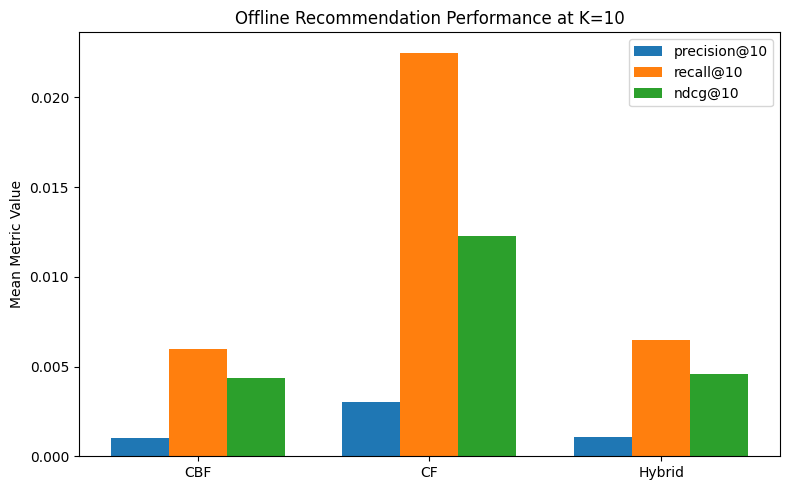

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics_plot = [
    "precision@10",
    "recall@10",
    "ndcg@10"
]

models = [
    "CBF",
    "CF",
    "Hybrid"
]

values = [
    [
        final_baseline_comparison.loc[
            metric,
            model
        ]
        for model in models
    ]
    for metric in metrics_plot
]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(
    figsize=(8, 5)
)

for i, metric in enumerate(metrics_plot):

    ax.bar(
        x + i * width,
        values[i],
        width,
        label=metric
    )

ax.set_xticks(
    x + width
)

ax.set_xticklabels(models)

ax.set_ylabel(
    "Mean Metric Value"
)

ax.set_title(
    "Offline Recommendation Performance at K=10"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    "figure_baseline_performance_k10.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

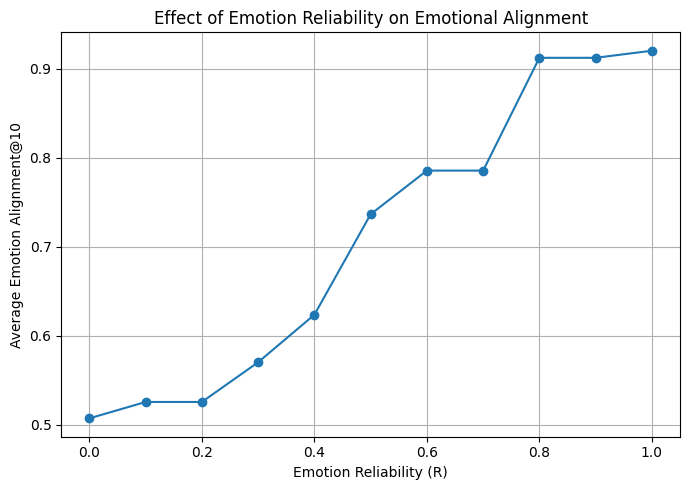

In [ ]:
plt.figure(
    figsize=(7, 5)
)

plt.plot(
    emotion_alignment_df["Reliability"],
    emotion_alignment_df[
        "Average Emotion Alignment@10"
    ],
    marker="o"
)

plt.xlabel(
    "Emotion Reliability (R)"
)

plt.ylabel(
    "Average Emotion Alignment@10"
)

plt.title(
    "Effect of Emotion Reliability on Emotional Alignment"
)

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "figure_reliability_vs_alignment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

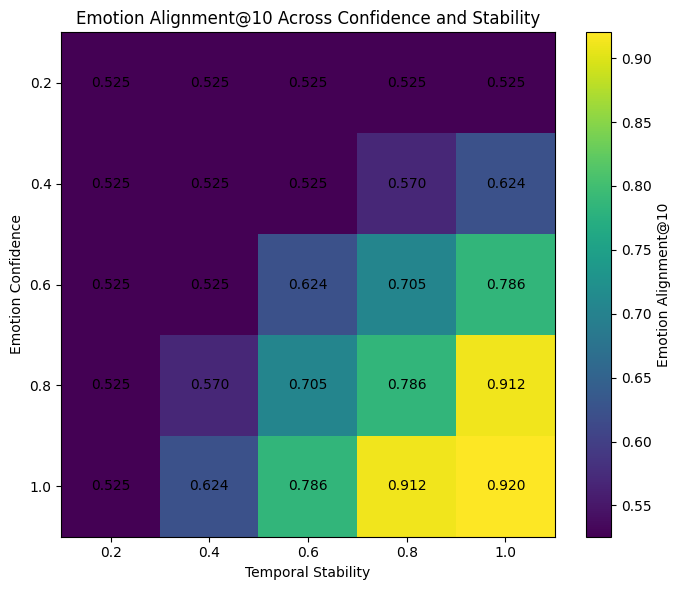

In [ ]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

image = ax.imshow(
    alignment_grid.values,
    aspect="auto"
)

ax.set_xticks(
    range(len(alignment_grid.columns))
)

ax.set_xticklabels(
    alignment_grid.columns
)

ax.set_yticks(
    range(len(alignment_grid.index))
)

ax.set_yticklabels(
    alignment_grid.index
)

ax.set_xlabel(
    "Temporal Stability"
)

ax.set_ylabel(
    "Emotion Confidence"
)

ax.set_title(
    "Emotion Alignment@10 Across Confidence and Stability"
)

for i in range(
    len(alignment_grid.index)
):
    for j in range(
        len(alignment_grid.columns)
    ):
        ax.text(
            j,
            i,
            f"{alignment_grid.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

fig.colorbar(
    image,
    ax=ax,
    label="Emotion Alignment@10"
)

plt.tight_layout()

plt.savefig(
    "figure_confidence_stability_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

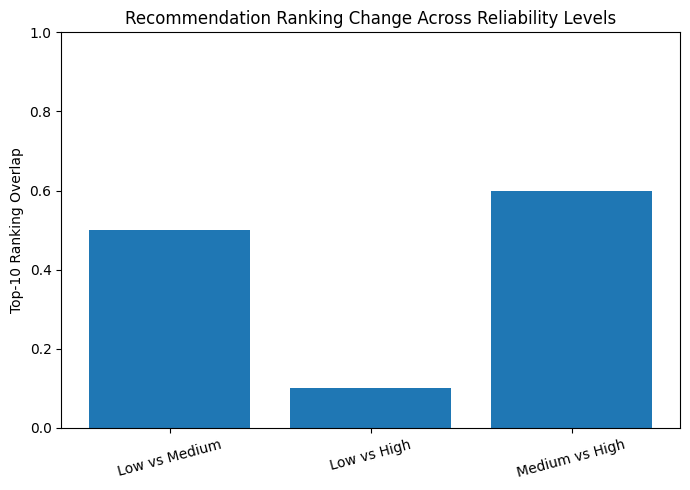

In [ ]:
plt.figure(
    figsize=(7, 5)
)

plt.bar(
    final_overlap_results[
        "Comparison"
    ],
    final_overlap_results[
        "Top10_Overlap"
    ]
)

plt.ylabel(
    "Top-10 Ranking Overlap"
)

plt.ylim(
    0,
    1
)

plt.title(
    "Recommendation Ranking Change Across Reliability Levels"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.savefig(
    "figure_ranking_overlap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
paper_statistical_table = (
    statistical_summary[
        statistical_summary[
            "Metric"
        ].isin([
            "precision@10",
            "recall@10",
            "ndcg@10"
        ])
    ]
    .copy()
)

paper_statistical_table[
    "Mean Difference"
] = paper_statistical_table[
    "Mean Difference"
].round(6)

paper_statistical_table[
    "CI Lower"
] = paper_statistical_table[
    "CI Lower"
].round(6)

paper_statistical_table[
    "CI Upper"
] = paper_statistical_table[
    "CI Upper"
].round(6)

paper_statistical_table[
    "p_value"
] = paper_statistical_table[
    "p_value"
].round(6)

paper_statistical_table

,Metric,Comparison,Mean Difference,CI Lower,CI Upper,p_value,Significance
9,precision@10,CF vs CBF,0.002000,0.000800,0.003200,0.001565,**
10,precision@10,CF vs HYBRID,0.001900,0.000700,0.003100,0.002347,**
11,precision@10,HYBRID vs CBF,0.000100,0.000000,0.000300,0.317311,ns
12,recall@10,CF vs CBF,0.016500,0.007415,0.025750,0.001496,**
13,recall@10,CF vs HYBRID,0.016000,0.006998,0.025167,0.002243,**
14,recall@10,HYBRID vs CBF,0.000500,0.000000,0.001500,0.317311,ns
15,ndcg@10,CF vs CBF,0.007859,0.002129,0.013751,0.001601,**
16,ndcg@10,CF vs HYBRID,0.007635,0.001911,0.013465,0.001613,**
17,ndcg@10,HYBRID vs CBF,0.000224,0.000000,0.000624,0.083265,ns


In [ ]:
paper_statistical_table.to_csv(
    "paper_table_statistical_comparison_k10.csv",
    index=False
)

In [ ]:
final_findings = pd.DataFrame([
    {
        "Finding":
        "Best offline baseline",

        "Result":
        "Collaborative Filtering",

        "Evidence":
        "Highest Precision, Recall and NDCG at K=5 and K=10"
    },

    {
        "Finding":
        "CF vs CBF at Recall@10",

        "Result":
        "CF significantly higher",

        "Evidence":
        "Mean difference=0.0165, p=0.001496"
    },

    {
        "Finding":
        "Reliability effect",

        "Result":
        "Emotion alignment increased",

        "Evidence":
        "0.63136 to 0.89826 as R increased from 0 to 1"
    },

    {
        "Finding":
        "Reliability-alignment correlation",

        "Result":
        "Strong positive relationship",

        "Evidence":
        "r=0.9776"
    },

    {
        "Finding":
        "Ranking sensitivity",

        "Result":
        "Substantial ranking change",

        "Evidence":
        "Low-vs-high Top-10 overlap=0.40"
    },

    {
        "Finding":
        "Multiplicative reliability",

        "Result":
        "Both confidence and stability matter",

        "Evidence":
        "High value of one factor alone does not produce high R"
    }
])

final_findings

,Finding,Result,Evidence
0,Best offline baseline,Collaborative Filtering,"Highest Precision, Recall and NDCG at K=5 and ..."
1,CF vs CBF at Recall@10,CF significantly higher,"Mean difference=0.0165, p=0.001496"
2,Reliability effect,Emotion alignment increased,0.63136 to 0.89826 as R increased from 0 to 1
3,Reliability-alignment correlation,Strong positive relationship,r=0.9776
4,Ranking sensitivity,Substantial ranking change,Low-vs-high Top-10 overlap=0.40
5,Multiplicative reliability,Both confidence and stability matter,High value of one factor alone does not produc...


In [ ]:
final_findings.to_csv(
    "final_research_findings.csv",
    index=False
)

In [ ]:
import zipfile
import os

output_files = [
    './final_research_findings.csv',
    './final_statistical_summary.csv',
    './final_win_loss_tie.csv',
    './final_emotion_alignment.csv',
    './final_ranking_overlap.csv',
    './final_reliability_ranking_comparison.csv',
    './paper_table_baseline_performance.csv',
    './final_baseline_comparison.csv',
    './final_wilcoxon_results.csv',
    './final_alignment_grid.csv',
    './final_reliability_weights.csv',
    './experiment_config.json',
    './final_hybrid_metrics.csv',
    './final_bootstrap_confidence_intervals.csv',
    './final_evaluation_users.csv',
    './experiment_manifest.csv',
    './final_cf_metrics.csv',
    './final_fer_observation.csv',
    './final_reliability_correlation.csv',
    './final_cbf_metrics.csv',
    './final_confidence_stability_grid.csv',
    './final_hit_rate_results.csv',
    './paper_table_statistical_comparison_k10.csv',
    './figure_ranking_overlap.png',
    './figure_confidence_stability_heatmap.png',
    './figure_reliability_vs_alignment.png',
    './figure_baseline_performance_k10.png'
]

zip_filename = 'project_outputs.zip'
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for file in output_files:
        if os.path.exists(file):
            zipf.write(file, os.path.basename(file))
        else:
            print(f"Warning: File not found and skipped: {file}")

print(f"All available output files have been zipped into '{zip_filename}'")

All available output files have been zipped into 'project_outputs.zip'


In [ ]:
# from google.colab import files
# files.download(zip_filename)

In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/datasets/devemo+"

print("Dataset exists:", os.path.exists(DATASET_PATH))

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print("\nFolder:", root)

    for file in files[:10]:
        print("  ", file)

Dataset exists: True

Folder: /content/drive/MyDrive/datasets/devemo+
   devemo+_002.mp4
   devemo+_004.mp4
   devemo+_001.mp4
   devemo+_003.mp4
   devemo+_008.mp4
   devemo+_010.mp4
   devemo+_006.mp4
   devemo+_009.mp4
   devemo+_005.mp4
   devemo+_012.mp4


In [ ]:
import json
import os
from pprint import pprint

DATASET_PATH = "/content/drive/MyDrive/datasets/devemo+"

JSON_PATH = os.path.join(DATASET_PATH, "devemo+.json")

with open(JSON_PATH, "r") as f:
    dataset_info = json.load(f)

print("JSON data type:", type(dataset_info))

if isinstance(dataset_info, dict):

    print("\nTop-level keys:")
    print(list(dataset_info.keys()))

    print("\nFirst record / sample:")
    pprint(dataset_info, depth=3)

elif isinstance(dataset_info, list):

    print("\nTotal records:", len(dataset_info))

    print("\nFirst record:")
    pprint(dataset_info[0] if dataset_info else None, depth=4)

JSON data type: <class 'list'>

Total records: 304

First record:
{'agreement_ratio': 0.67,
 'conditions': ['dark', 'glasses', 'backlight'],
 'duration': 5,
 'filename': 'devemo+_001.mp4',
 'gender': 'male',
 'label': 'Confusion',
 'participant': 'P1'}


In [ ]:
import glob
import os

video_files = glob.glob(
    os.path.join(DATASET_PATH, "*.mp4")
)

print("Total video files:", len(video_files))

print("\nVideo filenames:")
for video in sorted(video_files):
    print(os.path.basename(video))

Total video files: 304

Video filenames:
devemo+_001.mp4
devemo+_002.mp4
devemo+_003.mp4
devemo+_004.mp4
devemo+_005.mp4
devemo+_006.mp4
devemo+_007.mp4
devemo+_008.mp4
devemo+_009.mp4
devemo+_010.mp4
devemo+_011.mp4
devemo+_012.mp4
devemo+_013.mp4
devemo+_014.mp4
devemo+_015.mp4
devemo+_016.mp4
devemo+_017.mp4
devemo+_018.mp4
devemo+_019.mp4
devemo+_020.mp4
devemo+_021.mp4
devemo+_022.mp4
devemo+_023.mp4
devemo+_024.mp4
devemo+_025.mp4
devemo+_026.mp4
devemo+_027.mp4
devemo+_028.mp4
devemo+_029.mp4
devemo+_030.mp4
devemo+_031.mp4
devemo+_032.mp4
devemo+_033.mp4
devemo+_034.mp4
devemo+_035.mp4
devemo+_036.mp4
devemo+_037.mp4
devemo+_038.mp4
devemo+_039.mp4
devemo+_040.mp4
devemo+_041.mp4
devemo+_042.mp4
devemo+_043.mp4
devemo+_044.mp4
devemo+_045.mp4
devemo+_046.mp4
devemo+_047.mp4
devemo+_048.mp4
devemo+_049.mp4
devemo+_050.mp4
devemo+_051.mp4
devemo+_052.mp4
devemo+_053.mp4
devemo+_054.mp4
devemo+_055.mp4
devemo+_056.mp4
devemo+_057.mp4
devemo+_058.mp4
devemo+_059.mp4
devemo+_060.mp4

In [ ]:
import json
import pandas as pd
import os

DATASET_PATH = "/content/drive/MyDrive/datasets/devemo+"

JSON_PATH = os.path.join(DATASET_PATH, "devemo+.json")

with open(JSON_PATH, "r") as f:
    annotations = json.load(f)

df_devemo = pd.DataFrame(annotations)

# 1. Emotion distribution
print("EMOTION DISTRIBUTION")
print(df_devemo["label"].value_counts())

# 2. Number of participants
print("\nNUMBER OF PARTICIPANTS")
print(df_devemo["participant"].nunique())

print("\nVIDEOS PER PARTICIPANT")
print(df_devemo["participant"].value_counts())

# 3. Duration distribution
print("\nVIDEO DURATION")
print(df_devemo["duration"].describe())

# 4. Annotation agreement
print("\nANNOTATION AGREEMENT")
print(df_devemo["agreement_ratio"].describe())

# 5. Recording conditions
print("\nRECORDING CONDITIONS")
print(df_devemo["conditions"].explode().value_counts())

# 6. Check video files
video_count = sum(
    os.path.exists(os.path.join(DATASET_PATH, filename))
    for filename in df_devemo["filename"]
)

print("\nANNOTATED VIDEOS:", len(df_devemo))
print("VIDEO FILES FOUND:", video_count)

EMOTION DISTRIBUTION
label
Neutral      152
Confusion     79
Happiness     34
Surprise      25
Disgust        9
Anger          5
Name: count, dtype: int64

NUMBER OF PARTICIPANTS
51

VIDEOS PER PARTICIPANT
participant
P20    18
P32    18
P2     14
P15    14
P22    12
P16    12
P11    12
P25    10
P7     10
P10    10
P26    10
P37    10
P38    10
P24    10
P39    10
P8      8
P4      8
P23     8
P18     6
P9      6
P17     6
P35     6
P27     6
P33     6
P28     5
P42     4
P1      4
P48     4
P29     4
P13     2
P12     2
P6      2
P5      2
P3      2
P14     2
P19     2
P31     2
P30     2
P21     2
P43     2
P36     2
P41     2
P40     2
P47     2
P44     2
P46     2
P45     2
P50     2
P49     2
P51     2
P34     1
Name: count, dtype: int64

VIDEO DURATION
count    304.000000
mean       4.990132
std        0.250217
min        3.000000
25%        5.000000
50%        5.000000
75%        5.000000
max        7.000000
Name: duration, dtype: float64

ANNOTATION AGREEMENT
count    152.0000

Video: devemo+_001.mp4
Participant: P1
Ground truth: Confusion

Video information
FPS: 15.0
Total frames: 75
Resolution: 640 x 480
Duration: 5.0 seconds

Successfully extracted: 10


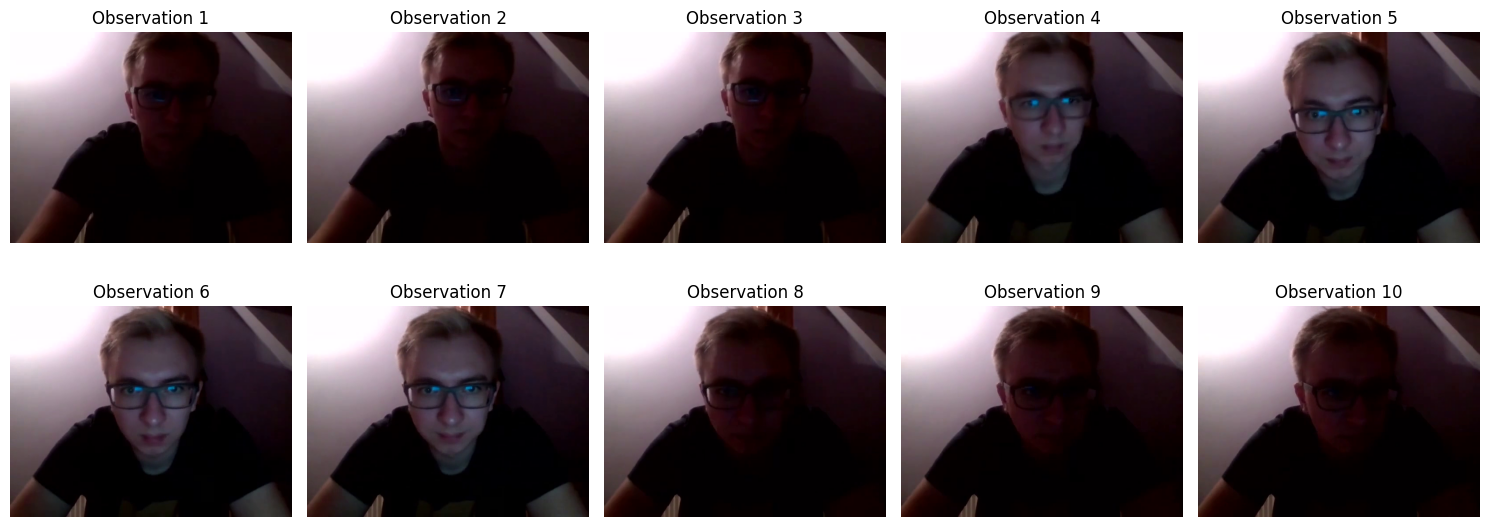

In [ ]:
import cv2
import os
import json
import matplotlib.pyplot as plt

DATASET_PATH = "/content/drive/MyDrive/datasets/devemo+"

# Load annotations
with open(os.path.join(DATASET_PATH, "devemo+.json"), "r") as f:
    annotations = json.load(f)

# Select the first video
sample = annotations[0]

video_path = os.path.join(
    DATASET_PATH,
    sample["filename"]
)

print("Video:", sample["filename"])
print("Participant:", sample["participant"])
print("Ground truth:", sample["label"])

# Open video
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = total_frames / fps if fps > 0 else 0

print("\nVideo information")
print("FPS:", fps)
print("Total frames:", total_frames)
print("Resolution:", width, "x", height)
print("Duration:", duration, "seconds")

# Extract 10 temporally distributed observations
sample_frames = []

for i in range(10):

    frame_index = int(i * (total_frames - 1) / 9)

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)

    ret, frame = cap.read()

    if ret:
        frame_rgb = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )
        sample_frames.append(frame_rgb)

cap.release()

print("\nSuccessfully extracted:", len(sample_frames))

# Display frames
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, ax in enumerate(axes.flat):

    if i < len(sample_frames):
        ax.imshow(sample_frames[i])
        ax.set_title(f"Observation {i+1}")

    ax.axis("off")

plt.tight_layout()
plt.show()

Extracted frames: 10
Frame indices: [30, 31, 32, 33, 34, 35, 36, 37, 38, 39]
Time interval: 0.6666666666666666 seconds


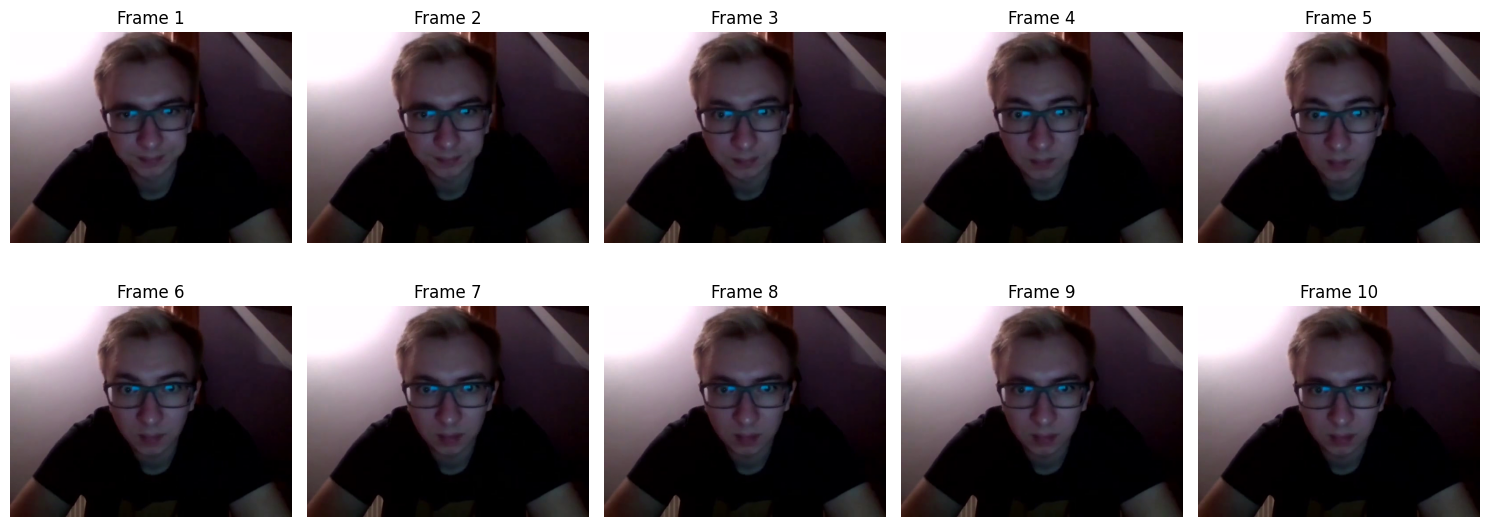

In [ ]:
import cv2
import os
import matplotlib.pyplot as plt

video_path = "/content/drive/MyDrive/datasets/devemo+/devemo+_001.mp4"

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

# Select a continuous sequence from the middle
start_frame = 30

consecutive_frames = []

for i in range(10):

    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame + i)

    ret, frame = cap.read()

    if not ret:
        print("Frame extraction failed at:", start_frame + i)
        break

    consecutive_frames.append(frame)

cap.release()

print("Extracted frames:", len(consecutive_frames))
print("Frame indices:", list(range(start_frame, start_frame + len(consecutive_frames))))
print("Time interval:", len(consecutive_frames) / fps, "seconds")

# Display
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, ax in enumerate(axes.flat):

    if i < len(consecutive_frames):
        frame_rgb = cv2.cvtColor(
            consecutive_frames[i],
            cv2.COLOR_BGR2RGB
        )

        ax.imshow(frame_rgb)
        ax.set_title(f"Frame {i+1}")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from deepface import DeepFace
import pandas as pd
import numpy as np

emotion_results = []

for i, frame in enumerate(consecutive_frames):

    try:
        result = DeepFace.analyze(
            img_path=frame,
            actions=['emotion'],
            detector_backend='opencv',
            enforce_detection=False,
            silent=True
        )

        # DeepFace may return a list or a dictionary
        if isinstance(result, list):
            result = result[0]

        emotion_scores = result['emotion']

        predicted_emotion = max(
            emotion_scores,
            key=emotion_scores.get
        )

        emotion_results.append({
            'frame': i + 1,
            'predicted_emotion': predicted_emotion,
            'confidence': max(emotion_scores.values()),
            **emotion_scores
        })

        print(
            f"Frame {i+1}: {predicted_emotion} | "
            f"Confidence: {max(emotion_scores.values()):.2f}"
        )

    except Exception as e:
        print(f"Frame {i+1} failed: {e}")

emotion_df = pd.DataFrame(emotion_results)

print("\nSuccessfully processed:", len(emotion_df))

display(emotion_df)

Frame 1: happy | Confidence: 36.53
Frame 2: angry | Confidence: 73.93
Frame 3: fear | Confidence: 47.99
Frame 4: fear | Confidence: 67.48
Frame 5: angry | Confidence: 42.62
Frame 6: fear | Confidence: 30.37
Frame 7: angry | Confidence: 85.42
Frame 8: fear | Confidence: 44.52
Frame 9: surprise | Confidence: 52.51
Frame 10: angry | Confidence: 85.26

Successfully processed: 10


,frame,predicted_emotion,confidence,angry,disgust,fear,happy,sad,surprise,neutral
0,1,happy,36.525848,31.093069,0.005036,25.935301,36.525848,4.992579,0.136050,1.312120
1,2,angry,73.930771,73.930771,0.000201,18.043879,4.959406,2.363580,0.036441,0.665718
2,3,fear,47.990025,27.786489,9.181423,47.990025,1.822193,1.867276,8.546157,2.806437
3,4,fear,67.484718,12.928372,0.323435,67.484718,0.221111,0.790106,18.107914,0.144340
4,5,angry,42.616135,42.616135,0.319429,22.649824,1.306193,1.901441,30.280787,0.926191
5,6,fear,30.366394,22.074314,0.341378,30.366394,4.384140,9.195568,20.087873,13.550338
6,7,angry,85.419548,85.419548,0.018460,9.019474,1.670071,3.105958,0.500675,0.265827
7,8,fear,44.519669,34.976200,0.780274,44.519669,0.345277,3.720740,12.061955,3.595880
8,9,surprise,52.511780,6.214706,1.286132,36.248150,0.935765,1.125953,52.511780,1.677513
9,10,angry,85.260544,85.260544,0.056010,11.724317,1.065765,1.587352,0.046770,0.259241


In [ ]:
emotion_columns = [
    'angry',
    'disgust',
    'fear',
    'happy',
    'sad',
    'surprise',
    'neutral'
]

average_emotions = emotion_df[emotion_columns].mean()

print("Average emotion probabilities:")
display(average_emotions.to_frame(name="Average probability"))

Average emotion probabilities:


,Average probability
angry,42.230019
disgust,1.231178
fear,31.398172
happy,5.323577
sad,3.065055
surprise,14.231639
neutral,2.520360


In [ ]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# DeepFace emotion probability columns
emotion_columns = [
    'angry',
    'disgust',
    'fear',
    'happy',
    'sad',
    'surprise',
    'neutral'
]

# Ten observations: seven-dimensional emotion vectors
E = emotion_df[emotion_columns].to_numpy(dtype=float)

# 1. Average confidence
frame_confidences = np.max(E, axis=1) / 100.0

C = np.mean(frame_confidences)

# 2. Temporal consistency between consecutive observations
cosine_values = []

for t in range(1, len(E)):

    similarity = cosine_similarity(
        E[t-1].reshape(1, -1),
        E[t].reshape(1, -1)
    )[0][0]

    cosine_values.append(similarity)

S = np.mean(cosine_values)

# 3. Reliability
R = C * S

# 4. Adaptive weights
gamma_max = 0.40

gamma = gamma_max * R
alpha = (1 - gamma) / 2
beta = (1 - gamma) / 2

print("RELIABILITY ANALYSIS")
print("--------------------")

print(f"Confidence (C): {C:.4f}")
print(f"Stability (S): {S:.4f}")
print(f"Reliability (R): {R:.4f}")

print("\nADAPTIVE WEIGHTS")
print("----------------")

print(f"CBF weight (alpha): {alpha:.4f}")
print(f"CF weight (beta): {beta:.4f}")
print(f"Emotion weight (gamma): {gamma:.4f}")

print("\nWeight sum:", alpha + beta + gamma)

RELIABILITY ANALYSIS
--------------------
Confidence (C): 0.5666
Stability (S): 0.6567
Reliability (R): 0.3721

ADAPTIVE WEIGHTS
----------------
CBF weight (alpha): 0.4256
CF weight (beta): 0.4256
Emotion weight (gamma): 0.1488

Weight sum: 1.0


In [ ]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Original five-dimensional emotion mapping
emotion_columns_5 = [
    'happy',
    'sad',
    'angry',
    'fear',
    'surprise'
]

# Extract five dimensions
E5_raw = emotion_df[emotion_columns_5].to_numpy(dtype=float)

# Normalize each frame's five-dimensional vector
row_sums = E5_raw.sum(axis=1, keepdims=True)

if np.any(row_sums == 0):
    raise ValueError("A frame has zero probability in the five selected emotions.")

E5 = E5_raw / row_sums

# Calculate confidence
C5 = np.mean(np.max(E5, axis=1))

# Calculate temporal stability
similarities = []

for t in range(1, len(E5)):
    similarity = cosine_similarity(
        E5[t-1].reshape(1, -1),
        E5[t].reshape(1, -1)
    )[0, 0]

    similarities.append(similarity)

S5 = np.mean(similarities)

# Calculate reliability
R5 = C5 * S5

# Adaptive weights
gamma_max = 0.40

gamma5 = gamma_max * R5
alpha5 = (1 - gamma5) / 2
beta5 = (1 - gamma5) / 2

# Aggregate emotion vector
mean_emotion = E5.mean(axis=0)
mean_emotion = mean_emotion / mean_emotion.sum()

print("FIVE-DIMENSIONAL RELIABILITY")
print("----------------------------")
print(f"Confidence: {C5:.6f}")
print(f"Stability:  {S5:.6f}")
print(f"Reliability: {R5:.6f}")

print("\nADAPTIVE WEIGHTS")
print("----------------")
print(f"CBF:     {alpha5:.6f}")
print(f"CF:      {beta5:.6f}")
print(f"Emotion: {gamma5:.6f}")

print("\nAGGREGATED EMOTION VECTOR")
for emotion, value in zip(
    ['joy', 'sadness', 'anger', 'fear', 'surprise'],
    mean_emotion
):
    print(f"{emotion}: {value:.6f}")

print("\nWeight sum:", alpha5 + beta5 + gamma5)

FIVE-DIMENSIONAL RELIABILITY
----------------------------
Confidence: 0.584053
Stability:  0.666088
Reliability: 0.389031

ADAPTIVE WEIGHTS
----------------
CBF:     0.422194
CF:      0.422194
Emotion: 0.155612

AGGREGATED EMOTION VECTOR
joy: 0.054782
sadness: 0.032717
anger: 0.433459
fear: 0.329695
surprise: 0.149348

Weight sum: 1.0


In [ ]:
# Check the variables required for leakage-safe evaluation

required_variables = [
    "train_ratings",
    "test_ratings",
    "eval_svd",
    "eval_user_factors",
    "eval_item_factors",
    "movies",
    "movie_ids",
    "common_movie_emotion_matrix",
    "movie_emotion_matrix",
    "tfidf_matrix",
    "cosine_sim"
]

for name in required_variables:
    if name in globals():
        obj = globals()[name]
        shape = getattr(obj, "shape", None)
        print(f"AVAILABLE: {name} | Shape: {shape}")
    else:
        print(f"MISSING: {name}")

AVAILABLE: train_ratings | Shape: (157269, 3)
AVAILABLE: test_ratings | Shape: (34451, 3)
AVAILABLE: eval_svd | Shape: None
AVAILABLE: eval_user_factors | Shape: (11685, 50)
AVAILABLE: eval_item_factors | Shape: (4064, 50)
AVAILABLE: movies | Shape: (4800, 26)
AVAILABLE: movie_ids | Shape: None
AVAILABLE: common_movie_emotion_matrix | Shape: (4800, 5)
AVAILABLE: movie_emotion_matrix | Shape: (4800, 8)
AVAILABLE: tfidf_matrix | Shape: (4800, 10000)
AVAILABLE: cosine_sim | Shape: (4800, 4800)


In [ ]:
print("===== EVALUATION ITEM MAPPING =====")

print("\n1. Evaluation user-item matrix:")
print("Shape:", eval_user_item_pivot.shape)
print("Index name:", eval_user_item_pivot.index.name)
print("Columns name:", eval_user_item_pivot.columns.name)

print("\n2. First 10 evaluation item IDs:")
print(list(eval_user_item_pivot.columns[:10]))

print("\n3. First 10 movie IDs in metadata:")
print(movies["movie_id"].head(10).tolist())

print("\n4. First 10 movie IDs in training data:")
print(train_ratings["item_id"].head(10).tolist())

print("\n5. Movie ID uniqueness:")
print("Metadata IDs unique:", movies["movie_id"].is_unique)
print("Evaluation IDs unique:", eval_user_item_pivot.columns.is_unique)

print("\n6. Emotion dimensions:")
print("COMMON_EMOTIONS:", COMMON_EMOTIONS)

print("\n7. Common emotion matrix:")
print("Shape:", common_movie_emotion_matrix.shape)

print("\n8. Evaluation item overlap with metadata:")
eval_ids = set(eval_user_item_pivot.columns)
metadata_ids = set(movies["movie_id"])

print("Evaluation item count:", len(eval_ids))
print("Metadata item count:", len(metadata_ids))
print("Intersection:", len(eval_ids & metadata_ids))
print("Evaluation items missing from metadata:",
      len(eval_ids - metadata_ids))

===== EVALUATION ITEM MAPPING =====

1. Evaluation user-item matrix:
Shape: (11685, 4064)
Index name: user_id
Columns name: item_id

2. First 10 evaluation item IDs:
[5, 11, 12, 13, 14, 16, 18, 19, 20, 22]

3. First 10 movie IDs in metadata:
[19995, 285, 206647, 49026, 49529, 559, 38757, 99861, 767, 209112]

4. First 10 movie IDs in training data:
[9801, 10950, 137113, 809, 318846, 9767, 7443, 45612, 39514, 670]

5. Movie ID uniqueness:
Metadata IDs unique: True
Evaluation IDs unique: True

6. Emotion dimensions:
COMMON_EMOTIONS: ['joy', 'sadness', 'anger', 'fear', 'surprise']

7. Common emotion matrix:
Shape: (4800, 5)

8. Evaluation item overlap with metadata:
Evaluation item count: 4064
Metadata item count: 4800
Intersection: 4064
Evaluation items missing from metadata: 0


In [ ]:
import numpy as np

# 1. Get the exact item order used by the evaluation CF model
eval_movie_ids = np.asarray(
    eval_user_item_pivot.columns
)

# 2. Map every metadata movie ID to its row position
metadata_id_to_idx = {
    movie_id: idx
    for idx, movie_id in enumerate(movies["movie_id"].values)
}

# 3. Find metadata row positions in evaluation item order
eval_movie_indices = np.array([
    metadata_id_to_idx[movie_id]
    for movie_id in eval_movie_ids
])

# 4. Align emotion matrix with evaluation item order
eval_emotion_matrix = common_movie_emotion_matrix[
    eval_movie_indices
].copy()

# 5. Align content similarity matrix with evaluation item order
eval_cosine_sim = cosine_sim[
    np.ix_(eval_movie_indices, eval_movie_indices)
].copy()

# 6. Verify alignment
assert len(eval_movie_ids) == 4064
assert eval_emotion_matrix.shape == (4064, 5)
assert eval_cosine_sim.shape == (4064, 4064)
assert eval_item_factors.shape[0] == 4064

assert np.array_equal(
    movies.iloc[eval_movie_indices]["movie_id"].values,
    eval_movie_ids
)

print("COMMON CATALOGUE ALIGNMENT SUCCESSFUL")
print("-------------------------------------")
print("Number of movies:", len(eval_movie_ids))
print("Emotion matrix:", eval_emotion_matrix.shape)
print("Content similarity:", eval_cosine_sim.shape)
print("CF item factors:", eval_item_factors.shape)
print("Emotion order:", COMMON_EMOTIONS)

print("\nFirst 10 aligned movie IDs:")
print(eval_movie_ids[:10])

print("\nFirst 10 aligned metadata positions:")
print(eval_movie_indices[:10])

COMMON CATALOGUE ALIGNMENT SUCCESSFUL
-------------------------------------
Number of movies: 4064
Emotion matrix: (4064, 5)
Content similarity: (4064, 4064)
CF item factors: (4064, 50)
Emotion order: ['joy', 'sadness', 'anger', 'fear', 'surprise']

First 10 aligned movie IDs:
[ 5 11 12 13 14 16 18 19 20 22]

First 10 aligned metadata positions:
[3764 2911  328  809 2516 2799  322 2638 4021  199]


In [ ]:
print("===== CBF / CF MAPPING VALIDATION =====")

# 1. Check movie ID lookup
print("\nMovie ID lookup:")
print("movie_ids type:", type(movie_ids))
print("movie_ids count:", len(movie_ids))
print("title_to_idx count:", len(title_to_idx))

# 2. Check content seed selection
test_user_id = train_ratings["user_id"].iloc[0]

seed_info = get_eval_seed_movie(test_user_id)

print("\nTraining-only seed:")
print("Test user:", test_user_id)
print("Seed information:", seed_info)

# 3. Check CBF scores
cbf_scores, seed_info = get_eval_cbf_scores(test_user_id)

print("\nCBF scores:")
print("Shape:", None if cbf_scores is None else cbf_scores.shape)

# 4. Check CF scores
cf_scores = get_eval_cf_scores(test_user_id)

print("\nCF scores:")
print("Shape:", cf_scores.shape)

# 5. Check movie-ID ordering
print("\nCF item order matches evaluation IDs:",
      np.array_equal(
          eval_user_item_pivot.columns.values,
          eval_movie_ids
      ))

print("\nEmotion matrix finite:",
      np.isfinite(eval_emotion_matrix).all())

print("Content similarity finite:",
      np.isfinite(eval_cosine_sim).all())

print("CF scores finite:",
      np.isfinite(cf_scores).all())

print("\n===== VALIDATION COMPLETE =====")

===== CBF / CF MAPPING VALIDATION =====

Movie ID lookup:
movie_ids type: <class 'set'>
movie_ids count: 4800
title_to_idx count: 4800

Training-only seed:
Test user: 3
Seed information: {'movie_id': 670, 'title': 'Oldboy', 'rating': 5.0}

CBF scores:
Shape: (4800,)

CF scores:
Shape: (4064,)

CF item order matches evaluation IDs: True

Emotion matrix finite: True
Content similarity finite: True
CF scores finite: True

===== VALIDATION COMPLETE =====


In [ ]:
# Use the existing training-only CBF function
cbf_scores_original, seed_info = get_eval_cbf_scores(test_user_id)

# Convert CBF scores from 4,800 metadata order
# into the 4,064-item evaluation order
eval_cbf_scores = cbf_scores_original[eval_movie_indices].copy()

# Get CF scores in evaluation order
eval_cf_scores = get_eval_cf_scores(test_user_id)

# Validation
assert eval_cbf_scores.shape == (4064,)
assert eval_cf_scores.shape == (4064,)

assert np.isfinite(eval_cbf_scores).all()
assert np.isfinite(eval_cf_scores).all()

print("CBF and CF alignment successful")
print("--------------------------------")
print("User ID:", test_user_id)
print("Seed movie:", seed_info)

print("\nCBF:")
print("Shape:", eval_cbf_scores.shape)
print("Min:", eval_cbf_scores.min())
print("Max:", eval_cbf_scores.max())

print("\nCF:")
print("Shape:", eval_cf_scores.shape)
print("Min:", eval_cf_scores.min())
print("Max:", eval_cf_scores.max())

print("\nEmotion:")
print("Shape:", eval_emotion_matrix.shape)

print("\nAll components use the same 4,064-item order.")

CBF and CF alignment successful
--------------------------------
User ID: 3
Seed movie: {'movie_id': 670, 'title': 'Oldboy', 'rating': 5.0}

CBF:
Shape: (4064,)
Min: 0.0
Max: 1.0000000000000002

CF:
Shape: (4064,)
Min: 3.808252819458001
Max: 3.8659727106387543

Emotion:
Shape: (4064, 5)

All components use the same 4,064-item order.


In [ ]:
# ==========================================
# STEP 5: NORMALIZE ALL THREE SCORE VECTORS
# ==========================================

# 1. CBF scores: already aligned to 4,064 items
S_cbf_eval = eval_normalize(eval_cbf_scores)

# 2. CF scores: already aligned to 4,064 items
S_cf_eval = eval_normalize(eval_cf_scores)

# 3. Emotion scores: use the current video-derived
# five-dimensional emotion vector
emotion_vector = np.asarray(mean_emotion, dtype=float)

assert emotion_vector.shape == (5,)
assert eval_emotion_matrix.shape == (4064, 5)

raw_emotion_scores = calculate_emotion_scores(
    emotion_vector,
    eval_emotion_matrix
)

S_emotion_eval = eval_normalize(raw_emotion_scores)

# 4. Validate all three components
assert S_cbf_eval.shape == (4064,)
assert S_cf_eval.shape == (4064,)
assert S_emotion_eval.shape == (4064,)

assert np.isfinite(S_cbf_eval).all()
assert np.isfinite(S_cf_eval).all()
assert np.isfinite(S_emotion_eval).all()

# 5. Display results
print("===== NORMALIZED SCORE VALIDATION =====")

for name, scores in [
    ("CBF", S_cbf_eval),
    ("CF", S_cf_eval),
    ("Emotion", S_emotion_eval)
]:
    print(f"\n{name}")
    print("Min:", scores.min())
    print("Max:", scores.max())
    print("Mean:", scores.mean())
    print("Standard deviation:", scores.std())

print("\nEmotion vector:")
for emotion, value in zip(COMMON_EMOTIONS, emotion_vector):
    print(f"{emotion}: {value:.6f}")

print("\nAll three score vectors are aligned and normalized.")

===== NORMALIZED SCORE VALIDATION =====

CBF
Min: 0.0
Max: 1.0
Mean: 0.009078737744217844
Standard deviation: 0.020271037144690522

CF
Min: 0.0
Max: 1.0
Mean: 0.4345211566111824
Standard deviation: 0.04113251348612878

Emotion
Min: 0.0
Max: 1.0
Mean: 0.23324161911290348
Standard deviation: 0.24950590975168357

Emotion vector:
joy: 0.054782
sadness: 0.032717
anger: 0.433459
fear: 0.329695
surprise: 0.149348

All three score vectors are aligned and normalized.


In [ ]:
# ==========================================
# STEP 6: EMOTION-ADAPTIVE RECOMMENDER
# ==========================================

def recommend_eval_emotion_adaptive(
    user_id,
    emotion_vector,
    emotion_reliability,
    k=10
):
    """
    Leakage-safe emotion-adaptive hybrid recommender.

    Components:
        CBF + CF + Emotion

    All scores use the aligned 4,064-item catalogue.
    """

    # 1. Get training-only CBF scores
    cbf_scores, seed_info = get_eval_cbf_scores(user_id)

    if cbf_scores is None:
        return []

    cbf_scores = cbf_scores[eval_movie_indices]

    # 2. Get training-only CF scores
    cf_scores = get_eval_cf_scores(user_id)

    # 3. Calculate emotion similarity scores
    emotion_scores = calculate_emotion_scores(
        emotion_vector,
        eval_emotion_matrix
    )

    # 4. Normalize each component
    S_cbf = eval_normalize(cbf_scores)
    S_cf = eval_normalize(cf_scores)
    S_emotion = eval_normalize(emotion_scores)

    # 5. Calculate adaptive weights
    alpha, beta, gamma = calculate_adaptive_weights(
        emotion_reliability
    )

    # 6. Calculate final adaptive scores
    final_scores = (
        alpha * S_cbf
        + beta * S_cf
        + gamma * S_emotion
    )

    # 7. Exclude movies seen in training
    seen_items = set(
        train_ratings[
            train_ratings["user_id"] == user_id
        ]["item_id"].values
    )

    seen_mask = np.isin(eval_movie_ids, list(seen_items))

    final_scores[seen_mask] = -np.inf

    # 8. Rank movies
    ranked_indices = np.argsort(final_scores)[::-1]

    recommended_ids = eval_movie_ids[ranked_indices][:k]

    return recommended_ids.tolist()

In [ ]:
# ==========================================
# STEP 7: SINGLE USER TEST
# ==========================================

test_user_id = 3

adaptive_recommendations = recommend_eval_emotion_adaptive(
    user_id=test_user_id,
    emotion_vector=mean_emotion,
    emotion_reliability=R5,
    k=10
)

alpha, beta, gamma = calculate_adaptive_weights(R5)

print("USER:", test_user_id)

print("\nVIDEO-DERIVED RELIABILITY:", round(R5, 6))

print("\nADAPTIVE WEIGHTS")
print("CBF:", round(alpha, 6))
print("CF:", round(beta, 6))
print("Emotion:", round(gamma, 6))

print("\nTOP 10 ADAPTIVE RECOMMENDATIONS")

for rank, movie_id in enumerate(adaptive_recommendations, 1):

    title = movies.loc[
        movies["movie_id"] == movie_id,
        "title"
    ].iloc[0]

    print(f"{rank}. {title} (Movie ID: {movie_id})")

# Verify no training-seen movies were recommended
seen_items = set(
    train_ratings[
        train_ratings["user_id"] == test_user_id
    ]["item_id"]
)

assert not (set(adaptive_recommendations) & seen_items)

print("\nTraining-seen movie exclusion: PASSED")
print("Recommendation count:", len(adaptive_recommendations))

USER: 3

VIDEO-DERIVED RELIABILITY: 0.389031

ADAPTIVE WEIGHTS
CBF: 0.422194
CF: 0.422194
Emotion: 0.155612

TOP 10 ADAPTIVE RECOMMENDATIONS
1. Jaws (Movie ID: 578)
2. Taxi Driver (Movie ID: 103)
3. Sin City (Movie ID: 187)
4. Se7en (Movie ID: 807)
5. Star Wars: Episode II - Attack of the Clones (Movie ID: 1894)
6. Groundhog Day (Movie ID: 137)
7. Die Hard (Movie ID: 562)
8. The Dark Knight (Movie ID: 155)
9. Back to the Future (Movie ID: 105)
10. American Beauty (Movie ID: 14)

Training-seen movie exclusion: PASSED
Recommendation count: 10


In [ ]:
# ==========================================
# STEP 8: FINAL EVALUATION READINESS CHECK
# ==========================================

print("===== EVALUATION READINESS =====")

checks = [
    "final_eval_users",
    "relevant_test_ratings",
    "precision_at_k",
    "recall_at_k",
    "ndcg_at_k",
    "get_eval_cbf_scores",
    "get_eval_cf_scores",
    "eval_normalize",
    "calculate_adaptive_weights",
    "calculate_emotion_scores"
]

for name in checks:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "MISSING"
    )

print("\nEvaluation users:", len(final_eval_users))
print("Unique users:", len(set(final_eval_users)))

print("\nHeld-out relevant ratings:", len(relevant_test_ratings))
print("Users with held-out relevant items:",
      relevant_test_ratings["user_id"].nunique())

print("\nEvaluation catalogue:", len(eval_movie_ids))
print("Emotion vector dimensions:", len(mean_emotion))
print("Reliability:", R5)

print("\nFirst 10 evaluation users:")
print(final_eval_users[:10])

===== EVALUATION READINESS =====
final_eval_users: AVAILABLE
relevant_test_ratings: AVAILABLE
precision_at_k: AVAILABLE
recall_at_k: AVAILABLE
ndcg_at_k: AVAILABLE
get_eval_cbf_scores: AVAILABLE
get_eval_cf_scores: AVAILABLE
eval_normalize: AVAILABLE
calculate_adaptive_weights: AVAILABLE
calculate_emotion_scores: AVAILABLE

Evaluation users: 1000
Unique users: 1000

Held-out relevant ratings: 14122
Users with held-out relevant items: 8466

Evaluation catalogue: 4064
Emotion vector dimensions: 5
Reliability: 0.3890309292446306

First 10 evaluation users:
[113900, 101116, 113027, 17016, 110176, 158267, 93248, 27967, 137399, 105747]


In [ ]:
# ==========================================
# STEP 9: HELD-OUT CATALOGUE COVERAGE
# ==========================================

eval_catalogue_set = set(eval_movie_ids.tolist())
selected_users_set = set(final_eval_users)

selected_relevant = relevant_test_ratings[
    relevant_test_ratings["user_id"].isin(selected_users_set)
].copy()

selected_relevant_ids = set(
    selected_relevant["item_id"].unique()
)

covered_ids = selected_relevant_ids & eval_catalogue_set
uncovered_ids = selected_relevant_ids - eval_catalogue_set

print("===== HELD-OUT CATALOGUE COVERAGE =====")

print("Selected evaluation users:", len(selected_users_set))
print("Relevant test interactions:", len(selected_relevant))
print("Unique relevant test movies:", len(selected_relevant_ids))

print("Relevant movies in common catalogue:", len(covered_ids))
print("Relevant movies outside catalogue:", len(uncovered_ids))

print(
    "Movie coverage:",
    round(len(covered_ids) / len(selected_relevant_ids) * 100, 2),
    "%"
)

# Count affected users
uncovered_by_user = (
    selected_relevant[
        ~selected_relevant["item_id"].isin(eval_catalogue_set)
    ]
    .groupby("user_id")["item_id"]
    .nunique()
)

print("\nUsers with at least one uncovered relevant movie:",
      len(uncovered_by_user))

print("Total selected users:", len(selected_users_set))

print("\nExample uncovered movie IDs:")
print(list(uncovered_ids)[:20])

===== HELD-OUT CATALOGUE COVERAGE =====
Selected evaluation users: 1000
Relevant test interactions: 1640
Unique relevant test movies: 925
Relevant movies in common catalogue: 921
Relevant movies outside catalogue: 4
Movie coverage: 99.57 %

Users with at least one uncovered relevant movie: 4
Total selected users: 1000

Example uncovered movie IDs:
[np.int64(13994), np.int64(29122), np.int64(14299), np.int64(3482)]


In [ ]:
# STEP 10: FILTER RELEVANT TEST ITEMS TO COMMON CATALOGUE

eval_catalogue_set = set(eval_movie_ids.tolist())
selected_users_set = set(final_eval_users)

selected_relevant = relevant_test_ratings[
    relevant_test_ratings["user_id"].isin(selected_users_set)
].copy()

# Keep only relevant movies available to all four models
selected_relevant_in_catalogue = selected_relevant[
    selected_relevant["item_id"].isin(eval_catalogue_set)
].copy()

# Count excluded interactions
excluded_interactions = len(selected_relevant) - len(
    selected_relevant_in_catalogue
)

# Relevant ground truth for each evaluation user
relevant_by_user = (
    selected_relevant_in_catalogue
    .groupby("user_id")["item_id"]
    .apply(set)
    .to_dict()
)

print("===== EVALUATION GROUND TRUTH =====")
print("Evaluation users:", len(final_eval_users))
print("Relevant interactions before filtering:", len(selected_relevant))
print("Relevant interactions after filtering:",
      len(selected_relevant_in_catalogue))
print("Excluded relevant interactions:", excluded_interactions)
print("Unique relevant movies retained:",
      selected_relevant_in_catalogue["item_id"].nunique())
print("Users with relevant movies in catalogue:", len(relevant_by_user))
print("Users without relevant movies:",
      len(final_eval_users) - len(relevant_by_user))

assert len(relevant_by_user) == len(final_eval_users), (
    "Some evaluation users have no relevant movies after catalogue filtering."
)

print("\nGround truth is ready for fair four-model evaluation.")

===== EVALUATION GROUND TRUTH =====
Evaluation users: 1000
Relevant interactions before filtering: 1640
Relevant interactions after filtering: 1636
Excluded relevant interactions: 4
Unique relevant movies retained: 921
Users with relevant movies in catalogue: 1000
Users without relevant movies: 0

Ground truth is ready for fair four-model evaluation.


In [ ]:
# STEP 11: FAIR FOUR-MODEL EVALUATION

import numpy as np
import pandas as pd

K_VALUES = [5, 10]

# Fixed emotion context from the DevEmo+ pilot
emotion_vector = np.asarray(mean_emotion, dtype=float)
emotion_reliability = float(R5)

# Proposed model's adaptive weights
alpha, beta, gamma = calculate_adaptive_weights(emotion_reliability)

print("Adaptive weights:")
print(f"CBF      : {alpha:.4f}")
print(f"CF       : {beta:.4f}")
print(f"Emotion  : {gamma:.4f}")
print("Weight sum:", round(alpha + beta + gamma, 6))


def calculate_metrics(recommended, relevant, k):
    recommended = recommended[:k]
    hits = len(set(recommended) & set(relevant))

    precision = hits / k
    recall = hits / len(relevant)

    dcg = sum(
        1 / np.log2(rank + 2)
        for rank, item in enumerate(recommended)
        if item in relevant
    )

    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 2)
        for rank in range(ideal_hits)
    )

    ndcg = dcg / idcg if idcg > 0 else 0.0

    return precision, recall, ndcg


def rank_scores(scores, user_id):
    scores = np.asarray(scores, dtype=float).copy()

    assert len(scores) == len(eval_movie_ids), (
        f"Candidate dimension mismatch for user {user_id}"
    )

    assert np.all(np.isfinite(scores)), (
        f"Non-finite scores found for user {user_id}"
    )

    # Exclude movies already watched in the training set
    seen_items = set(
        train_ratings.loc[
            train_ratings["user_id"] == user_id,
            "item_id"
        ].values
    )

    seen_mask = np.isin(eval_movie_ids, list(seen_items))
    scores[seen_mask] = -np.inf

    ranked_indices = np.argsort(scores)[::-1]

    return eval_movie_ids[ranked_indices[:10]].tolist()


results = []
alignment_scores = []

emotion_scores = calculate_emotion_scores(
    emotion_vector,
    eval_emotion_matrix
)

for count, user_id in enumerate(final_eval_users, start=1):

    # 1. CBF scores: map metadata order to common catalogue order
    cbf_original, seed_info = get_eval_cbf_scores(user_id)

    if cbf_original is None:
        raise ValueError(f"CBF scores unavailable for user {user_id}")

    cbf_scores = np.asarray(cbf_original)[eval_movie_indices]

    # 2. CF scores
    cf_scores = np.asarray(get_eval_cf_scores(user_id))

    # 3. Normalize each score vector over the common catalogue
    S_cbf = eval_normalize(cbf_scores)
    S_cf = eval_normalize(cf_scores)
    S_emotion = eval_normalize(emotion_scores)

    # 4. Four model score combinations
    model_scores = {
        "CBF": S_cbf,
        "CF": S_cf,
        "Static_Hybrid": 0.5 * S_cbf + 0.5 * S_cf,
        "Emotion_Adaptive": (
            alpha * S_cbf
            + beta * S_cf
            + gamma * S_emotion
        )
    }

    relevant_items = relevant_by_user[user_id]

    user_result = {"user_id": user_id}

    for model_name, scores in model_scores.items():

        recommendations = rank_scores(scores, user_id)

        # Ensure no duplicate recommendations
        assert len(recommendations) == len(set(recommendations))

        # Ensure no training-history leakage
        seen_items = set(
            train_ratings.loc[
                train_ratings["user_id"] == user_id,
                "item_id"
            ].values
        )

        assert not (set(recommendations) & seen_items), (
            f"Seen-item leakage: {model_name}, user {user_id}"
        )

        for k in K_VALUES:
            p, r, n = calculate_metrics(
                recommendations,
                relevant_items,
                k
            )

            user_result[f"{model_name}_P@{k}"] = p
            user_result[f"{model_name}_R@{k}"] = r
            user_result[f"{model_name}_NDCG@{k}"] = n

        # Affect alignment: average emotion score of top-10 movies
        recommended_indices = [
            np.where(eval_movie_ids == movie_id)[0][0]
            for movie_id in recommendations
        ]

        user_result[f"{model_name}_EmotionAlignment@10"] = float(
            np.mean(emotion_scores[recommended_indices])
        )

    results.append(user_result)

    if count % 100 == 0:
        print(f"Evaluated {count}/{len(final_eval_users)} users")


# Store user-level results
four_model_results = pd.DataFrame(results)

print("\n===== EVALUATION COMPLETED =====")
print("Users evaluated:", len(four_model_results))
print("Result shape:", four_model_results.shape)

assert len(four_model_results) == 1000
assert four_model_results["user_id"].nunique() == 1000

# Summary table
metric_columns = [
    column for column in four_model_results.columns
    if column != "user_id"
]

summary = four_model_results[metric_columns].mean().to_frame(
    name="Mean"
)

print("\n===== FOUR-MODEL RESULTS =====")
display(summary.round(6))

Adaptive weights:
CBF      : 0.4222
CF       : 0.4222
Emotion  : 0.1556
Weight sum: 1.0
Evaluated 100/1000 users
Evaluated 200/1000 users
Evaluated 300/1000 users
Evaluated 400/1000 users
Evaluated 500/1000 users
Evaluated 600/1000 users
Evaluated 700/1000 users
Evaluated 800/1000 users
Evaluated 900/1000 users
Evaluated 1000/1000 users

===== EVALUATION COMPLETED =====
Users evaluated: 1000
Result shape: (1000, 29)

===== FOUR-MODEL RESULTS =====


,Mean
CBF_P@5,0.001800
CBF_R@5,0.005750
CBF_NDCG@5,0.004296
CBF_P@10,0.001000
CBF_R@10,0.006000
CBF_NDCG@10,0.004435
CBF_EmotionAlignment@10,0.278722
CF_P@5,0.003600
CF_R@5,0.012500
CF_NDCG@5,0.008917


In [ ]:
# STEP 12: PAIRED STATISTICAL SIGNIFICANCE TESTS

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

rng = np.random.default_rng(42)
N_BOOTSTRAP = 10000

metrics = [
    "P@5", "R@5", "NDCG@5",
    "P@10", "R@10", "NDCG@10"
]

comparisons = ["CF", "Static_Hybrid"]

statistical_results = []

for baseline in comparisons:

    for metric in metrics:

        adaptive_col = f"Emotion_Adaptive_{metric}"
        baseline_col = f"{baseline}_{metric}"

        adaptive_values = four_model_results[adaptive_col].to_numpy()
        baseline_values = four_model_results[baseline_col].to_numpy()

        # Paired difference: positive means adaptive is better
        differences = adaptive_values - baseline_values

        mean_difference = np.mean(differences)
        median_difference = np.median(differences)

        # Paired bootstrap confidence interval
        bootstrap_means = []

        for _ in range(N_BOOTSTRAP):
            sampled = rng.choice(
                differences,
                size=len(differences),
                replace=True
            )
            bootstrap_means.append(np.mean(sampled))

        ci_lower, ci_upper = np.percentile(
            bootstrap_means, [2.5, 97.5]
        )

        # Wilcoxon signed-rank test
        if np.allclose(differences, 0):
            p_value = 1.0
        else:
            p_value = wilcoxon(
                differences,
                alternative="two-sided",
                zero_method="wilcox"
            ).pvalue

        statistical_results.append({
            "Comparison": f"Adaptive vs {baseline}",
            "Metric": metric,
            "Mean_Difference": mean_difference,
            "Median_Difference": median_difference,
            "CI_95_Lower": ci_lower,
            "CI_95_Upper": ci_upper,
            "P_Value": p_value
        })


# Holm correction across all 12 tests
p_values = [
    row["P_Value"] for row in statistical_results
]

adjusted = multipletests(
    p_values,
    method="holm"
)[1]

for row, adjusted_p in zip(statistical_results, adjusted):
    row["Holm_Adjusted_P"] = adjusted_p
    row["Significant_0.05"] = adjusted_p < 0.05

statistical_df = pd.DataFrame(statistical_results)

print("===== PAIRED STATISTICAL COMPARISONS =====")
display(statistical_df.round(7))

===== PAIRED STATISTICAL COMPARISONS =====


,Comparison,Metric,Mean_Difference,Median_Difference,CI_95_Lower,CI_95_Upper,P_Value,Holm_Adjusted_P,Significant_0.05
0,Adaptive vs CF,P@5,-0.000200,0.0,-0.002000,0.001600,0.834827,1.000000,False
1,Adaptive vs CF,R@5,-0.000500,0.0,-0.007250,0.006500,0.851706,1.000000,False
2,Adaptive vs CF,NDCG@5,-0.002101,0.0,-0.007296,0.002764,0.435008,1.000000,False
3,Adaptive vs CF,P@10,-0.000800,0.0,-0.002000,0.000300,0.157299,1.000000,False
4,Adaptive vs CF,R@10,-0.007667,0.0,-0.016333,0.000417,0.066288,0.795455,False
5,Adaptive vs CF,NDCG@10,-0.004354,0.0,-0.009548,0.000654,0.072666,0.799323,False
6,Adaptive vs Static_Hybrid,P@5,0.000600,0.0,-0.000800,0.002200,0.438578,1.000000,False
7,Adaptive vs Static_Hybrid,R@5,0.002000,0.0,-0.003500,0.007500,0.524334,1.000000,False
8,Adaptive vs Static_Hybrid,NDCG@5,-0.000526,0.0,-0.004321,0.002910,0.944475,1.000000,False
9,Adaptive vs Static_Hybrid,P@10,-0.000700,0.0,-0.001700,0.000300,0.177932,1.000000,False


In [ ]:
# STEP 13: USER-LEVEL IMPACT ANALYSIS

metrics = [
    "P@5", "R@5", "NDCG@5",
    "P@10", "R@10", "NDCG@10"
]

comparisons = ["CF", "Static_Hybrid"]

impact_results = []

for baseline in comparisons:

    for metric in metrics:

        adaptive = four_model_results[
            f"Emotion_Adaptive_{metric}"
        ]

        baseline_values = four_model_results[
            f"{baseline}_{metric}"
        ]

        differences = (
            adaptive.to_numpy() - baseline_values.to_numpy()
        )

        impact_results.append({
            "Comparison": f"Adaptive vs {baseline}",
            "Metric": metric,
            "Improved_users": int(np.sum(differences > 1e-12)),
            "Unchanged_users": int(np.sum(np.abs(differences) <= 1e-12)),
            "Declined_users": int(np.sum(differences < -1e-12)),
            "Total_users": len(differences)
        })

impact_df = pd.DataFrame(impact_results)

print("===== USER-LEVEL IMPACT =====")
display(impact_df)

===== USER-LEVEL IMPACT =====


,Comparison,Metric,Improved_users,Unchanged_users,Declined_users,Total_users
0,Adaptive vs CF,P@5,11,977,12,1000
1,Adaptive vs CF,R@5,11,977,12,1000
2,Adaptive vs CF,NDCG@5,13,971,16,1000
3,Adaptive vs CF,P@10,12,968,20,1000
4,Adaptive vs CF,R@10,12,968,20,1000
5,Adaptive vs CF,NDCG@10,16,958,26,1000
6,Adaptive vs Static_Hybrid,P@5,9,985,6,1000
7,Adaptive vs Static_Hybrid,R@5,9,985,6,1000
8,Adaptive vs Static_Hybrid,NDCG@5,11,979,10,1000
9,Adaptive vs Static_Hybrid,P@10,10,973,17,1000


In [ ]:
# STEP 14: RELIABILITY SENSITIVITY ANALYSIS

reliability_levels = [0.0, 0.25, 0.50, 0.75, 1.0]

sensitivity_results = []

for reliability in reliability_levels:

    alpha, beta, gamma = calculate_adaptive_weights(reliability)

    user_metrics = []

    for user_id in final_eval_users:

        cbf_original, seed_info = get_eval_cbf_scores(user_id)

        if cbf_original is None:
            raise ValueError(f"Missing CBF scores for {user_id}")

        cbf_scores = np.asarray(cbf_original)[eval_movie_indices]
        cf_scores = np.asarray(get_eval_cf_scores(user_id))

        S_cbf = eval_normalize(cbf_scores)
        S_cf = eval_normalize(cf_scores)
        S_emotion = eval_normalize(
            calculate_emotion_scores(
                emotion_vector,
                eval_emotion_matrix
            )
        )

        final_scores = (
            alpha * S_cbf
            + beta * S_cf
            + gamma * S_emotion
        )

        recommendations = rank_scores(final_scores, user_id)
        relevant_items = relevant_by_user[user_id]

        row = {}

        for k in [5, 10]:
            p, r, n = calculate_metrics(
                recommendations,
                relevant_items,
                k
            )

            row[f"P@{k}"] = p
            row[f"R@{k}"] = r
            row[f"NDCG@{k}"] = n

        recommended_indices = [
            np.where(eval_movie_ids == movie_id)[0][0]
            for movie_id in recommendations
        ]

        row["EmotionAlignment@10"] = float(
            np.mean(emotion_scores[recommended_indices])
        )

        user_metrics.append(row)

    user_df = pd.DataFrame(user_metrics)

    sensitivity_results.append({
        "Reliability": reliability,
        "CBF_Weight": alpha,
        "CF_Weight": beta,
        "Emotion_Weight": gamma,
        **user_df.mean().to_dict()
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("===== RELIABILITY SENSITIVITY RESULTS =====")
display(sensitivity_df.round(6))

===== RELIABILITY SENSITIVITY RESULTS =====


,Reliability,CBF_Weight,CF_Weight,Emotion_Weight,P@5,R@5,NDCG@5,P@10,R@10,NDCG@10,EmotionAlignment@10
0,0.00,0.50,0.50,0.0,0.0028,0.010000,0.007342,0.0029,0.021417,0.011223,0.320933
1,0.25,0.45,0.45,0.1,0.0034,0.011750,0.007171,0.0024,0.016333,0.008854,0.670173
2,0.50,0.40,0.40,0.2,0.0024,0.008500,0.005427,0.0018,0.011833,0.006680,0.849641
3,0.75,0.35,0.35,0.3,0.0018,0.004833,0.004357,0.0011,0.006167,0.004826,0.921082
4,1.00,0.30,0.30,0.4,0.0012,0.003500,0.002923,0.0009,0.005333,0.003596,0.945892


In [ ]:
# STEP 15: DEVEMO+ DATASET VERIFICATION

import os
import json
import pandas as pd

DEVEMO_DIR = "/content/drive/MyDrive/datasets/devemo+"
JSON_PATH = os.path.join(DEVEMO_DIR, "devemo+.json")

assert os.path.exists(JSON_PATH), "DevEmo+ JSON file not found!"

with open(JSON_PATH, "r") as f:
    devemo_data = json.load(f)

devemo_df = pd.DataFrame(devemo_data)

# Verify video files
devemo_df["video_path"] = devemo_df["filename"].apply(
    lambda x: os.path.join(DEVEMO_DIR, x)
)

devemo_df["file_exists"] = devemo_df["video_path"].apply(
    os.path.exists
)

print("===== DEVEMO+ DATASET CHECK =====")
print("Total annotations:", len(devemo_df))
print("Existing video files:", devemo_df["file_exists"].sum())
print("Missing video files:", (~devemo_df["file_exists"]).sum())

print("\n===== GROUND-TRUTH LABEL DISTRIBUTION =====")
display(devemo_df["label"].value_counts().to_frame("Video_Count"))

print("\n===== PARTICIPANT INFORMATION =====")
print("Unique participants:", devemo_df["participant"].nunique())

print("\n===== RECORDING CONDITIONS =====")
condition_counts = (
    devemo_df["conditions"]
    .explode()
    .value_counts()
    .to_frame("Video_Count")
)
display(condition_counts)

assert devemo_df["file_exists"].all()
assert len(devemo_df) == 304

print("\nDataset verification successful.")

===== DEVEMO+ DATASET CHECK =====
Total annotations: 304
Existing video files: 304
Missing video files: 0

===== GROUND-TRUTH LABEL DISTRIBUTION =====


,Video_Count
label,
Neutral,152
Confusion,79
Happiness,34
Surprise,25
Disgust,9
Anger,5



===== PARTICIPANT INFORMATION =====
Unique participants: 51

===== RECORDING CONDITIONS =====


,Video_Count
conditions,
glasses,96
backlight,78
blurry,68
shaky,60
hands,35
headphones,31
dark,23
bottom_camera,15



Dataset verification successful.


In [ ]:
# STEP 16: MULTI-VIDEO DEEProbe EMOTION AND RELIABILITY ANALYSIS

import os
import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from deepface import DeepFace

# Keep the five emotion dimensions used by the recommendation model
EMOTIONS_5 = ["joy", "sadness", "anger", "fear", "surprise"]

# Map DeepFace output names to our five dimensions
DEEProbe_MAP = {
    "happy": "joy",
    "sad": "sadness",
    "angry": "anger",
    "fear": "fear",
    "surprise": "surprise"
}

# DevEmo+ labels directly supported by our model
PREDICTION_TO_GROUND_TRUTH = {
    "joy": "Happiness",
    "surprise": "Surprise",
    "anger": "Anger"
}

FRAME_COUNT = 10

video_results = []
frame_results = []
processing_errors = []

for _, record in tqdm(
    devemo_df.iterrows(),
    total=len(devemo_df),
    desc="Processing DevEmo+ videos"
):

    video_path = record["video_path"]

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        processing_errors.append({
            "filename": record["filename"],
            "error": "Could not open video"
        })
        continue

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(cap.get(cv2.CAP_PROP_FPS))

    if total_frames < FRAME_COUNT:
        cap.release()
        processing_errors.append({
            "filename": record["filename"],
            "error": "Fewer than 10 frames"
        })
        continue

    # Select 10 consecutive frames around the video midpoint
    start_frame = max(0, (total_frames // 2) - (FRAME_COUNT // 2))
    frame_indices = list(range(start_frame, start_frame + FRAME_COUNT))

    frame_predictions = []
    frame_confidences = []
    frame_records = []

    try:
        for frame_number in frame_indices:

            cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
            success, frame = cap.read()

            if not success:
                raise ValueError(
                    f"Could not read frame {frame_number}"
                )

            # Use the same DeepFace analysis approach as the pilot
            analysis = DeepFace.analyze(
                img_path=frame,
                actions=["emotion"],
                enforce_detection=False
            )

            if isinstance(analysis, list):
                analysis = analysis[0]

            raw_emotions = analysis["emotion"]

            # Retain and map the five emotion dimensions
            probabilities = {
                emotion: float(raw_emotions[source])
                for source, emotion in DEEProbe_MAP.items()
            }

            probability_sum = sum(probabilities.values())

            if probability_sum <= 0:
                raise ValueError("Five-class probability sum is zero")

            # Renormalize the retained five classes
            normalized = {
                emotion: value / probability_sum
                for emotion, value in probabilities.items()
            }

            predicted_emotion = max(
                normalized,
                key=normalized.get
            )

            confidence = max(normalized.values())

            frame_predictions.append(predicted_emotion)
            frame_confidences.append(confidence)

            frame_records.append({
                "filename": record["filename"],
                "participant": record["participant"],
                "frame_number": frame_number,
                "predicted_emotion": predicted_emotion,
                "confidence": confidence,
                **{
                    f"prob_{emotion}": normalized[emotion]
                    for emotion in EMOTIONS_5
                }
            })

        # Confidence: average maximum five-class probability
        C = float(np.mean(frame_confidences))

        # Stability: proportion of adjacent predictions that agree
        adjacent_matches = sum(
            frame_predictions[i] == frame_predictions[i - 1]
            for i in range(1, FRAME_COUNT)
        )

        S = adjacent_matches / (FRAME_COUNT - 1)

        # Proposed reliability score
        R = C * S

        # Average five-dimensional emotion vector
        mean_vector = {
            emotion: float(np.mean([
                item[f"prob_{emotion}"]
                for item in frame_records
            ]))
            for emotion in EMOTIONS_5
        }

        # Predicted video-level emotion: majority vote
        predicted_video_emotion = max(
            set(frame_predictions),
            key=frame_predictions.count
        )

        # Ground-truth comparison only for supported categories
        ground_truth = record["label"]

        mapped_ground_truth = (
            ground_truth in ["Happiness", "Surprise", "Anger"]
        )

        if mapped_ground_truth:
            predicted_ground_truth = (
                PREDICTION_TO_GROUND_TRUTH[predicted_video_emotion]
                if predicted_video_emotion in PREDICTION_TO_GROUND_TRUTH
                else None
            )

            correct = (
                predicted_ground_truth == ground_truth
            ) if predicted_ground_truth is not None else False
        else:
            predicted_ground_truth = None
            correct = None

        video_results.append({
            "filename": record["filename"],
            "participant": record["participant"],
            "ground_truth": ground_truth,
            "conditions": record["conditions"],
            "fps": fps,
            "total_frames": total_frames,
            "start_frame": start_frame,
            "C": C,
            "S": S,
            "R": R,
            "predicted_video_emotion": predicted_video_emotion,
            "mapped_ground_truth": mapped_ground_truth,
            "predicted_ground_truth": predicted_ground_truth,
            "correct": correct,
            **mean_vector
        })

        frame_results.extend(frame_records)

    except Exception as error:
        processing_errors.append({
            "filename": record["filename"],
            "error": str(error)
        })

    finally:
        cap.release()


# Convert results to DataFrames
video_results_df = pd.DataFrame(video_results)
frame_results_df = pd.DataFrame(frame_results)
processing_errors_df = pd.DataFrame(processing_errors)

print("\n===== VIDEO PROCESSING SUMMARY =====")
print("Videos in dataset:", len(devemo_df))
print("Successfully processed:", len(video_results_df))
print("Failed videos:", len(processing_errors_df))
print("Frame predictions:", len(frame_results_df))

if len(video_results_df) > 0:
    print("\n===== RELIABILITY SUMMARY =====")
    display(
        video_results_df[["C", "S", "R"]]
        .describe()
        .round(4)
    )

    print("\n===== RESULTS BY GROUND-TRUTH LABEL =====")
    display(
        video_results_df.groupby("ground_truth")
        .agg(
            videos=("filename", "count"),
            mean_confidence=("C", "mean"),
            mean_stability=("S", "mean"),
            mean_reliability=("R", "mean")
        )
        .round(4)
    )

if len(processing_errors_df) > 0:
    print("\n===== PROCESSING ERRORS =====")
    display(processing_errors_df.head(20))

Processing DevEmo+ videos:   0%|          | 0/304 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:

# ============================================================
# STEP 11B: CF-PRIORITIZED EMOTION-ADAPTIVE HYBRID EVALUATION
# CBF : CF = 1 : 2
#
# Original Cell 251 remains unchanged.
# Uses the same users, candidates, ground truth and FER context.
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

K_VALUES_NEW = [5, 10]
GAMMA_MAX_NEW = 0.40
CBF_CF_RATIO_NEW = 1 / 2  # CBF receives 1 unit; CF receives 2

# Same affect context and reliability as original experiment
emotion_vector_new = np.asarray(mean_emotion, dtype=float)
reliability_new = float(R5)

# New adaptive weights
gamma_new = GAMMA_MAX_NEW * reliability_new

alpha_new = (1 - gamma_new) / 3
beta_new = 2 * (1 - gamma_new) / 3

print("=" * 60)
print("CF-PRIORITIZED EMOTION-ADAPTIVE MODEL")
print("=" * 60)

print(f"Reliability (R): {reliability_new:.6f}")
print(f"CBF Weight:      {alpha_new:.6f}")
print(f"CF Weight:       {beta_new:.6f}")
print(f"Emotion Weight:  {gamma_new:.6f}")
print(f"Total Weight:    {alpha_new + beta_new + gamma_new:.6f}")

assert np.isclose(alpha_new + beta_new + gamma_new, 1.0)
assert np.isclose(beta_new, 2 * alpha_new)

# ------------------------------------------------------------
# 2. PREPARE EMOTION SCORES
# ------------------------------------------------------------

emotion_scores_new = calculate_emotion_scores(
    emotion_vector_new,
    eval_emotion_matrix
)

S_emotion_new = eval_normalize(emotion_scores_new)

# ------------------------------------------------------------
# 3. EVALUATE THE NEW MODEL
# ------------------------------------------------------------

new_model_results = []

for count, user_id in enumerate(final_eval_users, start=1):

    # CBF scores in common evaluation catalogue order
    cbf_original, seed_info = get_eval_cbf_scores(user_id)

    if cbf_original is None:
        raise ValueError(
            f"CBF scores unavailable for user {user_id}"
        )

    cbf_scores = np.asarray(cbf_original)[eval_movie_indices]

    # CF scores
    cf_scores = np.asarray(
        get_eval_cf_scores(user_id)
    )

    # Normalize scores using the existing normalization function
    S_cbf_new = eval_normalize(cbf_scores)
    S_cf_new = eval_normalize(cf_scores)

    # New CF-prioritized fusion
    final_scores_new = (
        alpha_new * S_cbf_new
        + beta_new * S_cf_new
        + gamma_new * S_emotion_new
    )

    # Rank using the existing leakage-safe ranking function
    recommendations_new = rank_scores(
        final_scores_new,
        user_id
    )

    relevant_items = relevant_by_user[user_id]

    user_row = {"user_id": user_id}

    # Precision, Recall and NDCG
    for k in K_VALUES_NEW:

        p, r, n = calculate_metrics(
            recommendations_new,
            relevant_items,
            k
        )

        user_row[f"P@{k}"] = p
        user_row[f"R@{k}"] = r
        user_row[f"NDCG@{k}"] = n

    # Emotion Alignment@10
    recommended_indices = [
        np.where(eval_movie_ids == movie_id)[0][0]
        for movie_id in recommendations_new
    ]

    user_row["EmotionAlignment@10"] = float(
        np.mean(
            emotion_scores_new[recommended_indices]
        )
    )

    new_model_results.append(user_row)

    if count % 100 == 0:
        print(
            f"Evaluated {count}/{len(final_eval_users)} users"
        )

# ------------------------------------------------------------
# 4. STORE NEW MODEL RESULTS
# ------------------------------------------------------------

cf_prioritized_results = pd.DataFrame(
    new_model_results
)

print("\nNew model evaluation completed.")
print("Users evaluated:", len(cf_prioritized_results))
print("Result shape:", cf_prioritized_results.shape)

assert len(cf_prioritized_results) == len(final_eval_users)
assert cf_prioritized_results["user_id"].nunique() == len(final_eval_users)

# ------------------------------------------------------------
# 5. SUMMARY OF NEW MODEL
# ------------------------------------------------------------

new_summary = (
    cf_prioritized_results
    .drop(columns=["user_id"])
    .mean()
    .to_frame(name="CF_Prioritized_Emotion_Adaptive")
)

print("\n===== NEW MODEL PERFORMANCE =====")
display(new_summary.round(6))

# ------------------------------------------------------------
# 6. COMPARE OLD AND NEW MODELS
# ------------------------------------------------------------

comparison_columns = {
    "P@5": "Emotion_Adaptive_P@5",
    "R@5": "Emotion_Adaptive_R@5",
    "NDCG@5": "Emotion_Adaptive_NDCG@5",
    "P@10": "Emotion_Adaptive_P@10",
    "R@10": "Emotion_Adaptive_R@10",
    "NDCG@10": "Emotion_Adaptive_NDCG@10",
    "EmotionAlignment@10": "Emotion_Adaptive_EmotionAlignment@10"
}

comparison_rows = []

for metric, old_column in comparison_columns.items():

    comparison_rows.append({
        "Metric": metric,
        "Original_Emotion_Adaptive":
            four_model_results[old_column].mean(),
        "New_CF_Prioritized":
            cf_prioritized_results[metric].mean(),
        "Difference":
            (
                cf_prioritized_results[metric].mean()
                - four_model_results[old_column].mean()
            )
    })

weight_comparison_df = pd.DataFrame(comparison_rows)

print("\n===== ORIGINAL VS CF-PRIORITIZED MODEL =====")
display(weight_comparison_df.round(6))

# ------------------------------------------------------------
# 7. COMPARE AGAINST CF AND STATIC HYBRID
# ------------------------------------------------------------

baseline_comparison_rows = []

for metric in [
    "P@5", "R@5", "NDCG@5",
    "P@10", "R@10", "NDCG@10"
]:

    for model in ["CF", "Static_Hybrid"]:

        old_column = f"{model}_{metric}"

        baseline_comparison_rows.append({
            "Metric": metric,
            "Model": model,
            "Baseline_Mean":
                four_model_results[old_column].mean(),
            "New_Model_Mean":
                cf_prioritized_results[metric].mean(),
            "Difference":
                (
                    cf_prioritized_results[metric].mean()
                    - four_model_results[old_column].mean()
                )
        })

baseline_comparison_df = pd.DataFrame(
    baseline_comparison_rows
)

print("\n===== NEW MODEL VS CF AND STATIC HYBRID =====")
display(baseline_comparison_df.round(6))

# ------------------------------------------------------------
# 8. PAIRED STATISTICAL TESTS
# ------------------------------------------------------------

statistical_rows_new = []

comparisons_new = {
    "Original_Emotion_Adaptive": four_model_results,
    "CF": four_model_results,
    "Static_Hybrid": four_model_results
}

metric_map_new = {
    "P@5": "P@5",
    "R@5": "R@5",
    "NDCG@5": "NDCG@5",
    "P@10": "P@10",
    "R@10": "R@10",
    "NDCG@10": "NDCG@10"
}

for model_name, baseline_df in comparisons_new.items():

    for metric in metric_map_new:

        if model_name == "Original_Emotion_Adaptive":
            baseline_column = f"Emotion_Adaptive_{metric}"
        else:
            baseline_column = f"{model_name}_{metric}"

        new_values = cf_prioritized_results[metric].to_numpy()
        baseline_values = baseline_df[baseline_column].to_numpy()

        differences = new_values - baseline_values

        if np.allclose(differences, 0):
            p_value = 1.0
        else:
            p_value = wilcoxon(
                differences,
                alternative="two-sided",
                zero_method="wilcox"
            ).pvalue

        statistical_rows_new.append({
            "Comparison": f"New_Model_vs_{model_name}",
            "Metric": metric,
            "Mean_Difference": np.mean(differences),
            "P_Value": p_value
        })

# Holm correction across all 18 paired tests
adjusted_p_new = multipletests(
    [row["P_Value"] for row in statistical_rows_new],
    method="holm"
)[1]

for row, adjusted_p in zip(
    statistical_rows_new,
    adjusted_p_new
):
    row["Holm_Adjusted_P"] = adjusted_p
    row["Significant_0.05"] = adjusted_p < 0.05

new_statistical_df = pd.DataFrame(
    statistical_rows_new
)

print("\n===== PAIRED STATISTICAL TESTS =====")
display(new_statistical_df.round(7))

# ------------------------------------------------------------
# 9. SAVE NEW EXPERIMENT OUTPUTS
# ------------------------------------------------------------

cf_prioritized_results.to_csv(
    "cf_prioritized_emotion_adaptive_user_metrics.csv",
    index=False
)

weight_comparison_df.to_csv(
    "original_vs_cf_prioritized_comparison.csv",
    index=False
)

baseline_comparison_df.to_csv(
    "cf_prioritized_vs_baselines.csv",
    index=False
)

new_statistical_df.to_csv(
    "cf_prioritized_statistical_tests.csv",
    index=False
)

print("\nAll CF-prioritized experiment outputs saved.")

print("\n===== EXPERIMENT FINISHED =====")
print("Original Cell 251 results remain unchanged.")
print("New results are stored separately.")


CF-PRIORITIZED EMOTION-ADAPTIVE MODEL
Reliability (R): 0.389031
CBF Weight:      0.281463
CF Weight:       0.562925
Emotion Weight:  0.155612
Total Weight:    1.000000
Evaluated 100/1000 users
Evaluated 200/1000 users
Evaluated 300/1000 users
Evaluated 400/1000 users
Evaluated 500/1000 users
Evaluated 600/1000 users
Evaluated 700/1000 users
Evaluated 800/1000 users
Evaluated 900/1000 users
Evaluated 1000/1000 users

New model evaluation completed.
Users evaluated: 1000
Result shape: (1000, 8)

===== NEW MODEL PERFORMANCE =====


,CF_Prioritized_Emotion_Adaptive
P@5,0.003600
R@5,0.012000
NDCG@5,0.007419
P@10,0.002800
R@10,0.019333
NDCG@10,0.010019
EmotionAlignment@10,0.757093



===== ORIGINAL VS CF-PRIORITIZED MODEL =====


,Metric,Original_Emotion_Adaptive,New_CF_Prioritized,Difference
0,P@5,0.003400,0.003600,0.000200
1,R@5,0.012000,0.012000,0.000000
2,NDCG@5,0.006816,0.007419,0.000603
3,P@10,0.002200,0.002800,0.000600
4,R@10,0.014833,0.019333,0.004500
5,NDCG@10,0.007893,0.010019,0.002125
6,EmotionAlignment@10,0.785555,0.757093,-0.028462



===== NEW MODEL VS CF AND STATIC HYBRID =====


,Metric,Model,Baseline_Mean,New_Model_Mean,Difference
0,P@5,CF,0.003600,0.003600,0.000000
1,P@5,Static_Hybrid,0.002800,0.003600,0.000800
2,R@5,CF,0.012500,0.012000,-0.000500
3,R@5,Static_Hybrid,0.010000,0.012000,0.002000
4,NDCG@5,CF,0.008917,0.007419,-0.001498
5,NDCG@5,Static_Hybrid,0.007342,0.007419,0.000076
6,P@10,CF,0.003000,0.002800,-0.000200
7,P@10,Static_Hybrid,0.002900,0.002800,-0.000100
8,R@10,CF,0.022500,0.019333,-0.003167
9,R@10,Static_Hybrid,0.021417,0.019333,-0.002083



===== PAIRED STATISTICAL TESTS =====


,Comparison,Metric,Mean_Difference,P_Value,Holm_Adjusted_P,Significant_0.05
0,New_Model_vs_Original_Emotion_Adaptive,P@5,0.000200,0.563703,1.000000,False
1,New_Model_vs_Original_Emotion_Adaptive,R@5,0.000000,1.000000,1.000000,False
2,New_Model_vs_Original_Emotion_Adaptive,NDCG@5,0.000603,0.196883,1.000000,False
3,New_Model_vs_Original_Emotion_Adaptive,P@10,0.000600,0.033895,0.542318,False
4,New_Model_vs_Original_Emotion_Adaptive,R@10,0.004500,0.019472,0.331019,False
5,New_Model_vs_Original_Emotion_Adaptive,NDCG@10,0.002125,0.002814,0.050646,False
6,New_Model_vs_CF,P@5,0.000000,1.000000,1.000000,False
7,New_Model_vs_CF,R@5,-0.000500,0.815741,1.000000,False
8,New_Model_vs_CF,NDCG@5,-0.001498,0.465470,1.000000,False
9,New_Model_vs_CF,P@10,-0.000200,0.715001,1.000000,False



All CF-prioritized experiment outputs saved.

===== EXPERIMENT FINISHED =====
Original Cell 251 results remain unchanged.
New results are stored separately.


In [ ]:
# Inspect the actual CBF and CF function outputs

sample_user = final_eval_users[0]

cbf_output = get_eval_cbf_scores(sample_user)
cf_output = get_eval_cf_scores(sample_user)

def inspect_output(name, output):
    print(f"\n{name}")
    print("-" * 50)
    print("Return type:", type(output))

    if isinstance(output, (tuple, list)):
        print("Number of returned elements:", len(output))

        for i, item in enumerate(output):
            arr = np.asarray(item)
            print(f"\nElement {i}:")
            print("Type:", type(item))
            print("Shape:", arr.shape)
            print("Dtype:", arr.dtype)
            print("Sample:", arr.flatten()[:5])
    else:
        arr = np.asarray(output)
        print("Shape:", arr.shape)
        print("Dtype:", arr.dtype)
        print("Sample:", arr.flatten()[:5])

inspect_output("CBF OUTPUT", cbf_output)
inspect_output("CF OUTPUT", cf_output)


CBF OUTPUT
--------------------------------------------------
Return type: <class 'tuple'>
Number of returned elements: 2

Element 0:
Type: <class 'numpy.ndarray'>
Shape: (4800,)
Dtype: float64
Sample: [0.03306516 0.         0.         0.0025141  0.        ]

Element 1:
Type: <class 'dict'>
Shape: ()
Dtype: object
Sample: [{'movie_id': 859, 'title': 'Dangerous Liaisons', 'rating': 5.0}]

CF OUTPUT
--------------------------------------------------
Return type: <class 'numpy.ndarray'>
Shape: (4064,)
Dtype: float64
Sample: [3.50085473 3.51638566 3.52330881 3.45175473 3.54909538]


In [ ]:
import inspect

print("=" * 70)
print("CBF FUNCTION IMPLEMENTATION")
print("=" * 70)

print(inspect.getsource(get_eval_cbf_scores))

print("\n" + "=" * 70)
print("POSSIBLE MOVIE-ID / CATALOGUE VARIABLES")
print("=" * 70)

for name, obj in globals().copy().items():
    if any(term in name.lower() for term in [
        "movie_id", "movie_ids", "eval_movie", "candidate",
        "catalogue", "catalog", "movie_index", "movies_df"
    ]):
        try:
            print(f"\nVariable: {name}")
            print("Type:", type(obj))

            if hasattr(obj, "shape"):
                print("Shape:", obj.shape)
            elif isinstance(obj, (list, tuple)):
                print("Length:", len(obj))
                print("Sample:", obj[:5])
            elif isinstance(obj, dict):
                print("Length:", len(obj))
                print("Sample:", list(obj.items())[:3])

        except Exception as e:
            print("Inspection error:", e)

CBF FUNCTION IMPLEMENTATION
def get_eval_cbf_scores(user_id):
    """
    Generate full content-based score vector
    using a seed selected exclusively from
    the user's training interactions.
    """

    seed_info = get_eval_seed_movie(user_id)

    if seed_info is None:
        return None, None

    seed_title = seed_info["title"]

    if seed_title not in title_to_idx:
        return None, None

    seed_idx = title_to_idx[seed_title]

    scores = cosine_sim[
        seed_idx
    ].copy()

    return scores, seed_info


POSSIBLE MOVIE-ID / CATALOGUE VARIABLES

Variable: movie_ids
Type: <class 'set'>

Variable: eval_movie_ids
Type: <class 'numpy.ndarray'>
Shape: (4064,)

Variable: eval_movie_indices
Type: <class 'numpy.ndarray'>
Shape: (4064,)

Variable: movie_id
Type: <class 'int'>

Variable: eval_catalogue_set
Type: <class 'set'>

Variable: selected_relevant_in_catalogue
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (1636, 3)


In [ ]:
import numpy as np

print("Original CBF catalogue size:", len(title_to_idx))
print("CBF similarity matrix shape:", cosine_sim.shape)

print("Evaluation movie IDs:", len(eval_movie_ids))
print("Evaluation movie indices:", len(eval_movie_indices))

print("Unique evaluation indices:", len(np.unique(eval_movie_indices)))
print("Minimum evaluation index:", eval_movie_indices.min())
print("Maximum evaluation index:", eval_movie_indices.max())

assert len(eval_movie_ids) == 4064
assert len(eval_movie_indices) == 4064
assert len(np.unique(eval_movie_indices)) == 4064
assert eval_movie_indices.min() >= 0
assert eval_movie_indices.max() < len(title_to_idx)
assert cosine_sim.shape[0] == len(title_to_idx)

print("\nBasic catalogue alignment checks passed.")

Original CBF catalogue size: 4800
CBF similarity matrix shape: (4800, 4800)
Evaluation movie IDs: 4064
Evaluation movie indices: 4064
Unique evaluation indices: 4064
Minimum evaluation index: 0
Maximum evaluation index: 4799

Basic catalogue alignment checks passed.


In [ ]:

# ============================================================
# STEP 11C: CF-PRIORITIZED EMOTION-ADAPTIVE HYBRID EVALUATION
# CBF : CF = 1 : 3
#
# Original Cell 251 and successful 1:2 cell remain unchanged.
# Uses the same users, candidates, ground truth and FER context.
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

K_VALUES_3TO1 = [5, 10]
GAMMA_MAX_3TO1 = 0.40
CBF_CF_RATIO_3TO1 = 1 / 3  # CBF receives 1 unit; CF receives 3

# Same affect context and reliability as previous experiments
emotion_vector_3to1 = np.asarray(mean_emotion, dtype=float)
reliability_3to1 = float(R5)

# New adaptive weights
gamma_3to1 = GAMMA_MAX_3TO1 * reliability_3to1

alpha_3to1 = (1 - gamma_3to1) / 4
beta_3to1 = 3 * (1 - gamma_3to1) / 4

print("=" * 60)
print("CF:CBF = 3:1 EMOTION-ADAPTIVE MODEL")
print("=" * 60)

print(f"Reliability (R): {reliability_3to1:.6f}")
print(f"CBF Weight:      {alpha_3to1:.6f}")
print(f"CF Weight:       {beta_3to1:.6f}")
print(f"Emotion Weight:  {gamma_3to1:.6f}")
print(f"Total Weight:    {alpha_3to1 + beta_3to1 + gamma_3to1:.6f}")

assert np.isclose(
    alpha_3to1 + beta_3to1 + gamma_3to1, 1.0
)
assert np.isclose(beta_3to1, 3 * alpha_3to1)

# ------------------------------------------------------------
# 2. PREPARE EMOTION SCORES
# ------------------------------------------------------------

emotion_scores_3to1 = calculate_emotion_scores(
    emotion_vector_3to1,
    eval_emotion_matrix
)

S_emotion_3to1 = eval_normalize(emotion_scores_3to1)

assert len(S_emotion_3to1) == len(eval_movie_ids)

# ------------------------------------------------------------
# 3. EVALUATE THE NEW MODEL
# ------------------------------------------------------------

results_3to1 = []

for count, user_id in enumerate(final_eval_users, start=1):

    # CBF returns 4800 scores in the original catalogue.
    # Map them to the common 4064-movie evaluation catalogue.
    cbf_original, seed_info = get_eval_cbf_scores(user_id)

    if cbf_original is None:
        raise ValueError(
            f"CBF scores unavailable for user {user_id}"
        )

    cbf_original = np.asarray(cbf_original, dtype=float)

    if len(cbf_original) != len(title_to_idx):
        raise ValueError(
            f"Unexpected CBF score length for user {user_id}: "
            f"{len(cbf_original)}"
        )

    cbf_scores = cbf_original[eval_movie_indices]

    # CF scores already use the common evaluation catalogue.
    cf_scores = np.asarray(
        get_eval_cf_scores(user_id),
        dtype=float
    )

    # Verify score-vector alignment
    if len(cbf_scores) != len(eval_movie_ids):
        raise ValueError("CBF evaluation catalogue mismatch.")

    if len(cf_scores) != len(eval_movie_ids):
        raise ValueError("CF evaluation catalogue mismatch.")

    # Normalize scores using the existing normalization function
    S_cbf_3to1 = eval_normalize(cbf_scores)
    S_cf_3to1 = eval_normalize(cf_scores)

    # CF-prioritized 1:3 fusion
    final_scores_3to1 = (
        alpha_3to1 * S_cbf_3to1
        + beta_3to1 * S_cf_3to1
        + gamma_3to1 * S_emotion_3to1
    )

    # Existing leakage-safe ranking function
    recommendations_3to1 = rank_scores(
        final_scores_3to1,
        user_id
    )

    relevant_items = relevant_by_user[user_id]

    user_row = {"user_id": user_id}

    # Precision, Recall and NDCG
    for k in K_VALUES_3TO1:

        p, r, n = calculate_metrics(
            recommendations_3to1,
            relevant_items,
            k
        )

        user_row[f"P@{k}"] = p
        user_row[f"R@{k}"] = r
        user_row[f"NDCG@{k}"] = n

    # Emotion Alignment@10
    recommended_indices = [
        np.where(eval_movie_ids == movie_id)[0][0]
        for movie_id in recommendations_3to1
    ]

    user_row["EmotionAlignment@10"] = float(
        np.mean(
            emotion_scores_3to1[recommended_indices]
        )
    )

    results_3to1.append(user_row)

    if count % 100 == 0:
        print(
            f"Evaluated {count}/{len(final_eval_users)} users"
        )

# ------------------------------------------------------------
# 4. STORE NEW MODEL RESULTS
# ------------------------------------------------------------

cf_3to1_results = pd.DataFrame(results_3to1)

print("\nNew model evaluation completed.")
print("Users evaluated:", len(cf_3to1_results))
print("Result shape:", cf_3to1_results.shape)

assert len(cf_3to1_results) == len(final_eval_users)
assert (
    cf_3to1_results["user_id"].nunique()
    == len(final_eval_users)
)

# ------------------------------------------------------------
# 5. SUMMARY OF NEW MODEL
# ------------------------------------------------------------

summary_3to1 = (
    cf_3to1_results
    .drop(columns=["user_id"])
    .mean()
    .to_frame(name="CF_3to1_Emotion_Adaptive")
)

print("\n===== NEW MODEL PERFORMANCE =====")
display(summary_3to1.round(6))

# ------------------------------------------------------------
# 6. COMPARE ORIGINAL AND NEW MODELS
# ------------------------------------------------------------

comparison_columns_3to1 = {
    "P@5": "Emotion_Adaptive_P@5",
    "R@5": "Emotion_Adaptive_R@5",
    "NDCG@5": "Emotion_Adaptive_NDCG@5",
    "P@10": "Emotion_Adaptive_P@10",
    "R@10": "Emotion_Adaptive_R@10",
    "NDCG@10": "Emotion_Adaptive_NDCG@10",
    "EmotionAlignment@10":
        "Emotion_Adaptive_EmotionAlignment@10"
}

comparison_rows_3to1 = []

for metric, old_column in comparison_columns_3to1.items():

    old_mean = four_model_results[old_column].mean()
    new_mean = cf_3to1_results[metric].mean()

    comparison_rows_3to1.append({
        "Metric": metric,
        "Original_Emotion_Adaptive": old_mean,
        "New_CF_3to1": new_mean,
        "Difference": new_mean - old_mean
    })

comparison_3to1_df = pd.DataFrame(comparison_rows_3to1)

print("\n===== ORIGINAL VS CF 3:1 MODEL =====")
display(comparison_3to1_df.round(6))

# ------------------------------------------------------------
# 7. COMPARE AGAINST CF AND STATIC HYBRID
# ------------------------------------------------------------

baseline_rows_3to1 = []

for metric in [
    "P@5", "R@5", "NDCG@5",
    "P@10", "R@10", "NDCG@10"
]:

    for model in ["CF", "Static_Hybrid"]:

        old_column = f"{model}_{metric}"

        baseline_mean = four_model_results[old_column].mean()
        new_mean = cf_3to1_results[metric].mean()

        baseline_rows_3to1.append({
            "Metric": metric,
            "Model": model,
            "Baseline_Mean": baseline_mean,
            "New_Model_Mean": new_mean,
            "Difference": new_mean - baseline_mean
        })

baseline_3to1_df = pd.DataFrame(baseline_rows_3to1)

print("\n===== NEW MODEL VS CF AND STATIC HYBRID =====")
display(baseline_3to1_df.round(6))

# ------------------------------------------------------------
# 8. PAIRED STATISTICAL TESTS
# ------------------------------------------------------------

statistical_rows_3to1 = []

comparisons_3to1 = {
    "Original_Emotion_Adaptive": four_model_results,
    "CF": four_model_results,
    "Static_Hybrid": four_model_results
}

metrics_3to1 = [
    "P@5", "R@5", "NDCG@5",
    "P@10", "R@10", "NDCG@10"
]

for model_name, baseline_df in comparisons_3to1.items():

    for metric in metrics_3to1:

        if model_name == "Original_Emotion_Adaptive":
            baseline_column = f"Emotion_Adaptive_{metric}"
        else:
            baseline_column = f"{model_name}_{metric}"

        new_values = cf_3to1_results[metric].to_numpy()
        baseline_values = baseline_df[baseline_column].to_numpy()

        differences = new_values - baseline_values

        if np.allclose(differences, 0):
            p_value = 1.0
        else:
            p_value = wilcoxon(
                differences,
                alternative="two-sided",
                zero_method="wilcox"
            ).pvalue

        statistical_rows_3to1.append({
            "Comparison": f"New_Model_vs_{model_name}",
            "Metric": metric,
            "Mean_Difference": np.mean(differences),
            "P_Value": p_value
        })

# Holm correction across all 18 paired tests
adjusted_p_3to1 = multipletests(
    [row["P_Value"] for row in statistical_rows_3to1],
    method="holm"
)[1]

for row, adjusted_p in zip(
    statistical_rows_3to1,
    adjusted_p_3to1
):
    row["Holm_Adjusted_P"] = adjusted_p
    row["Significant_0.05"] = adjusted_p < 0.05

statistical_3to1_df = pd.DataFrame(statistical_rows_3to1)

print("\n===== PAIRED STATISTICAL TESTS =====")
display(statistical_3to1_df.round(7))

# ------------------------------------------------------------
# 9. SAVE NEW EXPERIMENT OUTPUTS
# ------------------------------------------------------------

cf_3to1_results.to_csv(
    "cf_3to1_emotion_adaptive_user_metrics.csv",
    index=False
)

comparison_3to1_df.to_csv(
    "original_vs_cf_3to1_comparison.csv",
    index=False
)

baseline_3to1_df.to_csv(
    "cf_3to1_vs_baselines.csv",
    index=False
)

statistical_3to1_df.to_csv(
    "cf_3to1_statistical_tests.csv",
    index=False
)

print("\nAll CF 3:1 experiment outputs saved.")

print("\n===== EXPERIMENT FINISHED =====")
print("Original Cell 251 results remain unchanged.")
print("The 1:2 experiment results remain unchanged.")
print("New 1:3 results are stored separately.")


CF:CBF = 3:1 EMOTION-ADAPTIVE MODEL
Reliability (R): 0.389031
CBF Weight:      0.211097
CF Weight:       0.633291
Emotion Weight:  0.155612
Total Weight:    1.000000
Evaluated 100/1000 users
Evaluated 200/1000 users
Evaluated 300/1000 users
Evaluated 400/1000 users
Evaluated 500/1000 users
Evaluated 600/1000 users
Evaluated 700/1000 users
Evaluated 800/1000 users
Evaluated 900/1000 users
Evaluated 1000/1000 users

New model evaluation completed.
Users evaluated: 1000
Result shape: (1000, 8)

===== NEW MODEL PERFORMANCE =====


,CF_3to1_Emotion_Adaptive
P@5,0.003800
R@5,0.013250
NDCG@5,0.007996
P@10,0.002900
R@10,0.020333
NDCG@10,0.010529
EmotionAlignment@10,0.738641



===== ORIGINAL VS CF 3:1 MODEL =====


,Metric,Original_Emotion_Adaptive,New_CF_3to1,Difference
0,P@5,0.003400,0.003800,0.000400
1,R@5,0.012000,0.013250,0.001250
2,NDCG@5,0.006816,0.007996,0.001180
3,P@10,0.002200,0.002900,0.000700
4,R@10,0.014833,0.020333,0.005500
5,NDCG@10,0.007893,0.010529,0.002636
6,EmotionAlignment@10,0.785555,0.738641,-0.046914



===== NEW MODEL VS CF AND STATIC HYBRID =====


,Metric,Model,Baseline_Mean,New_Model_Mean,Difference
0,P@5,CF,0.003600,0.003800,0.000200
1,P@5,Static_Hybrid,0.002800,0.003800,0.001000
2,R@5,CF,0.012500,0.013250,0.000750
3,R@5,Static_Hybrid,0.010000,0.013250,0.003250
4,NDCG@5,CF,0.008917,0.007996,-0.000921
5,NDCG@5,Static_Hybrid,0.007342,0.007996,0.000654
6,P@10,CF,0.003000,0.002900,-0.000100
7,P@10,Static_Hybrid,0.002900,0.002900,0.000000
8,R@10,CF,0.022500,0.020333,-0.002167
9,R@10,Static_Hybrid,0.021417,0.020333,-0.001083



===== PAIRED STATISTICAL TESTS =====


,Comparison,Metric,Mean_Difference,P_Value,Holm_Adjusted_P,Significant_0.05
0,New_Model_vs_Original_Emotion_Adaptive,P@5,0.000400,0.479500,1.000000,False
1,New_Model_vs_Original_Emotion_Adaptive,R@5,0.001250,0.429076,1.000000,False
2,New_Model_vs_Original_Emotion_Adaptive,NDCG@5,0.001180,0.154885,1.000000,False
3,New_Model_vs_Original_Emotion_Adaptive,P@10,0.000700,0.019631,0.314090,False
4,New_Model_vs_Original_Emotion_Adaptive,R@10,0.005500,0.011694,0.198790,False
5,New_Model_vs_Original_Emotion_Adaptive,NDCG@10,0.002636,0.007040,0.126723,False
6,New_Model_vs_CF,P@5,0.000200,0.818546,1.000000,False
7,New_Model_vs_CF,R@5,0.000750,0.836569,1.000000,False
8,New_Model_vs_CF,NDCG@5,-0.000921,0.800683,1.000000,False
9,New_Model_vs_CF,P@10,-0.000100,0.857462,1.000000,False



All CF 3:1 experiment outputs saved.

===== EXPERIMENT FINISHED =====
Original Cell 251 results remain unchanged.
The 1:2 experiment results remain unchanged.
New 1:3 results are stored separately.


In [ ]:

# ============================================================
# STEP 11D: CF-PRIORITIZED EMOTION-ADAPTIVE HYBRID EVALUATION
# CBF : CF = 1 : 4
#
# Original Cell 251, 1:2 and 1:3 cells remain unchanged.
# Same users, candidates, ground truth and FER context.
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

K_VALUES_4TO1 = [5, 10]
GAMMA_MAX_4TO1 = 0.40
CBF_CF_RATIO_4TO1 = 1 / 4

emotion_vector_4to1 = np.asarray(mean_emotion, dtype=float)
reliability_4to1 = float(R5)

# CBF:CF = 1:4
gamma_4to1 = GAMMA_MAX_4TO1 * reliability_4to1

alpha_4to1 = (1 - gamma_4to1) / 5
beta_4to1 = 4 * (1 - gamma_4to1) / 5

print("=" * 60)
print("CF:CBF = 4:1 EMOTION-ADAPTIVE MODEL")
print("=" * 60)

print(f"Reliability (R): {reliability_4to1:.6f}")
print(f"CBF Weight:      {alpha_4to1:.6f}")
print(f"CF Weight:       {beta_4to1:.6f}")
print(f"Emotion Weight:  {gamma_4to1:.6f}")
print(f"Total Weight:    {alpha_4to1 + beta_4to1 + gamma_4to1:.6f}")

assert np.isclose(
    alpha_4to1 + beta_4to1 + gamma_4to1, 1.0
)
assert np.isclose(beta_4to1, 4 * alpha_4to1)

# ------------------------------------------------------------
# 2. PREPARE EMOTION SCORES
# ------------------------------------------------------------

emotion_scores_4to1 = calculate_emotion_scores(
    emotion_vector_4to1,
    eval_emotion_matrix
)

S_emotion_4to1 = eval_normalize(emotion_scores_4to1)

assert len(S_emotion_4to1) == len(eval_movie_ids)

# ------------------------------------------------------------
# 3. EVALUATE THE NEW MODEL
# ------------------------------------------------------------

results_4to1 = []

for count, user_id in enumerate(final_eval_users, start=1):

    # CBF scores in original 4800-movie catalogue
    cbf_original, seed_info = get_eval_cbf_scores(user_id)

    if cbf_original is None:
        raise ValueError(
            f"CBF scores unavailable for user {user_id}"
        )

    cbf_original = np.asarray(cbf_original, dtype=float)

    if len(cbf_original) != len(title_to_idx):
        raise ValueError(
            f"Unexpected CBF score length for user {user_id}"
        )

    # Align CBF scores with the common 4064-movie catalogue
    cbf_scores = cbf_original[eval_movie_indices]

    # CF scores already use the common evaluation catalogue
    cf_scores = np.asarray(
        get_eval_cf_scores(user_id),
        dtype=float
    )

    # Verify alignment
    if len(cbf_scores) != len(eval_movie_ids):
        raise ValueError("CBF catalogue alignment error.")

    if len(cf_scores) != len(eval_movie_ids):
        raise ValueError("CF catalogue alignment error.")

    # Normalize scores using existing function
    S_cbf_4to1 = eval_normalize(cbf_scores)
    S_cf_4to1 = eval_normalize(cf_scores)

    # CBF:CF = 1:4 fusion
    final_scores_4to1 = (
        alpha_4to1 * S_cbf_4to1
        + beta_4to1 * S_cf_4to1
        + gamma_4to1 * S_emotion_4to1
    )

    # Existing leakage-safe ranking function
    recommendations_4to1 = rank_scores(
        final_scores_4to1,
        user_id
    )

    relevant_items = relevant_by_user[user_id]

    user_row = {"user_id": user_id}

    # Precision, Recall and NDCG
    for k in K_VALUES_4TO1:

        p, r, n = calculate_metrics(
            recommendations_4to1,
            relevant_items,
            k
        )

        user_row[f"P@{k}"] = p
        user_row[f"R@{k}"] = r
        user_row[f"NDCG@{k}"] = n

    # Emotion Alignment@10
    recommended_indices = [
        np.where(eval_movie_ids == movie_id)[0][0]
        for movie_id in recommendations_4to1
    ]

    user_row["EmotionAlignment@10"] = float(
        np.mean(
            emotion_scores_4to1[recommended_indices]
        )
    )

    results_4to1.append(user_row)

    if count % 100 == 0:
        print(
            f"Evaluated {count}/{len(final_eval_users)} users"
        )

# ------------------------------------------------------------
# 4. STORE NEW MODEL RESULTS
# ------------------------------------------------------------

cf_4to1_results = pd.DataFrame(results_4to1)

print("\nNew model evaluation completed.")
print("Users evaluated:", len(cf_4to1_results))
print("Result shape:", cf_4to1_results.shape)

assert len(cf_4to1_results) == len(final_eval_users)
assert (
    cf_4to1_results["user_id"].nunique()
    == len(final_eval_users)
)

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

summary_4to1 = (
    cf_4to1_results
    .drop(columns=["user_id"])
    .mean()
    .to_frame(name="CF_4to1_Emotion_Adaptive")
)

print("\n===== 1:4 MODEL PERFORMANCE =====")
display(summary_4to1.round(6))

# ------------------------------------------------------------
# 6. COMPARE AGAINST ORIGINAL MODEL
# ------------------------------------------------------------

comparison_columns_4to1 = {
    "P@5": "Emotion_Adaptive_P@5",
    "R@5": "Emotion_Adaptive_R@5",
    "NDCG@5": "Emotion_Adaptive_NDCG@5",
    "P@10": "Emotion_Adaptive_P@10",
    "R@10": "Emotion_Adaptive_R@10",
    "NDCG@10": "Emotion_Adaptive_NDCG@10",
    "EmotionAlignment@10":
        "Emotion_Adaptive_EmotionAlignment@10"
}

comparison_rows_4to1 = []

for metric, old_column in comparison_columns_4to1.items():

    old_mean = four_model_results[old_column].mean()
    new_mean = cf_4to1_results[metric].mean()

    comparison_rows_4to1.append({
        "Metric": metric,
        "Original_Emotion_Adaptive": old_mean,
        "New_CF_4to1": new_mean,
        "Difference": new_mean - old_mean
    })

comparison_4to1_df = pd.DataFrame(comparison_rows_4to1)

print("\n===== ORIGINAL VS 1:4 MODEL =====")
display(comparison_4to1_df.round(6))

# ------------------------------------------------------------
# 7. COMPARE AGAINST CF AND STATIC HYBRID
# ------------------------------------------------------------

baseline_rows_4to1 = []

for metric in [
    "P@5", "R@5", "NDCG@5",
    "P@10", "R@10", "NDCG@10"
]:

    for model in ["CF", "Static_Hybrid"]:

        old_column = f"{model}_{metric}"

        baseline_mean = four_model_results[old_column].mean()
        new_mean = cf_4to1_results[metric].mean()

        baseline_rows_4to1.append({
            "Metric": metric,
            "Model": model,
            "Baseline_Mean": baseline_mean,
            "New_Model_Mean": new_mean,
            "Difference": new_mean - baseline_mean
        })

baseline_4to1_df = pd.DataFrame(baseline_rows_4to1)

print("\n===== 1:4 MODEL VS CF AND STATIC HYBRID =====")
display(baseline_4to1_df.round(6))

# ------------------------------------------------------------
# 8. PAIRED STATISTICAL TESTS
# ------------------------------------------------------------

statistical_rows_4to1 = []

comparisons_4to1 = {
    "Original_Emotion_Adaptive": four_model_results,
    "CF": four_model_results,
    "Static_Hybrid": four_model_results
}

metrics_4to1 = [
    "P@5", "R@5", "NDCG@5",
    "P@10", "R@10", "NDCG@10"
]

for model_name, baseline_df in comparisons_4to1.items():

    for metric in metrics_4to1:

        if model_name == "Original_Emotion_Adaptive":
            baseline_column = f"Emotion_Adaptive_{metric}"
        else:
            baseline_column = f"{model_name}_{metric}"

        new_values = cf_4to1_results[metric].to_numpy()
        baseline_values = baseline_df[baseline_column].to_numpy()

        differences = new_values - baseline_values

        if np.allclose(differences, 0):
            p_value = 1.0
        else:
            p_value = wilcoxon(
                differences,
                alternative="two-sided",
                zero_method="wilcox"
            ).pvalue

        statistical_rows_4to1.append({
            "Comparison": f"New_Model_vs_{model_name}",
            "Metric": metric,
            "Mean_Difference": np.mean(differences),
            "P_Value": p_value
        })

# Holm correction across all 18 paired tests
adjusted_p_4to1 = multipletests(
    [row["P_Value"] for row in statistical_rows_4to1],
    method="holm"
)[1]

for row, adjusted_p in zip(
    statistical_rows_4to1,
    adjusted_p_4to1
):
    row["Holm_Adjusted_P"] = adjusted_p
    row["Significant_0.05"] = adjusted_p < 0.05

statistical_4to1_df = pd.DataFrame(statistical_rows_4to1)

print("\n===== PAIRED STATISTICAL TESTS =====")
display(statistical_4to1_df.round(7))

# ------------------------------------------------------------
# 9. SAVE OUTPUTS
# ------------------------------------------------------------

cf_4to1_results.to_csv(
    "cf_4to1_emotion_adaptive_user_metrics.csv",
    index=False
)

comparison_4to1_df.to_csv(
    "original_vs_cf_4to1_comparison.csv",
    index=False
)

baseline_4to1_df.to_csv(
    "cf_4to1_vs_baselines.csv",
    index=False
)

statistical_4to1_df.to_csv(
    "cf_4to1_statistical_tests.csv",
    index=False
)

print("\nAll CF 4:1 experiment outputs saved.")

print("\n===== EXPERIMENT FINISHED =====")
print("Original, 1:2 and 1:3 results remain unchanged.")
print("New 1:4 results are stored separately.")


CF:CBF = 4:1 EMOTION-ADAPTIVE MODEL
Reliability (R): 0.389031
CBF Weight:      0.168878
CF Weight:       0.675510
Emotion Weight:  0.155612
Total Weight:    1.000000
Evaluated 100/1000 users
Evaluated 200/1000 users
Evaluated 300/1000 users
Evaluated 400/1000 users
Evaluated 500/1000 users
Evaluated 600/1000 users
Evaluated 700/1000 users
Evaluated 800/1000 users
Evaluated 900/1000 users
Evaluated 1000/1000 users

New model evaluation completed.
Users evaluated: 1000
Result shape: (1000, 8)

===== 1:4 MODEL PERFORMANCE =====


,CF_4to1_Emotion_Adaptive
P@5,0.004400
R@5,0.014583
NDCG@5,0.008880
P@10,0.002900
R@10,0.020833
NDCG@10,0.010904
EmotionAlignment@10,0.727353



===== ORIGINAL VS 1:4 MODEL =====


,Metric,Original_Emotion_Adaptive,New_CF_4to1,Difference
0,P@5,0.003400,0.004400,0.001000
1,R@5,0.012000,0.014583,0.002583
2,NDCG@5,0.006816,0.008880,0.002064
3,P@10,0.002200,0.002900,0.000700
4,R@10,0.014833,0.020833,0.006000
5,NDCG@10,0.007893,0.010904,0.003010
6,EmotionAlignment@10,0.785555,0.727353,-0.058202



===== 1:4 MODEL VS CF AND STATIC HYBRID =====


,Metric,Model,Baseline_Mean,New_Model_Mean,Difference
0,P@5,CF,0.003600,0.004400,0.000800
1,P@5,Static_Hybrid,0.002800,0.004400,0.001600
2,R@5,CF,0.012500,0.014583,0.002083
3,R@5,Static_Hybrid,0.010000,0.014583,0.004583
4,NDCG@5,CF,0.008917,0.008880,-0.000037
5,NDCG@5,Static_Hybrid,0.007342,0.008880,0.001538
6,P@10,CF,0.003000,0.002900,-0.000100
7,P@10,Static_Hybrid,0.002900,0.002900,-0.000000
8,R@10,CF,0.022500,0.020833,-0.001667
9,R@10,Static_Hybrid,0.021417,0.020833,-0.000583



===== PAIRED STATISTICAL TESTS =====


,Comparison,Metric,Mean_Difference,P_Value,Holm_Adjusted_P,Significant_0.05
0,New_Model_vs_Original_Emotion_Adaptive,P@5,0.001000,0.131668,1.000000,False
1,New_Model_vs_Original_Emotion_Adaptive,R@5,0.002583,0.156001,1.000000,False
2,New_Model_vs_Original_Emotion_Adaptive,NDCG@5,0.002064,0.094542,1.000000,False
3,New_Model_vs_Original_Emotion_Adaptive,P@10,0.000700,0.034808,0.556936,False
4,New_Model_vs_Original_Emotion_Adaptive,R@10,0.006000,0.014760,0.265671,False
5,New_Model_vs_Original_Emotion_Adaptive,NDCG@10,0.003010,0.017007,0.289111,False
6,New_Model_vs_CF,P@5,0.000800,0.371093,1.000000,False
7,New_Model_vs_CF,R@5,0.002083,0.620035,1.000000,False
8,New_Model_vs_CF,NDCG@5,-0.000037,0.810866,1.000000,False
9,New_Model_vs_CF,P@10,-0.000100,0.852684,1.000000,False



All CF 4:1 experiment outputs saved.

===== EXPERIMENT FINISHED =====
Original, 1:2 and 1:3 results remain unchanged.
New 1:4 results are stored separately.


In [ ]:

# ============================================================
# STEP 11F: CF + EMOTION HYBRID
#
# CBF weight (alpha) = 0
# CF weight (beta) = 1 - gamma
# Emotion weight (gamma) = 0.40 * R
#
# Same users, catalogue, ground truth and FER context.
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

K_VALUES_CF_EMOTION = [5, 10]
GAMMA_MAX_CF_EMOTION = 0.40

emotion_vector_cf_emotion = np.asarray(
    mean_emotion, dtype=float
)

reliability_cf_emotion = float(R5)

alpha_cf_emotion = 0.0
gamma_cf_emotion = (
    GAMMA_MAX_CF_EMOTION * reliability_cf_emotion
)
beta_cf_emotion = 1.0 - gamma_cf_emotion

print("=" * 60)
print("CF + EMOTION HYBRID (NO CBF)")
print("=" * 60)

print(f"Reliability (R): {reliability_cf_emotion:.6f}")
print(f"CBF Weight:      {alpha_cf_emotion:.6f}")
print(f"CF Weight:       {beta_cf_emotion:.6f}")
print(f"Emotion Weight:  {gamma_cf_emotion:.6f}")
print(
    f"Total Weight:    "
    f"{alpha_cf_emotion + beta_cf_emotion + gamma_cf_emotion:.6f}"
)

assert np.isclose(
    alpha_cf_emotion + beta_cf_emotion + gamma_cf_emotion,
    1.0
)
assert alpha_cf_emotion == 0.0

# ------------------------------------------------------------
# 2. PREPARE EMOTION SCORES
# ------------------------------------------------------------

emotion_scores_cf_emotion = calculate_emotion_scores(
    emotion_vector_cf_emotion,
    eval_emotion_matrix
)

S_emotion_cf_emotion = eval_normalize(
    emotion_scores_cf_emotion
)

assert len(S_emotion_cf_emotion) == len(eval_movie_ids)

# ------------------------------------------------------------
# 3. EVALUATE CF + EMOTION MODEL
# ------------------------------------------------------------

cf_emotion_results_list = []

for count, user_id in enumerate(final_eval_users, start=1):

    # CF scores
    cf_scores = np.asarray(
        get_eval_cf_scores(user_id),
        dtype=float
    )

    if len(cf_scores) != len(eval_movie_ids):
        raise ValueError(
            f"CF catalogue mismatch for user {user_id}"
        )

    # Normalize CF scores
    S_cf = eval_normalize(cf_scores)

    # CF + Emotion fusion; CBF contribution is zero
    final_scores = (
        beta_cf_emotion * S_cf
        + gamma_cf_emotion * S_emotion_cf_emotion
    )

    # Leakage-safe ranking
    recommendations = rank_scores(
        final_scores,
        user_id
    )

    relevant_items = relevant_by_user[user_id]

    user_row = {"user_id": user_id}

    # Recommendation metrics
    for k in K_VALUES_CF_EMOTION:

        p, r, n = calculate_metrics(
            recommendations,
            relevant_items,
            k
        )

        user_row[f"P@{k}"] = p
        user_row[f"R@{k}"] = r
        user_row[f"NDCG@{k}"] = n

    # Emotion Alignment@10
    recommended_indices = [
        np.where(eval_movie_ids == movie_id)[0][0]
        for movie_id in recommendations
    ]

    user_row["EmotionAlignment@10"] = float(
        np.mean(
            emotion_scores_cf_emotion[recommended_indices]
        )
    )

    cf_emotion_results_list.append(user_row)

    if count % 100 == 0:
        print(
            f"Evaluated {count}/{len(final_eval_users)} users"
        )

# ------------------------------------------------------------
# 4. STORE RESULTS
# ------------------------------------------------------------

cf_emotion_results = pd.DataFrame(
    cf_emotion_results_list
)

print("\nCF + Emotion evaluation completed.")
print("Users evaluated:", len(cf_emotion_results))
print("Result shape:", cf_emotion_results.shape)

assert len(cf_emotion_results) == len(final_eval_users)
assert (
    cf_emotion_results["user_id"].nunique()
    == len(final_eval_users)
)

# ------------------------------------------------------------
# 5. PERFORMANCE SUMMARY
# ------------------------------------------------------------

cf_emotion_summary = (
    cf_emotion_results
    .drop(columns=["user_id"])
    .mean()
    .to_frame(name="CF_Emotion_Hybrid")
)

print("\n===== CF + EMOTION PERFORMANCE =====")
display(cf_emotion_summary.round(6))

# ------------------------------------------------------------
# 6. COMPARE WITH ORIGINAL AND CF BASELINE
# ------------------------------------------------------------

comparison_rows = []

comparison_models = {
    "Original_Emotion_Adaptive": {
        "data": four_model_results,
        "columns": {
            "P@5": "Emotion_Adaptive_P@5",
            "R@5": "Emotion_Adaptive_R@5",
            "NDCG@5": "Emotion_Adaptive_NDCG@5",
            "P@10": "Emotion_Adaptive_P@10",
            "R@10": "Emotion_Adaptive_R@10",
            "NDCG@10": "Emotion_Adaptive_NDCG@10"
        }
    },
    "CF": {
        "data": four_model_results,
        "columns": {
            metric: f"CF_{metric}"
            for metric in [
                "P@5", "R@5", "NDCG@5",
                "P@10", "R@10", "NDCG@10"
            ]
        }
    },
    "Static_Hybrid": {
        "data": four_model_results,
        "columns": {
            metric: f"Static_Hybrid_{metric}"
            for metric in [
                "P@5", "R@5", "NDCG@5",
                "P@10", "R@10", "NDCG@10"
            ]
        }
    }
}

for model_name, model_info in comparison_models.items():

    baseline_df = model_info["data"]

    for metric, baseline_column in model_info["columns"].items():

        baseline_mean = baseline_df[baseline_column].mean()
        new_mean = cf_emotion_results[metric].mean()

        comparison_rows.append({
            "Comparison": f"CF_Emotion_vs_{model_name}",
            "Metric": metric,
            "Baseline_Mean": baseline_mean,
            "CF_Emotion_Mean": new_mean,
            "Difference": new_mean - baseline_mean
        })

cf_emotion_comparison = pd.DataFrame(comparison_rows)

print("\n===== CF + EMOTION VS BASELINES =====")
display(cf_emotion_comparison.round(6))

# ------------------------------------------------------------
# 7. PAIRED STATISTICAL TESTS
# ------------------------------------------------------------

statistical_rows = []

for model_name, model_info in comparison_models.items():

    baseline_df = model_info["data"]

    for metric, baseline_column in model_info["columns"].items():

        new_values = cf_emotion_results[metric].to_numpy()
        baseline_values = baseline_df[baseline_column].to_numpy()

        differences = new_values - baseline_values

        if np.allclose(differences, 0):
            p_value = 1.0
        else:
            p_value = wilcoxon(
                differences,
                alternative="two-sided",
                zero_method="wilcox"
            ).pvalue

        statistical_rows.append({
            "Comparison": f"CF_Emotion_vs_{model_name}",
            "Metric": metric,
            "Mean_Difference": np.mean(differences),
            "P_Value": p_value
        })

# Holm correction across all 18 comparisons
adjusted_p = multipletests(
    [row["P_Value"] for row in statistical_rows],
    method="holm"
)[1]

for row, adjusted in zip(statistical_rows, adjusted_p):
    row["Holm_Adjusted_P"] = adjusted
    row["Significant_0.05"] = adjusted < 0.05

cf_emotion_statistics = pd.DataFrame(statistical_rows)

print("\n===== PAIRED STATISTICAL TESTS =====")
display(cf_emotion_statistics.round(7))

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

cf_emotion_results.to_csv(
    "cf_emotion_hybrid_user_metrics.csv",
    index=False
)

cf_emotion_comparison.to_csv(
    "cf_emotion_hybrid_comparison.csv",
    index=False
)

cf_emotion_statistics.to_csv(
    "cf_emotion_hybrid_statistical_tests.csv",
    index=False
)

print("\nAll CF + Emotion outputs saved.")
print("\n===== EXPERIMENT FINISHED =====")
print("CBF contribution: 0")
print("CF and Emotion contributions retained.")
print("All previous experiments remain unchanged.")


CF + EMOTION HYBRID (NO CBF)
Reliability (R): 0.389031
CBF Weight:      0.000000
CF Weight:       0.844388
Emotion Weight:  0.155612
Total Weight:    1.000000
Evaluated 100/1000 users
Evaluated 200/1000 users
Evaluated 300/1000 users
Evaluated 400/1000 users
Evaluated 500/1000 users
Evaluated 600/1000 users
Evaluated 700/1000 users
Evaluated 800/1000 users
Evaluated 900/1000 users
Evaluated 1000/1000 users

CF + Emotion evaluation completed.
Users evaluated: 1000
Result shape: (1000, 8)

===== CF + EMOTION PERFORMANCE =====


,CF_Emotion_Hybrid
P@5,0.003800
R@5,0.013083
NDCG@5,0.008095
P@10,0.002600
R@10,0.018417
NDCG@10,0.009997
EmotionAlignment@10,0.681678



===== CF + EMOTION VS BASELINES =====


,Comparison,Metric,Baseline_Mean,CF_Emotion_Mean,Difference
0,CF_Emotion_vs_Original_Emotion_Adaptive,P@5,0.003400,0.003800,0.000400
1,CF_Emotion_vs_Original_Emotion_Adaptive,R@5,0.012000,0.013083,0.001083
2,CF_Emotion_vs_Original_Emotion_Adaptive,NDCG@5,0.006816,0.008095,0.001279
3,CF_Emotion_vs_Original_Emotion_Adaptive,P@10,0.002200,0.002600,0.000400
4,CF_Emotion_vs_Original_Emotion_Adaptive,R@10,0.014833,0.018417,0.003583
5,CF_Emotion_vs_Original_Emotion_Adaptive,NDCG@10,0.007893,0.009997,0.002103
6,CF_Emotion_vs_CF,P@5,0.003600,0.003800,0.000200
7,CF_Emotion_vs_CF,R@5,0.012500,0.013083,0.000583
8,CF_Emotion_vs_CF,NDCG@5,0.008917,0.008095,-0.000822
9,CF_Emotion_vs_CF,P@10,0.003000,0.002600,-0.000400



===== PAIRED STATISTICAL TESTS =====


,Comparison,Metric,Mean_Difference,P_Value,Holm_Adjusted_P,Significant_0.05
0,CF_Emotion_vs_Original_Emotion_Adaptive,P@5,0.000400,0.592980,1.0,False
1,CF_Emotion_vs_Original_Emotion_Adaptive,R@5,0.001083,0.701478,1.0,False
2,CF_Emotion_vs_Original_Emotion_Adaptive,NDCG@5,0.001279,0.300246,1.0,False
3,CF_Emotion_vs_Original_Emotion_Adaptive,P@10,0.000400,0.285049,1.0,False
4,CF_Emotion_vs_Original_Emotion_Adaptive,R@10,0.003583,0.153283,1.0,False
5,CF_Emotion_vs_Original_Emotion_Adaptive,NDCG@10,0.002103,0.070172,1.0,False
6,CF_Emotion_vs_CF,P@5,0.000200,0.808365,1.0,False
7,CF_Emotion_vs_CF,R@5,0.000583,0.903690,1.0,False
8,CF_Emotion_vs_CF,NDCG@5,-0.000822,0.861050,1.0,False
9,CF_Emotion_vs_CF,P@10,-0.000400,0.432768,1.0,False



All CF + Emotion outputs saved.

===== EXPERIMENT FINISHED =====
CBF contribution: 0
CF and Emotion contributions retained.
All previous experiments remain unchanged.


In [ ]:

# ============================================================
# STEP 11E: CF-PRIORITIZED EMOTION-ADAPTIVE HYBRID EVALUATION
# CBF : CF = 1 : 5
#
# Original Cell 251, 1:2, 1:3 and 1:4 cells remain unchanged.
# Same users, candidates, ground truth and FER context.
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# 1. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

K_VALUES_5TO1 = [5, 10]
GAMMA_MAX_5TO1 = 0.40
CBF_CF_RATIO_5TO1 = 1 / 5

emotion_vector_5to1 = np.asarray(mean_emotion, dtype=float)
reliability_5to1 = float(R5)

# CBF:CF = 1:5
gamma_5to1 = GAMMA_MAX_5TO1 * reliability_5to1

alpha_5to1 = (1 - gamma_5to1) / 6
beta_5to1 = 5 * (1 - gamma_5to1) / 6

print("=" * 60)
print("CF:CBF = 5:1 EMOTION-ADAPTIVE MODEL")
print("=" * 60)

print(f"Reliability (R): {reliability_5to1:.6f}")
print(f"CBF Weight:      {alpha_5to1:.6f}")
print(f"CF Weight:       {beta_5to1:.6f}")
print(f"Emotion Weight:  {gamma_5to1:.6f}")
print(f"Total Weight:    {alpha_5to1 + beta_5to1 + gamma_5to1:.6f}")

assert np.isclose(
    alpha_5to1 + beta_5to1 + gamma_5to1, 1.0
)
assert np.isclose(beta_5to1, 5 * alpha_5to1)

# ------------------------------------------------------------
# 2. PREPARE EMOTION SCORES
# ------------------------------------------------------------

emotion_scores_5to1 = calculate_emotion_scores(
    emotion_vector_5to1,
    eval_emotion_matrix
)

S_emotion_5to1 = eval_normalize(emotion_scores_5to1)

assert len(S_emotion_5to1) == len(eval_movie_ids)

# ------------------------------------------------------------
# 3. EVALUATE THE NEW MODEL
# ------------------------------------------------------------

results_5to1 = []

for count, user_id in enumerate(final_eval_users, start=1):

    # CBF scores in original 4800-movie catalogue
    cbf_original, seed_info = get_eval_cbf_scores(user_id)

    if cbf_original is None:
        raise ValueError(
            f"CBF scores unavailable for user {user_id}"
        )

    cbf_original = np.asarray(cbf_original, dtype=float)

    if len(cbf_original) != len(title_to_idx):
        raise ValueError(
            f"Unexpected CBF score length for user {user_id}"
        )

    # Align CBF scores with the common 4064-movie catalogue
    cbf_scores = cbf_original[eval_movie_indices]

    # CF scores already use the common evaluation catalogue
    cf_scores = np.asarray(
        get_eval_cf_scores(user_id),
        dtype=float
    )

    # Verify alignment
    if len(cbf_scores) != len(eval_movie_ids):
        raise ValueError("CBF catalogue alignment error.")

    if len(cf_scores) != len(eval_movie_ids):
        raise ValueError("CF catalogue alignment error.")

    # Normalize scores using existing function
    S_cbf_5to1 = eval_normalize(cbf_scores)
    S_cf_5to1 = eval_normalize(cf_scores)

    # CBF:CF = 1:5 fusion
    final_scores_5to1 = (
        alpha_5to1 * S_cbf_5to1
        + beta_5to1 * S_cf_5to1
        + gamma_5to1 * S_emotion_5to1
    )

    # Existing leakage-safe ranking function
    recommendations_5to1 = rank_scores(
        final_scores_5to1,
        user_id
    )

    relevant_items = relevant_by_user[user_id]

    user_row = {"user_id": user_id}

    # Precision, Recall and NDCG
    for k in K_VALUES_5TO1:

        p, r, n = calculate_metrics(
            recommendations_5to1,
            relevant_items,
            k
        )

        user_row[f"P@{k}"] = p
        user_row[f"R@{k}"] = r
        user_row[f"NDCG@{k}"] = n

    # Emotion Alignment@10
    recommended_indices = [
        np.where(eval_movie_ids == movie_id)[0][0]
        for movie_id in recommendations_5to1
    ]

    user_row["EmotionAlignment@10"] = float(
        np.mean(
            emotion_scores_5to1[recommended_indices]
        )
    )

    results_5to1.append(user_row)

    if count % 100 == 0:
        print(
            f"Evaluated {count}/{len(final_eval_users)} users"
        )

# ------------------------------------------------------------
# 4. STORE NEW MODEL RESULTS
# ------------------------------------------------------------

cf_5to1_results = pd.DataFrame(results_5to1)

print("\nNew model evaluation completed.")
print("Users evaluated:", len(cf_5to1_results))
print("Result shape:", cf_5to1_results.shape)

assert len(cf_5to1_results) == len(final_eval_users)
assert (
    cf_5to1_results["user_id"].nunique()
    == len(final_eval_users)
)

# ------------------------------------------------------------
# 5. SUMMARY
# ------------------------------------------------------------

summary_5to1 = (
    cf_5to1_results
    .drop(columns=["user_id"])
    .mean()
    .to_frame(name="CF_5to1_Emotion_Adaptive")
)

print("\n===== 1:5 MODEL PERFORMANCE =====")
display(summary_5to1.round(6))

# ------------------------------------------------------------
# 6. COMPARE AGAINST ORIGINAL MODEL
# ------------------------------------------------------------

comparison_columns_5to1 = {
    "P@5": "Emotion_Adaptive_P@5",
    "R@5": "Emotion_Adaptive_R@5",
    "NDCG@5": "Emotion_Adaptive_NDCG@5",
    "P@10": "Emotion_Adaptive_P@10",
    "R@10": "Emotion_Adaptive_R@10",
    "NDCG@10": "Emotion_Adaptive_NDCG@10",
    "EmotionAlignment@10":
        "Emotion_Adaptive_EmotionAlignment@10"
}

comparison_rows_5to1 = []

for metric, old_column in comparison_columns_5to1.items():

    old_mean = four_model_results[old_column].mean()
    new_mean = cf_5to1_results[metric].mean()

    comparison_rows_5to1.append({
        "Metric": metric,
        "Original_Emotion_Adaptive": old_mean,
        "New_CF_5to1": new_mean,
        "Difference": new_mean - old_mean
    })

comparison_5to1_df = pd.DataFrame(comparison_rows_5to1)

print("\n===== ORIGINAL VS 1:5 MODEL =====")
display(comparison_5to1_df.round(6))

# ------------------------------------------------------------
# 7. COMPARE AGAINST CF AND STATIC HYBRID
# ------------------------------------------------------------

baseline_rows_5to1 = []

for metric in [
    "P@5", "R@5", "NDCG@5",
    "P@10", "R@10", "NDCG@10"
]:

    for model in ["CF", "Static_Hybrid"]:

        old_column = f"{model}_{metric}"

        baseline_mean = four_model_results[old_column].mean()
        new_mean = cf_5to1_results[metric].mean()

        baseline_rows_5to1.append({
            "Metric": metric,
            "Model": model,
            "Baseline_Mean": baseline_mean,
            "New_Model_Mean": new_mean,
            "Difference": new_mean - baseline_mean
        })

baseline_5to1_df = pd.DataFrame(baseline_rows_5to1)

print("\n===== 1:5 MODEL VS CF AND STATIC HYBRID =====")
display(baseline_5to1_df.round(6))

# ------------------------------------------------------------
# 8. PAIRED STATISTICAL TESTS
# ------------------------------------------------------------

statistical_rows_5to1 = []

comparisons_5to1 = {
    "Original_Emotion_Adaptive": four_model_results,
    "CF": four_model_results,
    "Static_Hybrid": four_model_results
}

metrics_5to1 = [
    "P@5", "R@5", "NDCG@5",
    "P@10", "R@10", "NDCG@10"
]

for model_name, baseline_df in comparisons_5to1.items():

    for metric in metrics_5to1:

        if model_name == "Original_Emotion_Adaptive":
            baseline_column = f"Emotion_Adaptive_{metric}"
        else:
            baseline_column = f"{model_name}_{metric}"

        # Align by user ID, rather than relying only on row order
        paired = cf_5to1_results[
            ["user_id", metric]
        ].merge(
            baseline_df[["user_id", baseline_column]],
            on="user_id",
            how="inner",
            validate="one_to_one"
        )

        if len(paired) != len(final_eval_users):
            raise ValueError(
                f"User alignment error in {model_name}, {metric}: "
                f"{len(paired)} paired users"
            )

        new_values = paired[metric].to_numpy()
        baseline_values = paired[baseline_column].to_numpy()

        differences = new_values - baseline_values

        if np.allclose(differences, 0):
            p_value = 1.0
        else:
            p_value = wilcoxon(
                differences,
                alternative="two-sided",
                zero_method="wilcox"
            ).pvalue

        statistical_rows_5to1.append({
            "Comparison": f"New_Model_vs_{model_name}",
            "Metric": metric,
            "Mean_Difference": np.mean(differences),
            "P_Value": p_value
        })

# Holm correction across all 18 paired tests
adjusted_p_5to1 = multipletests(
    [row["P_Value"] for row in statistical_rows_5to1],
    method="holm"
)[1]

for row, adjusted_p in zip(
    statistical_rows_5to1,
    adjusted_p_5to1
):
    row["Holm_Adjusted_P"] = adjusted_p
    row["Significant_0.05"] = adjusted_p < 0.05

statistical_5to1_df = pd.DataFrame(statistical_rows_5to1)

print("\n===== PAIRED STATISTICAL TESTS =====")
display(statistical_5to1_df.round(7))

# ------------------------------------------------------------
# 9. SAVE OUTPUTS
# ------------------------------------------------------------

cf_5to1_results.to_csv(
    "cf_5to1_emotion_adaptive_user_metrics.csv",
    index=False
)

comparison_5to1_df.to_csv(
    "original_vs_cf_5to1_comparison.csv",
    index=False
)

baseline_5to1_df.to_csv(
    "cf_5to1_vs_baselines.csv",
    index=False
)

statistical_5to1_df.to_csv(
    "cf_5to1_statistical_tests.csv",
    index=False
)

print("\nAll CF 5:1 experiment outputs saved.")

print("\n===== EXPERIMENT FINISHED =====")
print("Original, 1:2, 1:3 and 1:4 results remain unchanged.")
print("New 1:5 results are stored separately.")


CF:CBF = 5:1 EMOTION-ADAPTIVE MODEL
Reliability (R): 0.389031
CBF Weight:      0.140731
CF Weight:       0.703656
Emotion Weight:  0.155612
Total Weight:    1.000000
Evaluated 100/1000 users
Evaluated 200/1000 users
Evaluated 300/1000 users
Evaluated 400/1000 users
Evaluated 500/1000 users
Evaluated 600/1000 users
Evaluated 700/1000 users
Evaluated 800/1000 users
Evaluated 900/1000 users
Evaluated 1000/1000 users

New model evaluation completed.
Users evaluated: 1000
Result shape: (1000, 8)

===== 1:5 MODEL PERFORMANCE =====


,CF_5to1_Emotion_Adaptive
P@5,0.004200
R@5,0.014083
NDCG@5,0.008678
P@10,0.002800
R@10,0.020583
NDCG@10,0.010801
EmotionAlignment@10,0.720291



===== ORIGINAL VS 1:5 MODEL =====


,Metric,Original_Emotion_Adaptive,New_CF_5to1,Difference
0,P@5,0.003400,0.004200,0.000800
1,R@5,0.012000,0.014083,0.002083
2,NDCG@5,0.006816,0.008678,0.001862
3,P@10,0.002200,0.002800,0.000600
4,R@10,0.014833,0.020583,0.005750
5,NDCG@10,0.007893,0.010801,0.002908
6,EmotionAlignment@10,0.785555,0.720291,-0.065264



===== 1:5 MODEL VS CF AND STATIC HYBRID =====


,Metric,Model,Baseline_Mean,New_Model_Mean,Difference
0,P@5,CF,0.003600,0.004200,0.000600
1,P@5,Static_Hybrid,0.002800,0.004200,0.001400
2,R@5,CF,0.012500,0.014083,0.001583
3,R@5,Static_Hybrid,0.010000,0.014083,0.004083
4,NDCG@5,CF,0.008917,0.008678,-0.000239
5,NDCG@5,Static_Hybrid,0.007342,0.008678,0.001336
6,P@10,CF,0.003000,0.002800,-0.000200
7,P@10,Static_Hybrid,0.002900,0.002800,-0.000100
8,R@10,CF,0.022500,0.020583,-0.001917
9,R@10,Static_Hybrid,0.021417,0.020583,-0.000833



===== PAIRED STATISTICAL TESTS =====


,Comparison,Metric,Mean_Difference,P_Value,Holm_Adjusted_P,Significant_0.05
0,New_Model_vs_Original_Emotion_Adaptive,P@5,0.000800,0.248213,1.000000,False
1,New_Model_vs_Original_Emotion_Adaptive,R@5,0.002083,0.273322,1.000000,False
2,New_Model_vs_Original_Emotion_Adaptive,NDCG@5,0.001862,0.104080,1.000000,False
3,New_Model_vs_Original_Emotion_Adaptive,P@10,0.000600,0.083265,1.000000,False
4,New_Model_vs_Original_Emotion_Adaptive,R@10,0.005750,0.017220,0.309969,False
5,New_Model_vs_Original_Emotion_Adaptive,NDCG@10,0.002908,0.030273,0.514645,False
6,New_Model_vs_CF,P@5,0.000600,0.491297,1.000000,False
7,New_Model_vs_CF,R@5,0.001583,0.711459,1.000000,False
8,New_Model_vs_CF,NDCG@5,-0.000239,0.923394,1.000000,False
9,New_Model_vs_CF,P@10,-0.000200,0.705457,1.000000,False



All CF 5:1 experiment outputs saved.

===== EXPERIMENT FINISHED =====
Original, 1:2, 1:3 and 1:4 results remain unchanged.
New 1:5 results are stored separately.


===== COMPLETE NINE-MODEL COMPARISON =====


,Model,P@5,R@5,NDCG@5,P@10,R@10,NDCG@10,EmotionAlignment@10
0,CBF,0.0018,0.005750,0.004296,0.0010,0.006000,0.004435,0.278722
1,CF,0.0036,0.012500,0.008917,0.0030,0.022500,0.012248,0.329102
2,Static Hybrid,0.0028,0.010000,0.007342,0.0029,0.021417,0.011223,0.320933
3,Emotion Adaptive 1:1,0.0034,0.012000,0.006816,0.0022,0.014833,0.007893,0.785555
4,Emotion Adaptive 1:2,0.0036,0.012000,0.007419,0.0028,0.019333,0.010019,0.757093
5,Emotion Adaptive 1:3,0.0038,0.013250,0.007996,0.0029,0.020333,0.010529,0.738641
6,Emotion Adaptive 1:4,0.0044,0.014583,0.008880,0.0029,0.020833,0.010904,0.727353
7,Emotion Adaptive 1:5,0.0042,0.014083,0.008678,0.0028,0.020583,0.010801,0.720291
8,CF + Emotion,0.0038,0.013083,0.008095,0.0026,0.018417,0.009997,0.681678


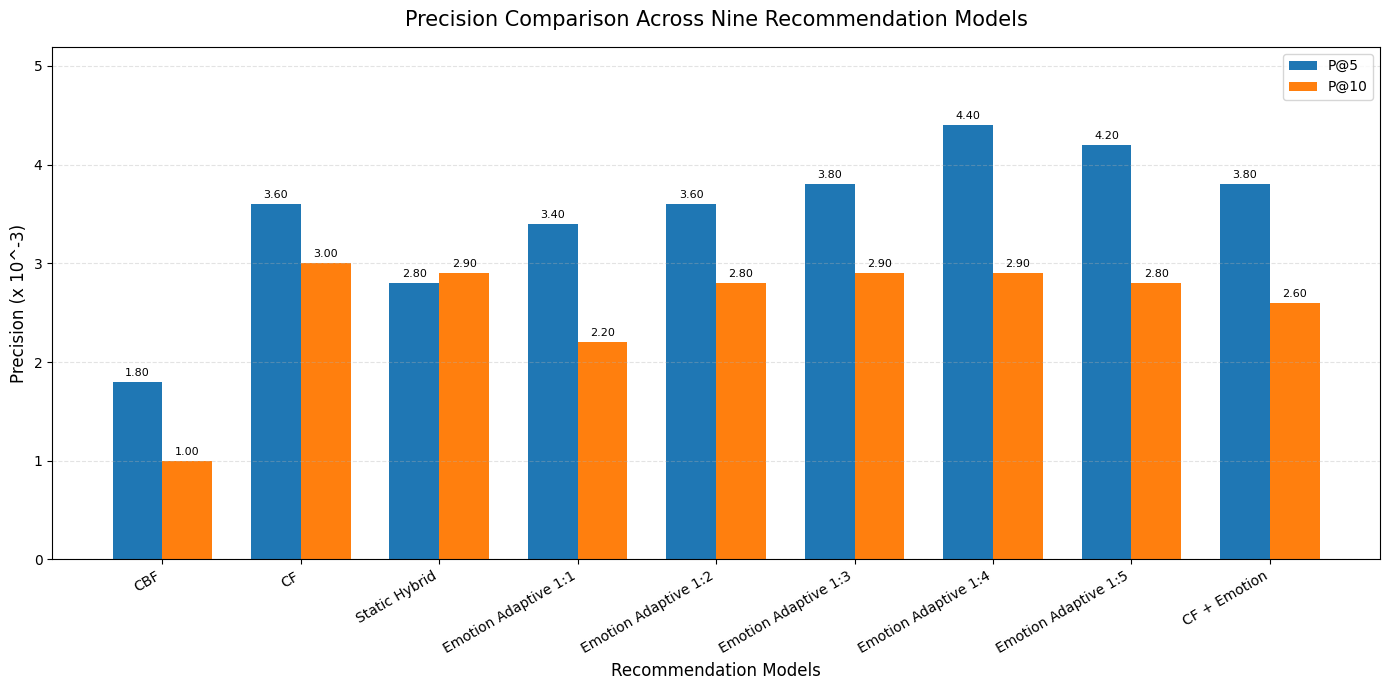

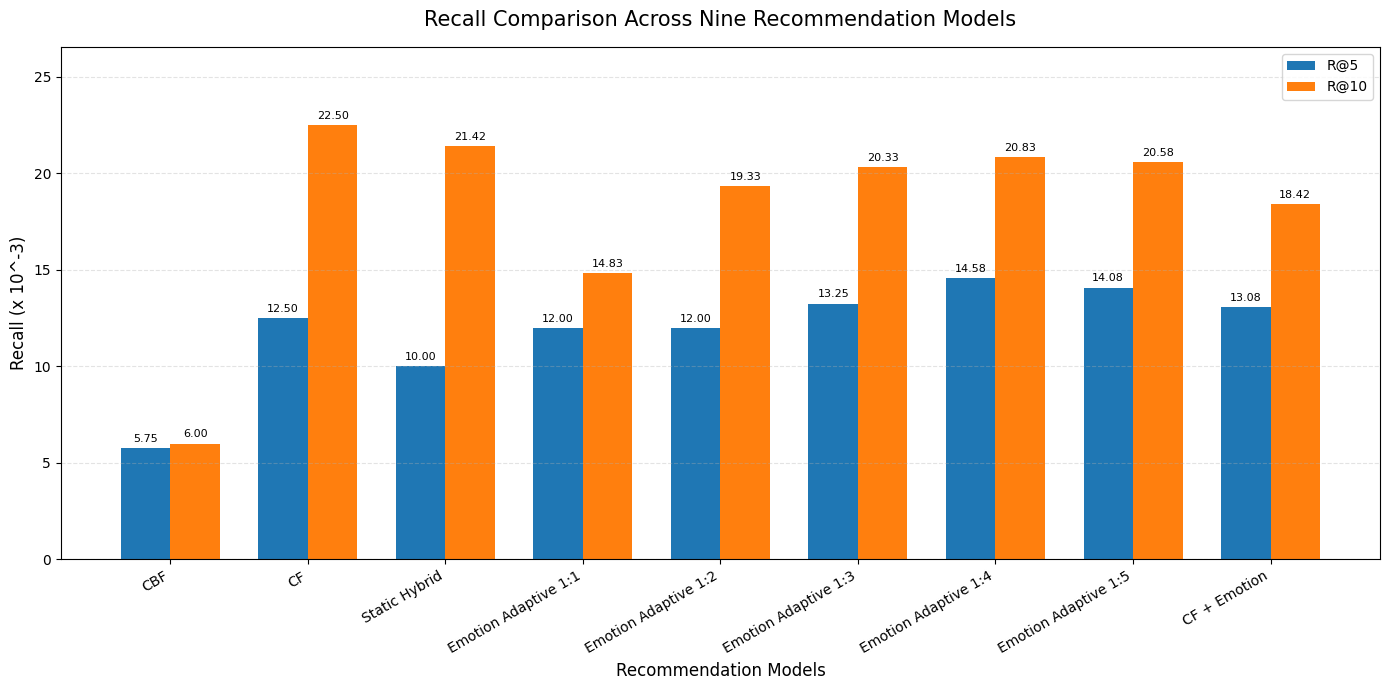

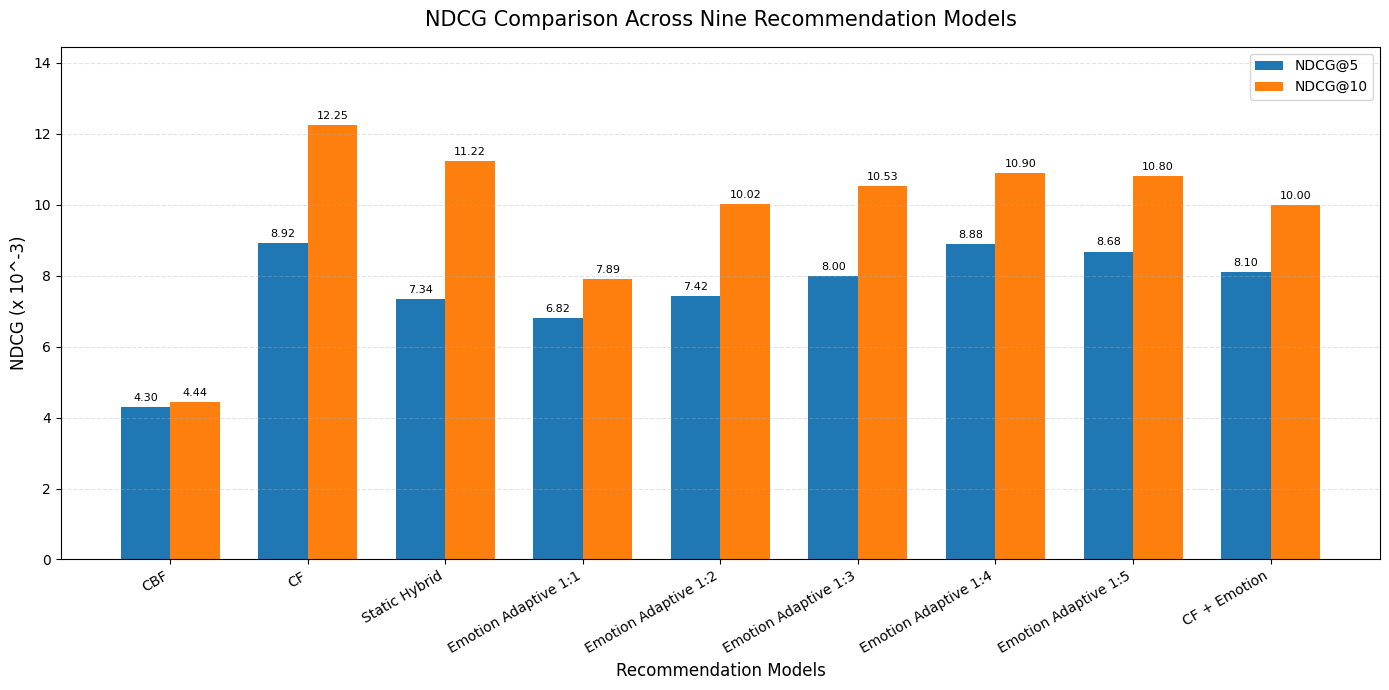

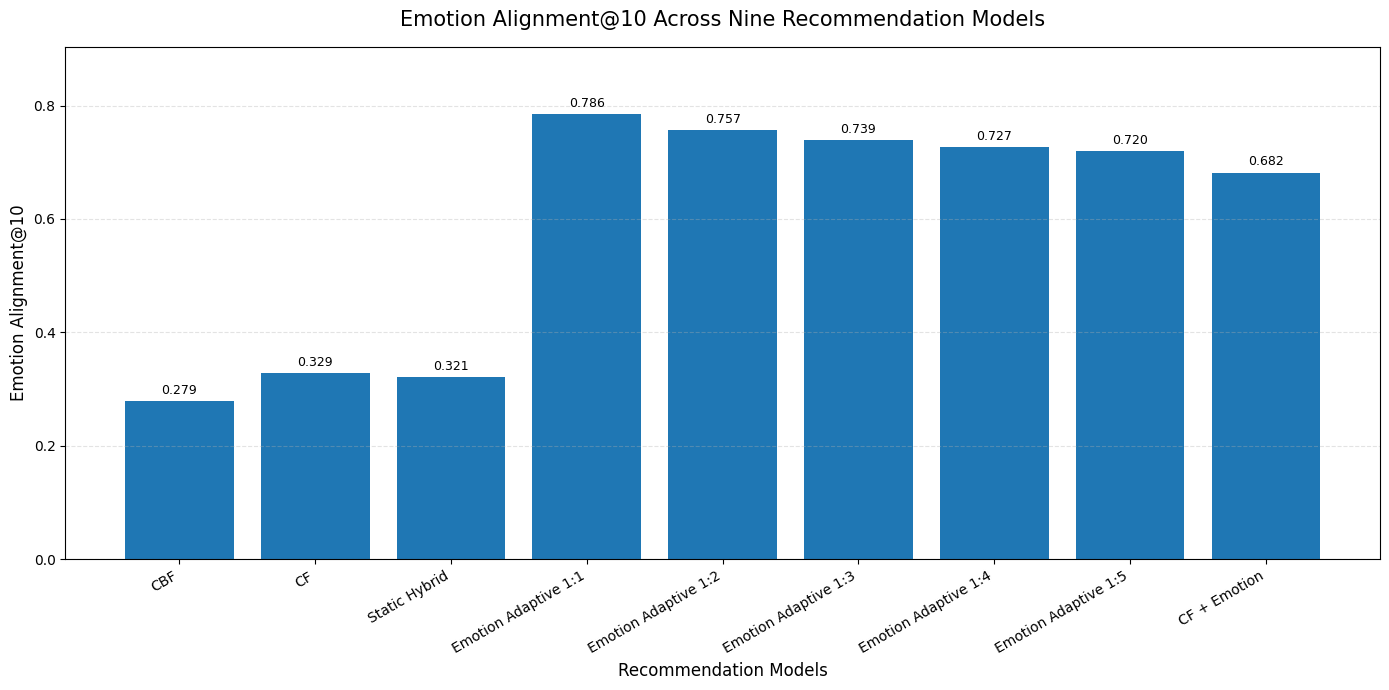

===== MODEL WEIGHT CONFIGURATIONS =====


,Model,CBF_Weight,CF_Weight,Emotion_Weight
0,Static Hybrid,0.500000,0.500000,0.000000
1,Emotion Adaptive 1:1,0.422194,0.422194,0.155612
2,Emotion Adaptive 1:2,0.281463,0.562925,0.155612
3,Emotion Adaptive 1:3,0.211097,0.633291,0.155612
4,Emotion Adaptive 1:4,0.168878,0.675510,0.155612
5,Emotion Adaptive 1:5,0.140731,0.703656,0.155612
6,CF + Emotion,0.000000,0.844388,0.155612



All paper figures and tables generated.
Output directory: paper_final_figures

Generated figures:
1. Precision comparison
2. Recall comparison
3. NDCG comparison
4. Emotion alignment comparison

Generated tables:
1. Nine-model performance
2. Model weight configurations
3. Emotion alignment


In [ ]:

# ============================================================
# FINAL PAPER FIGURES AND TABLES
# Nine-model comparison
# Add after Cell 264
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ------------------------------------------------------------
# 1. VERIFY REQUIRED EXPERIMENT RESULTS
# ------------------------------------------------------------

required_objects = [
    "four_model_results",
    "cf_prioritized_results",
    "cf_3to1_results",
    "cf_4to1_results",
    "cf_5to1_results",
    "cf_emotion_results"
]

for name in required_objects:
    if name not in globals():
        raise NameError(
            f"{name} is missing. Run the corresponding experiment cell first."
        )

# ------------------------------------------------------------
# 2. BUILD CONSOLIDATED NINE-MODEL RESULTS
# ------------------------------------------------------------

def mean_value(df, column):
    if column not in df.columns:
        raise KeyError(f"Missing column: {column}")
    return float(df[column].mean())


model_results = {
    "CBF": {
        "data": four_model_results,
        "prefix": "CBF_"
    },
    "CF": {
        "data": four_model_results,
        "prefix": "CF_"
    },
    "Static Hybrid": {
        "data": four_model_results,
        "prefix": "Static_Hybrid_"
    },
    "Emotion Adaptive 1:1": {
        "data": four_model_results,
        "prefix": "Emotion_Adaptive_"
    },
    "Emotion Adaptive 1:2": {
        "data": cf_prioritized_results,
        "prefix": ""
    },
    "Emotion Adaptive 1:3": {
        "data": cf_3to1_results,
        "prefix": ""
    },
    "Emotion Adaptive 1:4": {
        "data": cf_4to1_results,
        "prefix": ""
    },
    "Emotion Adaptive 1:5": {
        "data": cf_5to1_results,
        "prefix": ""
    },
    "CF + Emotion": {
        "data": cf_emotion_results,
        "prefix": ""
    }
}

metric_names = [
    "P@5", "R@5", "NDCG@5",
    "P@10", "R@10", "NDCG@10",
    "EmotionAlignment@10"
]

rows = []

for model_name, info in model_results.items():

    df = info["data"]
    prefix = info["prefix"]

    row = {"Model": model_name}

    for metric in metric_names:
        column = prefix + metric
        row[metric] = mean_value(df, column)

    rows.append(row)

model_comparison_df = pd.DataFrame(rows)

print("===== COMPLETE NINE-MODEL COMPARISON =====")
display(model_comparison_df.round(6))

# Verify that all nine models are represented
assert len(model_comparison_df) == 9
assert model_comparison_df["Model"].nunique() == 9

# ------------------------------------------------------------
# 3. CREATE OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = "paper_final_figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 4. HELPER FUNCTION FOR PUBLICATION FIGURES
# ------------------------------------------------------------

def create_comparison_figure(
    metric_1,
    metric_2,
    title,
    ylabel,
    filename,
    scale=1000
):

    x = np.arange(len(model_comparison_df))
    width = 0.36

    values_1 = model_comparison_df[metric_1].values * scale
    values_2 = model_comparison_df[metric_2].values * scale

    fig, ax = plt.subplots(figsize=(14, 7))

    bars1 = ax.bar(
        x - width / 2,
        values_1,
        width,
        label=metric_1
    )

    bars2 = ax.bar(
        x + width / 2,
        values_2,
        width,
        label=metric_2
    )

    ax.set_title(title, fontsize=15, pad=15)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_xlabel("Recommendation Models", fontsize=12)

    ax.set_xticks(x)
    ax.set_xticklabels(
        model_comparison_df["Model"],
        rotation=30,
        ha="right"
    )

    ax.legend(fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.35)

    ax.bar_label(
        bars1,
        fmt="%.2f",
        padding=3,
        fontsize=8
    )

    ax.bar_label(
        bars2,
        fmt="%.2f",
        padding=3,
        fontsize=8
    )

    ax.margins(y=0.18)
    plt.tight_layout()

    fig.savefig(
        os.path.join(OUTPUT_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 5. FIGURE 1: PRECISION COMPARISON
# ------------------------------------------------------------

create_comparison_figure(
    metric_1="P@5",
    metric_2="P@10",
    title="Precision Comparison Across Nine Recommendation Models",
    ylabel="Precision (x 10^-3)",
    filename="Figure_1_Precision_Comparison.png",
    scale=1000
)

# ------------------------------------------------------------
# 6. FIGURE 2: RECALL COMPARISON
# ------------------------------------------------------------

create_comparison_figure(
    metric_1="R@5",
    metric_2="R@10",
    title="Recall Comparison Across Nine Recommendation Models",
    ylabel="Recall (x 10^-3)",
    filename="Figure_2_Recall_Comparison.png",
    scale=1000
)

# ------------------------------------------------------------
# 7. FIGURE 3: NDCG COMPARISON
# ------------------------------------------------------------

create_comparison_figure(
    metric_1="NDCG@5",
    metric_2="NDCG@10",
    title="NDCG Comparison Across Nine Recommendation Models",
    ylabel="NDCG (x 10^-3)",
    filename="Figure_3_NDCG_Comparison.png",
    scale=1000
)

# ------------------------------------------------------------
# 8. FIGURE 4: EMOTION ALIGNMENT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

alignment_values = (
    model_comparison_df["EmotionAlignment@10"].values
)

bars = ax.bar(
    model_comparison_df["Model"],
    alignment_values
)

ax.set_title(
    "Emotion Alignment@10 Across Nine Recommendation Models",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Recommendation Models", fontsize=12)
ax.set_ylabel("Emotion Alignment@10", fontsize=12)

ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=3,
    fontsize=9
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.margins(y=0.15)

plt.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Figure_4_Emotion_Alignment.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. TABLE: MODEL WEIGHT CONFIGURATIONS
# ------------------------------------------------------------

R_FINAL = 0.389031
GAMMA_MAX = 0.40

gamma = GAMMA_MAX * R_FINAL

weight_rows = [
    {
        "Model": "Static Hybrid",
        "CBF_Weight": 0.50,
        "CF_Weight": 0.50,
        "Emotion_Weight": 0.00
    },
    {
        "Model": "Emotion Adaptive 1:1",
        "CBF_Weight": (1-gamma)/2,
        "CF_Weight": (1-gamma)/2,
        "Emotion_Weight": gamma
    }
]

for ratio in [2, 3, 4, 5]:

    weight_rows.append({
        "Model": f"Emotion Adaptive 1:{ratio}",
        "CBF_Weight": (1-gamma)/(ratio+1),
        "CF_Weight": ratio*(1-gamma)/(ratio+1),
        "Emotion_Weight": gamma
    })

weight_rows.append({
    "Model": "CF + Emotion",
    "CBF_Weight": 0.0,
    "CF_Weight": 1-gamma,
    "Emotion_Weight": gamma
})

weights_df = pd.DataFrame(weight_rows)

print("===== MODEL WEIGHT CONFIGURATIONS =====")
display(weights_df.round(6))

# ------------------------------------------------------------
# 10. SAVE PAPER TABLES
# ------------------------------------------------------------

model_comparison_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_1_Nine_Model_Performance.csv"
    ),
    index=False
)

weights_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_2_Model_Weight_Configurations.csv"
    ),
    index=False
)

# Separate emotion alignment table
alignment_table = model_comparison_df[
    ["Model", "EmotionAlignment@10"]
].copy()

alignment_table.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Table_3_Emotion_Alignment.csv"
    ),
    index=False
)

print("\nAll paper figures and tables generated.")
print("Output directory:", OUTPUT_DIR)

print("\nGenerated figures:")
print("1. Precision comparison")
print("2. Recall comparison")
print("3. NDCG comparison")
print("4. Emotion alignment comparison")

print("\nGenerated tables:")
print("1. Nine-model performance")
print("2. Model weight configurations")
print("3. Emotion alignment")


In [ ]:

import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import files

# ==========================================
# 1. CREATE OUTPUT FOLDER
# ==========================================

OUTPUT = Path("/content/Final_Paper_Results")
FIGURES = OUTPUT / "Figures"
TABLES = OUTPUT / "Tables"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. SAVE ALL CURRENTLY OPEN DIAGRAMS
# ==========================================

figure_count = 0

for fig_num in plt.get_fignums():
    fig = plt.figure(fig_num)
    figure_count += 1

    fig.savefig(
        FIGURES / f"Figure_{figure_count}.png",
        dpi=300,
        bbox_inches="tight"
    )

print(f"Saved {figure_count} open figures.")

# ==========================================
# 3. SAVE RELEVANT EXPERIMENT TABLES
# ==========================================

keywords = [
    "four_model_results",
    "cf_prioritized_results",
    "cf_3to1_results",
    "cf_4to1_results",
    "cf_5to1_results",
    "cf_emotion_results",
    "nine_model",
    "emotion_alignment",
    "model_weights",
    "comparison",
    "statistical"
]

saved_tables = {}

for var_name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if any(key in var_name.lower() for key in keywords):
            safe_name = "".join(
                c if c.isalnum() or c in "_-" else "_"
                for c in var_name
            )

            saved_tables[safe_name] = obj.copy()
            obj.to_csv(TABLES / f"{safe_name}.csv", index=False)

print(f"Saved {len(saved_tables)} experiment tables.")

# ==========================================
# 4. CREATE ONE EXCEL WORKBOOK
# ==========================================

if saved_tables:
    excel_path = TABLES / "All_Experiment_Tables.xlsx"

    with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
        for name, df in saved_tables.items():
            df.to_excel(
                writer,
                sheet_name=name[:31],
                index=False
            )

# ==========================================
# 5. INCLUDE PREVIOUSLY SAVED PNG DIAGRAMS
# ==========================================

# Copy PNG files from the earlier figure folder,
# if that folder exists.

possible_folders = [
    Path("/content/paper_final_figures"),
    Path("/content/paper_figures"),
    Path("/content")

]

for folder in possible_folders:
    if folder.exists():
        for img in folder.glob("*.png"):
            destination = FIGURES / img.name

            if img.resolve() != destination.resolve():
                import shutil
                shutil.copy2(img, destination)

# ==========================================
# 6. CREATE ZIP
# ==========================================

zip_path = Path("/content/All_Paper_Diagrams_and_Tables.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file_path in OUTPUT.rglob("*"):
        if file_path.is_file():
            z.write(file_path, file_path.relative_to(OUTPUT))

# ==========================================
# 7. VERIFY ZIP CONTENTS
# ==========================================

with zipfile.ZipFile(zip_path, "r") as z:
    contents = [n for n in z.namelist() if not n.endswith("/")]

    print("\n========== ZIP CONTENTS ==========")

    for name in contents:
        print(name)

    print("\nTotal files:", len(contents))

    if not contents:
        raise RuntimeError("ZIP is empty. Check whether your figures and tables were generated.")

# ==========================================
# 8. DIRECT DOWNLOAD TO YOUR COMPUTER
# ==========================================

files.download(str(zip_path))


Saved 0 open figures.
Saved 25 experiment tables.

========== ZIP CONTENTS ==========
Tables/cf_emotion_results.csv
Tables/baseline_comparison_df.csv
Tables/new_statistical_df.csv
Tables/statistical_summary.csv
Tables/statistical_df.csv
Tables/weight_comparison_df.csv
Tables/comparison_5to1_df.csv
Tables/statistical_5to1_df.csv
Tables/four_model_results.csv
Tables/cf_prioritized_results.csv
Tables/comparison_3to1_df.csv
Tables/statistical_4to1_df.csv
Tables/final_baseline_comparison.csv
Tables/reliability_ranking_comparison.csv
Tables/cf_4to1_results.csv
Tables/paper_statistical_table.csv
Tables/cf_5to1_results.csv
Tables/comparison_df.csv
Tables/baseline_comparison.csv
Tables/statistical_3to1_df.csv
Tables/cf_emotion_comparison.csv
Tables/emotion_alignment_df.csv
Tables/All_Experiment_Tables.xlsx
Tables/comparison_4to1_df.csv
Tables/cf_3to1_results.csv
Tables/model_comparison_df.csv
Figures/figure_baseline_performance_k10.png
Figures/Figure_1_Precision_Comparison.png
Figures/Figure_2_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>